<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">
<br>
<h1 style="font-family:verdana; font-size:26px"><center>~ LOGIKA UI 2026: Prediksi Gagal Bayar 12 Bulan ~</center></h1>
<h3 style="font-family:verdana; font-size:14px; color:gray"><center>Ensemble peringkat regresi logistik, LightGBM, dan XGBoost di atas fitur mekanisme (harga relatif, dinamika antrian tunggakan, belanja kebutuhan dasar), divalidasi DeLong, diaudit terhadap kebocoran, dan ditutup dengan paket privat S8 + LightGBM hibrida yang dapat direproduksi dari data panitia</center></h3>
<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# **DSC0082_Hypomone_Privat**

Tim **Hypomone** · Data Science Competition LOGIKA UI 2026 · notebook final untuk juri. Seluruh angka di notebook ini berasal dari output run notebook ini sendiri, kecuali angka yang diberi label sumber run terdahulu.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 1. Ringkasan Eksekutif <a name="bab1"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## 1.1 Pendekatan dan Resource <a name="bab1-1"></a>

**Pendekatan dalam lima kalimat.** (1) Gagal bayar diprediksi dari enam sumber data panitia yang semuanya dipotong pada `decision_datetime`, dengan fitur yang mewakili **mekanisme** pembentuk risiko, bukan sekadar agregat. (2) Tiga mekanisme terbukti membawa informasi terbesar: penetapan harga berbasis risiko (bunga), efek harga nasabah dalam belanja e-commerce, dan antrian tunggakan FIFO pada pinjaman lama. (3) Tiga anggota model (regresi logistik dengan interaksi antar-laten, LightGBM tiga pembagian *fold* ditambah *refit*, dan XGBoost) digabung di ruang peringkat dengan bobot *cross-fit*, lalu dikalibrasi Platt dan dikoreksi efek angkatan keputusan. (4) Setiap perubahan diterima hanya bila uji DeLong berpasangan pada *fold* yang sama memberi z > 2, karena KS terlalu berderau untuk memilih model. (5) Data diaudit dengan 48 uji kebocoran yang dipra-registrasi (0 positif), dan satu-satunya sumber sah baru yang ditemukan audit, belanja kebutuhan dasar nasabah *thin-file*, diuji di notebook ini dengan gerbang yang sama. (6) Bab 13 membangun **paket privat**: S8 (S7 + RealMLP + TabM pada X7, Bagian 22) dilatih ulang dari data panitia dan digabung dengan LightGBM hibrida LR → `t9x` (Bagian 35). Uji lokal: AUC 0,84915 / KS 0,5299, ΔAUC +0,00022 (z +2,73) vs S8. `submission.csv` = paket S8 + hibrida bila z > 2 vs S8, selain itu S8; dua pilihan final privat tetap dipilih manual di Kaggle.

**Resource.** Kaggle Notebook CPU, hanya data kompetisi, tanpa *cache* dan tanpa Internet. Waktu run penuh: <<WAKTU_TOTAL>>.

**Anggota yang tidak dijalankan ulang.** Submisi privat utama adalah S8 (S7 + RealMLP + TabM), AUC OOF 0,8489, yang tereproduksi identik dua kali di notebook lama Bagian 22 (run Kaggle 21 dan 22 Oktober 2026, CLAUDE.md Submission 8 dan 9). RealMLP dan TabM butuh GPU dan ±3 jam, sehingga tidak dimasukkan ke notebook ini agar notebook selesai di Kaggle CPU. Berkas privat S8 tetap berkas run (3). Notebook ini menjalankan ulang S7 dari data mentah dan menguji fitur *groceries* di atasnya.

## 1.2 Temuan → Keputusan → Rujukan <a name="bab1-2"></a>

| Temuan | Keputusan | Rujukan |
| --- | --- | --- |
| Split latih–uji acak pada periode yang sama; validasi adversarial AUC <<ADV_AUC>> | `StratifiedKFold` 5 lipatan, acak | §6.2 |
| KS tak berubah oleh transformasi monoton dan berderau (SE ±0,004) | Keputusan memakai DeLong berpasangan atas AUC; KS hanya dilaporkan | DeLong dkk. (1988); §6.3 |
| Bunga naik dari <<BUNGA_RENDAH>> ke <<BUNGA_TINGGI>> diikuti default <<DEF_RENDAH>> → <<DEF_TINGGI>> | Bunga dan anuitas sebagai fitur inti | §5.3 |
| <<PORSI_THIN>> nasabah *thin-file*, default <<DEF_THIN>> vs berhistori <<DEF_HIST>> | Semua uji dilaporkan per segmen | §5.4 |
| Tiga provider biro berkorelasi <<KOR_BIRO>> | Skor biro dirata-ratakan antar-provider (`bp_*`) | §5.5 |
| Pembayaran cicilan berupa antrian FIFO pada jadwal bulanan | Fitur dinamika tunggakan `q_*`/`ep_*` | §5.6, §7.4 |
| Pesanan melonjak <<LONJAKAN>> pada hari-hari terakhir sebelum pengajuan | Fitur jendela waktu dan lonjakan relatif | §5.7 |
| Log harga item = efek kategori×bulan + efek nasabah | Efek harga nasabah `pr_*` dengan referensi statis 2023–2024 | §5.8, §7.8 |
| Residual heterogen menurut waktu keputusan | Koreksi angkatan keputusan kernel Nadaraya–Watson *cross-fit* | §9.2 |
| Reproduksi S7 dari data mentah: AUC <<S7_AUC>>, Spearman uji <<S7_RHO>> | Pipeline final = S7 | §9.3 |
| Audit 48 uji: 0 positif; belanja *groceries* thin Rao z +4,50 (run lokal 24 Oktober 2026, CLAUDE.md Bagian 29) | Fitur `ek_groc_*` diuji dengan gerbang DeLong | §10, §11 |
| Gerbang *groceries*: ΔAUC <<GROC_DAUC>>, z <<GROC_Z>> | `submission.csv` = <<PILIHAN_FINAL>> | §11.5 |

## 1.3 Seluruh Submisi dan Keputusan Final <a name="bab1-3"></a>

| Submisi | Isi utama | AUC OOF | KS publik | Status |
| --- | --- | --- | --- | --- |
| S1 | Fondasi: agregat enam sumber, LR + LightGBM + XGBoost | 0,8372 | 0,54453 | tidak dipakai |
| S2 | Efek harga nasabah, buang 15 fitur derau | 0,8457 | 0,56572 | tidak dipakai |
| S3 | Interaksi antar-laten, LightGBM *repeated CV* | 0,8465 | 0,56423 | tidak dipakai |
| S4 | Referensi harga statis, koreksi angkatan keputusan | 0,8472 | 0,56892 / 0,57015 | tidak dipakai |
| S5–S6 | Snapshot guru, FT-Transformer, multi-seed, CatBoost | 0,8472–0,8474 | 0,56875 | tidak dipakai |
| S7 (DSC0082) | S4 + dinamika tunggakan | 0,8487 | 0,56514 | **privat cadangan** |
| S8 | S7 + RealMLP + TabM | 0,8489 | — | **privat utama** |
| s4nn | S4 + RealMLP + TabM | 0,8474 | 0,57105 | tidak dipakai (publik tertinggi) |
| Final notebook ini | S7 dari data mentah ± `ek_groc_*` | <<FINAL_AUC>> | belum dikirim | <<STATUS_FINAL>> |

Angka S1–s4nn berasal dari run terdahulu (CLAUDE.md Submission 1–8). **Keputusan final privat: S8 + S7.** Keduanya punya AUC OOF tertinggi (0,8489 dan 0,8487), dan nilai harapan maksimum KS privat pasangan ini +0,00038 di atas S8 saja (analisis matematis 23 Oktober 2026, CLAUDE.md Bagian 26). Skor publik tidak dipakai untuk memilih, karena selisih publik antarberkas berada di dalam derau subset 9.000 baris (SD selisih berpasangan ±0,003) dan keberuntungan publik tidak terbawa ke privat (korelasi −0,05; analisis 20 Oktober 2026). Kaggle harus diatur **manual** memilih S8 dan S7; bila dibiarkan, Kaggle memilih dua skor publik tertinggi (s4nn dan S4) yang privatnya lebih lemah. <<KALIMAT_GROC>>

## 1.4 Asumsi dan Batasan <a name="bab1-4"></a>

1. Data uji berasal dari periode dan proses yang sama dengan data latih, sehingga koreksi angkatan keputusan sah dipakai; koreksi ini tidak berlaku untuk periode baru.
2. Plafon informasi: kurva belajar memberi asimtot AUC model tunggal ±0,854 (run terdahulu, CLAUDE.md Pencarian Informasi Pasca-S5), sehingga skor publik teratas 0,61 (setara AUC ±0,87) tidak dapat dicapai secara sah dan paling mungkin merupakan derau subset ditambah seleksi.
3. Nasabah *thin-file* tertinggal ±0,02 AUC dari nasabah berhistori; celah ini adalah celah informasi, bukan estimasi.
4. Fitur *groceries* hanya memakai transaksi e-commerce panitia berstatus *completed* hingga `decision_datetime` dan telah dikonfirmasi sah oleh tim terhadap aturan panitia.

# 2. Daftar Isi <a name="bab2"></a>

1. [**Ringkasan Eksekutif**](#bab1): pendekatan, temuan → keputusan, seluruh submisi, keputusan final.
2. [**Daftar Isi**](#bab2)
3. [**Pendahuluan**](#bab3): kompetisi dan metrik, dataset, skema relasional, aturan *point-in-time*, segmen.
4. [**Inisialisasi**](#bab4): environment, konfigurasi, log, gaya tabel dan grafik, pemuatan data.
5. [**Analisis Data Eksploratif**](#bab5): delapan temuan yang masing-masing menghasilkan satu keputusan pemodelan.
6. [**Desain Validasi**](#bab6): *fold*, validasi adversarial, alat uji dan kapan dipakai.
7. [**Rekayasa Fitur**](#bab7): sepuluh keluarga fitur dan perakitan matriks X7.
8. [**Pemodelan**](#bab8): tiga anggota, *scoreboard*, kepentingan fitur.
9. [**Ensemble dan Kalibrasi**](#bab9): *rank blend cross-fit*, Platt, koreksi angkatan keputusan, reproduksi S7.
10. [**Audit Forensik Kebocoran**](#bab10): ringkasan 48 uji A–C dan uji sumber D–F (run terdahulu).
11. [**Fitur Groceries Thin-File**](#bab11): hipotesis, pra-registrasi, uji Rao, latih ulang, gerbang DeLong.
12. [**Submisi**](#bab12): dua berkas, asersi format, keputusan `submission.csv`, *manifest*.
13. [**Paket Privat**](#bab13): LightGBM hibrida LR → `t9x` pada X7, RealMLP + TabM (S8 dibangun ulang), paket S8 + hibrida, gerbang, `submission.csv`.
14. [**Riwayat Iterasi**](#bab14): S1 sampai final dalam satu tabel.
15. [**Pasca-Analisis**](#bab15): kurva KS, kelebihan, keterbatasan, arah.
16. [**Daftar Pustaka**](#bab16)
17. [**Ucapan Terima Kasih**](#bab17)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 3. Pendahuluan <a name="bab3"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## 3.1 Kompetisi dan Metrik <a name="bab3-1"></a>

Sebuah lembaga pembiayaan konsumen harus memutuskan, pada satu titik waktu `decision_datetime`, apakah pengajuan pinjaman bertenor 12 bulan layak disetujui. Peserta diminta mengestimasi peluang pinjaman mencapai *days past due* (DPD) 90 hari dalam 12 bulan. Skor yang dinilai adalah statistik Kolmogorov–Smirnov dua sampel antara skor nasabah gagal bayar ($F_1$) dan lancar ($F_0$):

$$\mathrm{KS} = \sup_{s}\,\big|F_1(s) - F_0(s)\big| = \max_{t}\,\big(\mathrm{TPR}(t) - \mathrm{FPR}(t)\big).$$

Tiga konsekuensi menentukan desain notebook ini: (1) hanya urutan yang dinilai, sehingga kalibrasi tidak mengubah skor dan penggabungan dilakukan di ruang peringkat; (2) log-loss adalah pengganti konsisten karena urutan menurut $P(y=1\mid x)$ memaksimalkan KS populasi (lemma Neyman–Pearson); (3) $\mathrm{Gini} = 2\,\mathrm{AUC} - 1 \le \mathrm{KS}\,(2 - \mathrm{KS})$, sehingga AUC dan KS bergerak bersama dan AUC, yang jauh kurang berderau, menjadi besaran keputusan. Papan peringkat publik memakai 30% data uji (±9.000 baris), privat 70%.

## 3.2 Dataset dan Skema Relasional <a name="bab3-2"></a>

Panitia menyediakan sembilan berkas yang membentuk skema bintang berpusat pada nasabah. Setiap nasabah memiliki tepat satu aplikasi terpilih, sehingga `customer_id` menjadi kunci tunggal sesudah agregasi. Jumlah baris setiap berkas dicetak dari data di §4.4.

| Berkas | Kunci relasi | Isi |
| --- | --- | --- |
| `train_applications.csv` | `application_id`, `customer_id` | aplikasi terpilih + `target` |
| `test_applications.csv` | `application_id`, `customer_id` | aplikasi terpilih tanpa label |
| `customer_profiles.csv` | `customer_id` | demografi dan pendapatan deklarasi |
| `previous_applications.csv` | `application_id`, `customer_id`, `loan_id` | riwayat pengajuan sebelum keputusan |
| `repayment_history.csv` | `loan_id`, `installment_id`, `customer_id` | cicilan pinjaman lama beserta DPD |
| `account_behavior.csv` | `customer_id`, `month` | arus kas rekening bulanan |
| `bureau_observations.csv` | `application_id`, `customer_id` | laporan tiga biro kredit |
| `ecommerce_transactions.csv` | `order_id`, `order_item_id`, `customer_id` | transaksi e-commerce tingkat item |
| `sample_submission.csv` | `application_id` | format `default_probability` (urutan ≠ `test_applications`) |

```
customer_profiles ──┐
                    ├── train/test_applications (1 aplikasi per nasabah, batas = decision_datetime)
previous_applications ──┤
   └── repayment_history (loan_id)
bureau_observations (application_id: aplikasi kini maupun aplikasi lama)
account_behavior (customer_id × bulan)      ecommerce_transactions (customer_id × pesanan × item)
```

## 3.3 Aturan *Point-in-Time* dan Segmen <a name="bab3-3"></a>

| Aturan | Implementasi |
| --- | --- |
| Hanya data panitia | Seluruh fitur dari sembilan berkas di atas, tanpa sumber eksternal |
| Batas informasi | Setiap fungsi fitur memfilter `timestamp <= decision_datetime` **dan** mengasersi tidak ada baris yang lolos |
| Biro | Laporan dipakai bila `available_datetime <= decision_datetime` |
| Rekening | Bulan dipakai hanya bila akhir bulannya `<= decision_datetime` |
| Pinjaman lama | Sisa kewajiban dari jadwal kontraktual yang diketahui saat keputusan |
| ID | Hanya kunci *join*, bukan fitur numerik |
| Prapemrosesan | Imputasi, skala, bobot ensemble, kalibrasi, dan koreksi waktu dipasang di dalam *fold* |

**Segmen.** Nasabah **berhistori** punya minimal satu aplikasi lama; nasabah ***thin-file*** tidak punya aplikasi lama, cicilan, rekening, maupun biro historis, dan hanya punya profil, aplikasi kini, laporan biro saat keputusan, dan e-commerce. Semua hasil dilaporkan untuk kedua segmen.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 4. Inisialisasi <a name="bab4"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## 4.1 Environment dan Pustaka <a name="bab4-1"></a>

Apakah lingkungan run sama dengan yang dipakai untuk keputusan? Versi Python dan pustaka dicetak dan disimpan di *manifest*, karena run S4 yang sama memberi skor publik 0,56892 di laptop dan 0,57015 di Kaggle hanya karena versi pustaka dan jumlah *thread* berbeda (CLAUDE.md Submission 6). Peringatan pustaka dimatikan agar output hanya berisi hasil. Perkiraan waktu bab: <<WAKTU_EST_4>>.

In [1]:
import gc
import hashlib
import json
import logging
import os
import platform
import random
import sys
import time
import warnings
from dataclasses import asdict, dataclass
from itertools import product
from pathlib import Path

import lightgbm as lgb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import xgboost as xgb
from IPython.display import Markdown, display
from scipy.stats import chi2, ks_2samp, norm, rankdata, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 40)
RUN_T0 = time.time()
VERSI = {'python': sys.version.split()[0], 'platform': platform.platform(),
         **{m.__name__: m.__version__ for m in (np, pd, sklearn, scipy, lgb, xgb, matplotlib)}}
print(' | '.join(f'{k} {v}' for k, v in VERSI.items()))

python 3.13.15 | platform Linux-6.18.55+-x86_64-with-glibc2.39 | numpy 2.1.3 | pandas 2.3.3 | sklearn 1.6.1 | scipy 1.16.3 | lightgbm 4.6.0 | xgboost 3.4.1 | matplotlib 3.10.0


> ### Insights
>
> <<INS_4_1>>

## 4.2 Konfigurasi dan Seed <a name="bab4-2"></a>

Semua parameter yang memengaruhi hasil (seed, jumlah *fold*, ronde, laju belajar, regularisasi, jumlah *thread*) dikumpulkan di satu `Config` agar run dapat diulang persis. Profil `smoke` menjalankan subsampel untuk uji jalur kode; profil `full` adalah run final. Direktori data dicari otomatis di `/kaggle/input` atau lewat env `LOGIKA_DATA_DIR`.

In [2]:
PROFILE = 'full'


@dataclass
class Config:
    data_dir: Path = Path('.')
    out_dir: Path = Path('/kaggle/working')
    seed: int = 42
    n_folds: int = 5
    lgb_seed: int = 42
    lgb_rounds: int = 6000
    xgb_rounds: int = 6000
    early_stopping: int = 250
    learning_rate: float = 0.03
    logreg_c: float = 0.05
    n_jobs: int = os.cpu_count() or 4
    bootstrap: int = 300
    extra_split_seeds: tuple = (2026, 7)
    h_best: int = 14          # bandwidth kernel NW (hari), dipilih pada paket S4 (run Kaggle 19 Oktober 2026, CLAUDE.md Submission 4)
    select_z: float = 2.0
    s7_auc_ref: float = 0.8487
    s7_auc_tol: float = 0.0003
    s7_rho_min: float = 0.999


def seed_everything(seed: int) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)


def find_data_dir() -> Path:
    env = os.environ.get('LOGIKA_DATA_DIR')
    roots = ([Path(env)] if env else []) + [Path('/kaggle/input'), Path('data'), Path('../data'), Path('.')]
    for root in roots:
        if root.exists():
            hits = sorted(root.rglob('train_applications.csv'))
            if hits:
                return hits[0].parent
    raise FileNotFoundError('train_applications.csv tidak ditemukan; tambahkan data kompetisi sebagai input')


CFG = Config()
if PROFILE == 'smoke':
    CFG.lgb_rounds = CFG.xgb_rounds = 300
    CFG.bootstrap = 40
    CFG.extra_split_seeds = (2026,)
seed_everything(CFG.seed)
CFG.data_dir = find_data_dir()
if not Path('/kaggle/working').exists():
    CFG.out_dir = Path(os.environ.get('LOGIKA_OUT_DIR', 'outputs'))
CFG.out_dir.mkdir(parents=True, exist_ok=True)
print(f'profil {PROFILE} | data {CFG.data_dir} | keluaran {CFG.out_dir} | thread {CFG.n_jobs}')
print('Config:', {k: str(v) for k, v in asdict(CFG).items() if k not in ('data_dir', 'out_dir')})

profil full | data /kaggle/input/competitions/data-science-competition-logika-ui-2026 | keluaran /kaggle/working | thread 4
Config: {'seed': '42', 'n_folds': '5', 'lgb_seed': '42', 'lgb_rounds': '6000', 'xgb_rounds': '6000', 'early_stopping': '250', 'learning_rate': '0.03', 'logreg_c': '0.05', 'n_jobs': '4', 'bootstrap': '300', 'extra_split_seeds': '(2026, 7)', 'h_best': '14', 'select_z': '2.0', 's7_auc_ref': '0.8487', 's7_auc_tol': '0.0003', 's7_rho_min': '0.999'}


> ### Insights
>
> <<INS_4_2>>

## 4.3 Log, Tabel, dan Grafik <a name="bab4-3"></a>

Agar output seragam dan dapat diaudit, semua pesan ditulis sekaligus ke layar dan ke `run_final.log`, setiap tabel ditampilkan dengan format Indonesia (koma desimal, titik ribuan) lewat satu fungsi `tampil_tabel`, dan setiap grafik memakai satu gaya (palet turunan warna banner #8E7B6B, 10 × 4 inci, label bahasa Indonesia) lewat `gaya_grafik`.

In [3]:
log = logging.getLogger('final')
log.handlers.clear(); log.setLevel(logging.INFO); log.propagate = False
for h in (logging.StreamHandler(sys.stdout), logging.FileHandler(CFG.out_dir / 'run_final.log', mode='w', encoding='utf-8')):
    h.setFormatter(logging.Formatter('%(message)s')); log.addHandler(h)
LOG_BERKAS = log.handlers[1]
PALET = {'utama': '#8E7B6B', 'aksen1': '#B5523B', 'aksen2': '#3E6E8E', 'lembut': '#C9B79C'}
WAKTU, _T_BAB = {}, [RUN_T0]


def catat(pesan):
    """Satu baris log ke layar dan ke run_final.log."""
    log.info(pesan)


def angka_id(v, desimal=4):
    """Format angka Indonesia: titik ribuan, koma desimal; nilai tak hingga atau hilang menjadi tanda pisah."""
    if isinstance(v, (bool, np.bool_)):
        return 'ya' if v else 'tidak'
    if isinstance(v, (int, np.integer)):
        return f'{v:,}'.replace(',', '.')
    if isinstance(v, (float, np.floating)):
        if not np.isfinite(v):
            return '—'
        return f'{v:,.{desimal}f}'.replace(',', ' ').replace('.', ',').replace(' ', '.')
    return v


def tampil_tabel(df, judul=None, desimal=4):
    """Tampilkan DataFrame berformat Indonesia dan salin versi teksnya ke run_final.log."""
    out = df.copy()
    for c in out.columns:
        out[c] = [angka_id(v, desimal) for v in out[c]]
    if judul:
        display(Markdown(f'**{judul}**'))
    out.columns.name = None
    display(out)
    LOG_BERKAS.emit(logging.LogRecord('final', logging.INFO, '', 0, (f'{judul}\n' if judul else '') + out.to_string(index=False), None, None))


def gaya_grafik():
    """Satu gaya grafik untuk seluruh notebook: palet banner, 10 x 4 inci, grid tipis sumbu y."""
    plt.rcParams.update({'figure.figsize': (10, 4), 'figure.dpi': 110, 'font.size': 9, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
                         'axes.grid': True, 'axes.grid.axis': 'y', 'grid.alpha': 0.15, 'axes.spines.top': False, 'axes.spines.right': False,
                         'axes.prop_cycle': plt.cycler(color=list(PALET.values())), 'legend.frameon': False})


def selesai_bab(nama):
    """Catat waktu bab sejak penanda bab sebelumnya."""
    WAKTU[nama] = time.time() - _T_BAB[0]; _T_BAB[0] = time.time()
    catat(f'{nama} selesai: {angka_id(WAKTU[nama] / 60, 1)} menit')


def ks_stat(y, score) -> float:
    y = np.asarray(y); score = np.asarray(score, dtype=float)
    mask = ~np.isnan(score)
    y, score = y[mask], score[mask]
    if (y == 1).sum() == 0 or (y == 0).sum() == 0:
        return 0.0
    return float(ks_2samp(score[y == 1], score[y == 0]).statistic)


gaya_grafik()
catat('lingkungan: ' + ' | '.join(f'{k} {v}' for k, v in VERSI.items()))
tampil_tabel(pd.DataFrame({'contoh': ['bilangan bulat', 'desimal', 'hilang'], 'nilai': [70000, 0.84865, np.nan]}).astype(object),
             'Pemeriksaan format Indonesia')

lingkungan: python 3.13.15 | platform Linux-6.18.55+-x86_64-with-glibc2.39 | numpy 2.1.3 | pandas 2.3.3 | sklearn 1.6.1 | scipy 1.16.3 | lightgbm 4.6.0 | xgboost 3.4.1 | matplotlib 3.10.0


**Pemeriksaan format Indonesia**

,contoh,nilai
0,bilangan bulat,"70.000,0000"
1,desimal,"0,8487"
2,hilang,—


> ### Insights
>
> <<INS_4_3>>

## 4.4 Pemuatan Data <a name="bab4-4"></a>

Berapa ukuran setiap sumber, dan apakah relasi antartabel utuh? Kesembilan berkas dimuat dengan tipe data hemat memori, jumlah baris dan nasabah unik dicetak per berkas, dan tiga asersi struktural diperiksa: satu aplikasi per nasabah, tidak ada nasabah yang muncul di latih dan uji sekaligus, dan urutan `sample_submission` berbeda dari `test_applications` sehingga prediksi harus dipetakan lewat `application_id`.

In [4]:
D = CFG.data_dir
t0 = time.time()
train = pd.read_csv(D / 'train_applications.csv', parse_dates=['application_datetime', 'decision_datetime'])
test = pd.read_csv(D / 'test_applications.csv', parse_dates=['application_datetime', 'decision_datetime'])
sample_submission = pd.read_csv(D / 'sample_submission.csv')
profiles = pd.read_csv(D / 'customer_profiles.csv')
prev_apps = pd.read_csv(D / 'previous_applications.csv', parse_dates=['application_datetime', 'decision_datetime'])
repay = pd.read_csv(D / 'repayment_history.csv', parse_dates=['due_date', 'last_payment_datetime'],
                    usecols=lambda c: c != 'installment_id')
account = pd.read_csv(D / 'account_behavior.csv', parse_dates=['month'])
bureau = pd.read_csv(D / 'bureau_observations.csv', parse_dates=['report_datetime', 'available_datetime'],
                     usecols=lambda c: c != 'bureau_observation_id')
ECOM_DTYPES = {'order_id': 'string', 'customer_id': 'string', 'product_category': 'category',
               'payment_method': 'category', 'order_status': 'category', 'quantity': 'int16',
               'item_total': 'int64', 'order_total': 'int64'}
ecom = pd.read_csv(D / 'ecommerce_transactions.csv', dtype=ECOM_DTYPES, parse_dates=['transaction_datetime'],
                   usecols=list(ECOM_DTYPES) + ['transaction_datetime'])
TABLES = {'train_applications': (train, 'application_id, customer_id'), 'test_applications': (test, 'application_id, customer_id'),
          'customer_profiles': (profiles, 'customer_id'), 'previous_applications': (prev_apps, 'application_id, customer_id, loan_id'),
          'repayment_history': (repay, 'loan_id, customer_id'), 'account_behavior': (account, 'customer_id, month'),
          'bureau_observations': (bureau, 'application_id, customer_id'), 'ecommerce_transactions': (ecom, 'order_id, customer_id'),
          'sample_submission': (sample_submission, 'application_id')}
tampil_tabel(pd.DataFrame([(n, len(f), f.customer_id.nunique() if 'customer_id' in f else len(f), f.shape[1], k, f.memory_usage(deep=True).sum() / 1e6)
                           for n, (f, k) in TABLES.items()], columns=['berkas', 'baris', 'nasabah unik', 'kolom', 'kunci', 'memori (MB)']),
             'Sembilan berkas panitia', desimal=1)
assert train.application_id.is_unique and test.application_id.is_unique
assert train.customer_id.is_unique and test.customer_id.is_unique and not set(train.customer_id) & set(test.customer_id)
assert set(test.application_id) == set(sample_submission.application_id) and len(test) == len(sample_submission)
assert list(sample_submission.columns) == ['application_id', 'default_probability']
URUTAN_BEDA = bool((sample_submission.application_id.to_numpy() != test.application_id.to_numpy()).any())

apps = pd.concat([train.assign(is_train=True), test.assign(is_train=False, target=np.nan)], ignore_index=True)
APPS = apps.set_index('customer_id')
CUT = APPS['decision_datetime']
SEL_APP = APPS['application_id']
INCOME = profiles.set_index('customer_id')['declared_monthly_income'].astype(float)
INSTALLMENT = APPS['proposed_monthly_installment'].astype(float)
y = train.target.astype(int).to_numpy()
ytr_cust = train.set_index('customer_id').target
catat(f'data dimuat dalam {angka_id(time.time() - t0, 0)} detik | target rate {angka_id(y.mean())} | urutan sample_submission berbeda dari test: {URUTAN_BEDA}')
selesai_bab('Bab 4')

**Sembilan berkas panitia**

,berkas,baris,nasabah unik,kolom,kunci,memori (MB)
0,train_applications,70.000,70.000,10,"application_id, customer_id","17,5"
1,test_applications,30.000,30.000,9,"application_id, customer_id","7,3"
2,customer_profiles,100.000,100.000,8,customer_id,"27,1"
3,previous_applications,201.984,70.000,11,"application_id, customer_id, loan_id","61,9"
4,repayment_history,1.361.341,66.157,8,"loan_id, customer_id","247,8"
5,account_behavior,1.084.418,70.000,10,"customer_id, month","150,7"
6,bureau_observations,797.563,100.000,13,"application_id, customer_id","216,1"
7,ecommerce_transactions,4.359.817,100.000,9,"order_id, customer_id","710,7"
8,sample_submission,30.000,30.000,2,application_id,"2,3"


data dimuat dalam 28 detik | target rate 0,1358 | urutan sample_submission berbeda dari test: True
Bab 4 selesai: 0,5 menit


> ### Insights
>
> <<INS_4_4>>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 5. Analisis Data Eksploratif <a name="bab5"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bab ini hanya memuat delapan analisis yang masing-masing menghasilkan satu keputusan pemodelan. Perkiraan waktu bab: <<WAKTU_EST_5>>.

## 5.1 Latih dan Uji Berasal dari Periode yang Sama <a name="bab5-1"></a>

Apakah data uji berada di masa depan data latih? Jawabannya menentukan skema validasi: split menurut waktu bila uji di masa depan, split acak bila keduanya berbagi periode. Grafik membandingkan jumlah aplikasi dan *default rate* per bulan keputusan.

**Aplikasi dan default rate per bulan keputusan**

,bulan keputusan,aplikasi latih,aplikasi uji,default rate latih,porsi uji
0,2025-01,5.778,2.610,"0,1430","0,3112"
1,2025-02,5.898,2.477,"0,1473","0,2958"
2,2025-03,5.809,2.580,"0,1384","0,3075"
3,2025-04,5.910,2.459,"0,1308","0,2938"
4,2025-05,5.864,2.439,"0,1201","0,2937"
5,2025-06,5.776,2.513,"0,1354","0,3032"
6,2025-07,5.739,2.478,"0,1289","0,3016"
7,2025-08,5.809,2.496,"0,1362","0,3005"
8,2025-09,5.830,2.485,"0,1266","0,2989"
9,2025-10,5.854,2.482,"0,1404","0,2977"


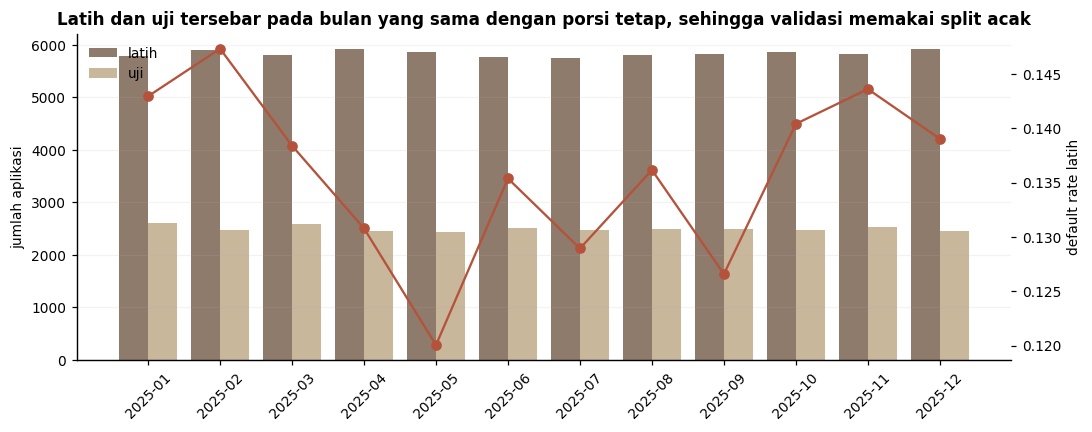

porsi uji per bulan 0,293–0,311 | default rate bulanan 0,1201–0,1473 | tenor unik aplikasi kini: [12]


In [5]:
per = lambda s: s.dt.to_period('M')
monthly = pd.DataFrame({'aplikasi latih': train.groupby(per(train.decision_datetime)).size(),
                        'aplikasi uji': test.groupby(per(test.decision_datetime)).size(),
                        'default rate latih': train.groupby(per(train.decision_datetime)).target.mean()})
monthly.index = monthly.index.astype(str)
monthly['porsi uji'] = monthly['aplikasi uji'] / (monthly['aplikasi latih'] + monthly['aplikasi uji'])
tampil_tabel(monthly.reset_index(names='bulan keputusan'), 'Aplikasi dan default rate per bulan keputusan')
fig, ax = plt.subplots()
x = np.arange(len(monthly))
ax.bar(x - 0.2, monthly['aplikasi latih'], 0.4, label='latih')
ax.bar(x + 0.2, monthly['aplikasi uji'], 0.4, label='uji', color=PALET['lembut'])
ax.set_xticks(x); ax.set_xticklabels(monthly.index, rotation=45); ax.set_ylabel('jumlah aplikasi'); ax.legend(loc='upper left')
ax2 = ax.twinx(); ax2.plot(x, monthly['default rate latih'], 'o-', color=PALET['aksen1']); ax2.set_ylabel('default rate latih'); ax2.grid(False)
ax.set_title('Latih dan uji tersebar pada bulan yang sama dengan porsi tetap, sehingga validasi memakai split acak')
plt.tight_layout(); plt.show()
catat(f"porsi uji per bulan {angka_id(monthly['porsi uji'].min(), 3)}–{angka_id(monthly['porsi uji'].max(), 3)} | "
      f"default rate bulanan {angka_id(monthly['default rate latih'].min())}–{angka_id(monthly['default rate latih'].max())} | "
      f'tenor unik aplikasi kini: {sorted(int(v) for v in apps.term_months.unique())}')

> ### Insights
>
> <<INS_5_1>>

## 5.2 Tidak Ada Baris yang Melewati Batas Keputusan <a name="bab5-2"></a>

Apakah panitia sudah memotong tabel anak pada `decision_datetime`? Bila belum, setiap fungsi fitur wajib memfilter; bila sudah, filter tetap dipasang dan diasersi agar kesalahan *join* langsung terdeteksi. Untuk setiap kolom waktu dihitung porsi baris yang jatuh sesudah batas nasabahnya.

In [6]:
def after_cut(frame, col, key='customer_id'):
    cut = CUT.reindex(frame[key]).to_numpy()
    return float((frame[col].to_numpy() > cut).mean())


month_end = account.month + pd.offsets.MonthBegin(1)
audit = pd.DataFrame([
    ('previous_applications', 'decision_datetime', after_cut(prev_apps, 'decision_datetime')),
    ('repayment_history', 'due_date', after_cut(repay, 'due_date')),
    ('repayment_history', 'last_payment_datetime', after_cut(repay.dropna(subset=['last_payment_datetime']), 'last_payment_datetime')),
    ('account_behavior', 'akhir bulan', float((month_end.to_numpy() > CUT.reindex(account.customer_id).to_numpy()).mean())),
    ('bureau_observations', 'report_datetime', after_cut(bureau, 'report_datetime')),
    ('bureau_observations', 'available_datetime', after_cut(bureau, 'available_datetime')),
    ('ecommerce_transactions', 'transaction_datetime', after_cut(ecom, 'transaction_datetime')),
], columns=['tabel', 'kolom waktu', 'porsi baris sesudah batas'])
tampil_tabel(audit, 'Audit point-in-time: porsi baris yang melewati decision_datetime nasabahnya')
lag = (bureau.available_datetime - bureau.report_datetime).dt.total_seconds() / 86400
sel_bureau = bureau[bureau.application_id.isin(apps.application_id)]
n_lap = sel_bureau.groupby('application_id').size().value_counts().sort_index()
tampil_tabel(pd.DataFrame({'laporan biro per aplikasi kini': n_lap.index, 'jumlah aplikasi': n_lap.to_numpy()}), 'Laporan biro saat keputusan')
catat(f'jeda available - report (hari): min {angka_id(lag.min(), 0)}, median {angka_id(lag.median(), 0)}, maks {angka_id(lag.max(), 0)}')
del month_end, lag; _ = gc.collect()

**Audit point-in-time: porsi baris yang melewati decision_datetime nasabahnya**

,tabel,kolom waktu,porsi baris sesudah batas
0,previous_applications,decision_datetime,"0,0000"
1,repayment_history,due_date,"0,0000"
2,repayment_history,last_payment_datetime,"0,0000"
3,account_behavior,akhir bulan,"0,0000"
4,bureau_observations,report_datetime,"0,0000"
5,bureau_observations,available_datetime,"0,0000"
6,ecommerce_transactions,transaction_datetime,"0,0000"


**Laporan biro saat keputusan**

,laporan biro per aplikasi kini,jumlah aplikasi
0,1,3.254
1,2,29.404
2,3,67.342


jeda available - report (hari): min 0, median 60, maks 120


> ### Insights
>
> <<INS_5_2>>

## 5.3 Bunga Mengikuti Risiko <a name="bab5-3"></a>

Apakah pemberi pinjaman sudah menetapkan harga berdasarkan risiko? Bila ya, bunga dan cicilan anuitas adalah ringkasan penilaian risiko pihak lain yang tersedia saat keputusan. Grafik menunjukkan *default rate* per tingkat bunga dan hubungan cicilan anuitas terhadap pendapatan.

**Bunga, default rate, dan skor biro**

,bunga tahunan,n,default rate,rata-rata skor biro
0,"0,1600",12.560,"0,0549","727,5480"
1,"0,2000",29.800,"0,1065","679,5625"
2,"0,2400",22.358,"0,1777","637,7987"
3,"0,2800",4.938,"0,3036","596,0535"
4,"0,3200",344,"0,5029","555,5894"


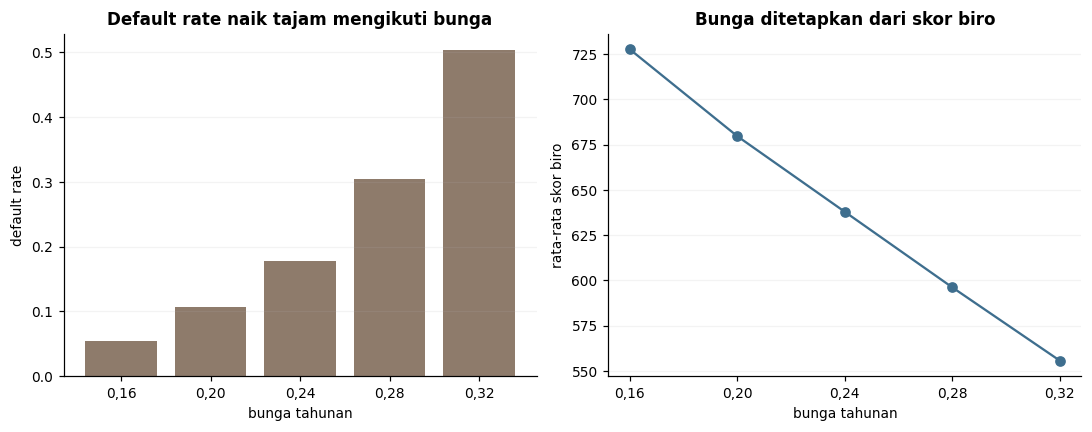

cicilan / anuitas: 1,000000–1,000009 | KS univariat bunga 0,2301


In [7]:
r = train.annual_interest_rate / 12
annuity = train.loan_amount * r / (1 - (1 + r) ** (-train.term_months))
rasio_anuitas = train.proposed_monthly_installment / annuity
score_sel = sel_bureau.groupby('application_id').score.mean()
pricing = train.assign(score=train.application_id.map(score_sel)).groupby('annual_interest_rate').agg(
    n=('target', 'size'), default_rate=('target', 'mean'), skor_biro=('score', 'mean')).reset_index()
tampil_tabel(pricing.rename(columns={'annual_interest_rate': 'bunga tahunan', 'default_rate': 'default rate', 'skor_biro': 'rata-rata skor biro'}),
             'Bunga, default rate, dan skor biro')
fig, ax = plt.subplots(1, 2)
lab = [angka_id(v, 2) for v in pricing.annual_interest_rate]
ax[0].bar(lab, pricing.default_rate); ax[0].set_xlabel('bunga tahunan'); ax[0].set_ylabel('default rate')
ax[0].set_title('Default rate naik tajam mengikuti bunga')
ax[1].plot(lab, pricing.skor_biro, 'o-', color=PALET['aksen2']); ax[1].set_xlabel('bunga tahunan'); ax[1].set_ylabel('rata-rata skor biro')
ax[1].set_title('Bunga ditetapkan dari skor biro')
plt.tight_layout(); plt.show()
catat(f'cicilan / anuitas: {angka_id(rasio_anuitas.min(), 6)}–{angka_id(rasio_anuitas.max(), 6)} | KS univariat bunga {angka_id(ks_stat(y, train.annual_interest_rate))}')
del r, annuity; _ = gc.collect()

> ### Insights
>
> <<INS_5_3>>

## 5.4 Sepertiga Nasabah Tanpa Jejak Kredit <a name="bab5-4"></a>

Seberapa besar segmen *thin-file*, sumber apa saja yang tersedia baginya, dan apakah risikonya berbeda? Jawaban ini menentukan apakah setiap uji harus dilaporkan per segmen. Tabel menunjukkan cakupan tiap sumber dan *default rate* per segmen.

**Segmen dan cakupan sumber data (data latih)**

,segmen,nasabah latih,porsi,default rate,cakupan aplikasi lama,cakupan rekening,cakupan biro historis,cakupan e-commerce
0,berhistori,49.000,"0,7000","0,1438","1,0000","1,0000","1,0000","1,0000"
1,thin-file,21.000,"0,3000","0,1172","0,0000","0,0000","0,0000","1,0000"


**Default rate per bunga dan segmen**

,bunga tahunan,berhistori,thin-file
0,"0,1600","0,0539","0,0573"
1,"0,2000","0,1105","0,0976"
2,"0,2400","0,1860","0,1572"
3,"0,2800","0,3222","0,2429"
4,"0,3200","0,5310","0,3519"


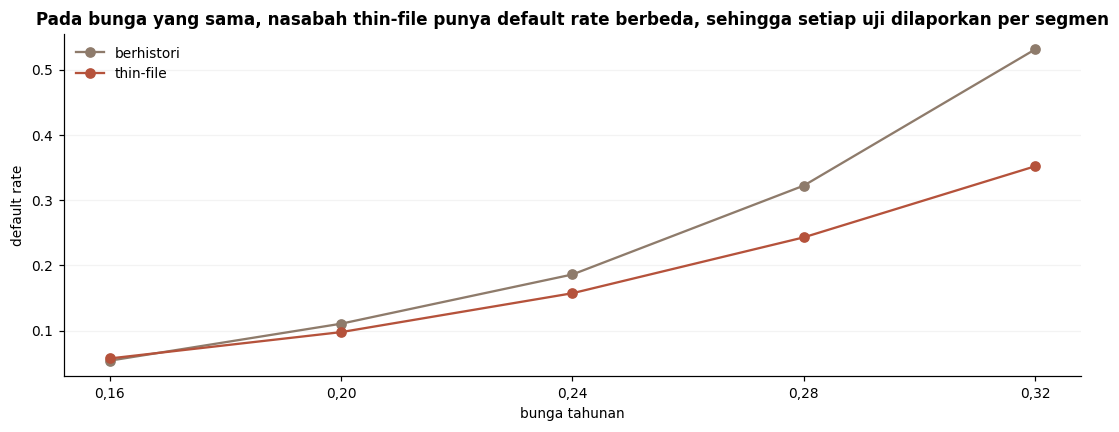

In [8]:
coverage = pd.DataFrame({
    'aplikasi lama': apps.customer_id.isin(prev_apps.customer_id),
    'rekening': apps.customer_id.isin(account.customer_id.unique()),
    'biro historis': apps.customer_id.isin(bureau.loc[~bureau.application_id.isin(apps.application_id), 'customer_id'].unique()),
    'e-commerce': apps.customer_id.isin(ecom.customer_id.unique()),
}).set_index(apps.customer_id)
HIST_EDA = coverage['aplikasi lama'].reindex(train.customer_id).to_numpy()
seg_tab = pd.DataFrame([(nama, m.sum(), m.mean(), y[m].mean(), *coverage.reindex(train.customer_id[m]).mean().to_numpy())
                        for nama, m in (('berhistori', HIST_EDA), ('thin-file', ~HIST_EDA))],
                       columns=['segmen', 'nasabah latih', 'porsi', 'default rate', *[f'cakupan {c}' for c in coverage.columns]])
tampil_tabel(seg_tab, 'Segmen dan cakupan sumber data (data latih)')
rate_seg = train.assign(segmen=np.where(HIST_EDA, 'berhistori', 'thin-file')).groupby(['annual_interest_rate', 'segmen']).target.mean().unstack()
tampil_tabel(rate_seg.reset_index().rename(columns={'annual_interest_rate': 'bunga tahunan'}), 'Default rate per bunga dan segmen')
fig, ax = plt.subplots()
for seg, col in (('berhistori', PALET['utama']), ('thin-file', PALET['aksen1'])):
    ax.plot([angka_id(v, 2) for v in rate_seg.index], rate_seg[seg], 'o-', color=col, label=seg)
ax.set_xlabel('bunga tahunan'); ax.set_ylabel('default rate'); ax.legend()
ax.set_title('Pada bunga yang sama, nasabah thin-file punya default rate berbeda, sehingga setiap uji dilaporkan per segmen')
plt.tight_layout(); plt.show()

> ### Insights
>
> <<INS_5_4>>

## 5.5 Tiga Biro Mengukur Satu Laten <a name="bab5-5"></a>

Apakah ketiga provider biro membawa informasi berbeda atau mengukur hal yang sama dengan derau? Bila sama, rata-rata antar-provider menurunkan derau ukur tanpa membuang informasi.

**Korelasi skor antar-provider (aplikasi kini)**

,provider,Bureau_A,Bureau_B,Bureau_C
0,Bureau_A,"1,000","0,814","0,814"
1,Bureau_B,"0,814","1,000","0,814"
2,Bureau_C,"0,814","0,814","1,000"


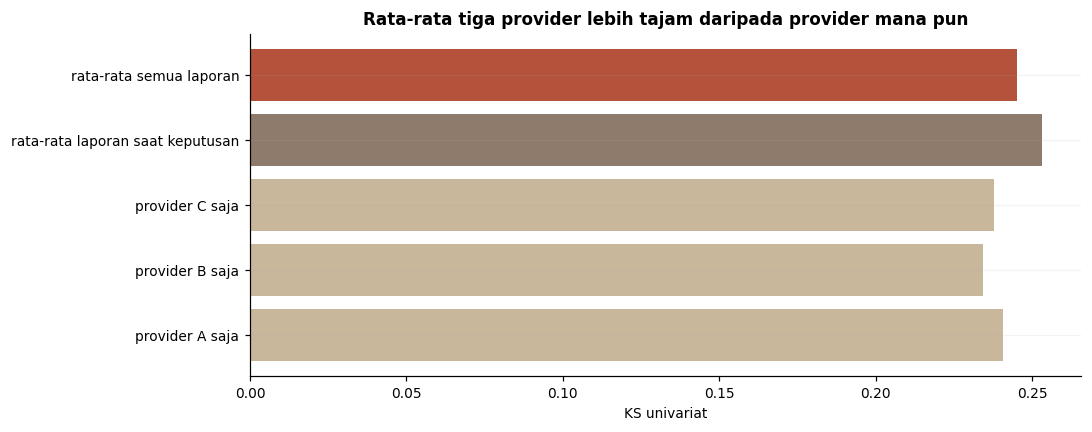

rata-rata korelasi antar-provider 0,814 | reliabilitas rata-rata 3 laporan (Spearman–Brown) 0,929 | KS: provider A saja 0,2406, provider B saja 0,2343, provider C saja 0,2378, rata-rata laporan saat keputusan 0,2530, rata-rata semua laporan 0,2451


In [9]:
pv = sel_bureau.pivot_table(index='application_id', columns='bureau_provider', values='score')
korelasi = pv.corr()
rho_biro = korelasi.values[np.triu_indices(3, 1)].mean()
tampil_tabel(korelasi.reset_index().rename(columns={'bureau_provider': 'provider'}), 'Korelasi skor antar-provider (aplikasi kini)', desimal=3)
ytr_app = train.set_index('application_id').target
all_mean = bureau[bureau.available_datetime <= CUT.reindex(bureau.customer_id).to_numpy()].groupby('customer_id').score.mean()
ks_biro = {f'provider {p[-1]} saja': ks_stat(ytr_app.reindex(pv.index).dropna(), pv.loc[ytr_app.reindex(pv.index).notna(), p]) for p in pv.columns}
mean_sel = pv.mean(axis=1)
ks_biro['rata-rata laporan saat keputusan'] = ks_stat(ytr_app.reindex(mean_sel.index).dropna(), mean_sel[ytr_app.reindex(mean_sel.index).notna()])
ks_biro['rata-rata semua laporan'] = ks_stat(ytr_cust.reindex(all_mean.index).dropna(), all_mean[ytr_cust.reindex(all_mean.index).notna()])
fig, ax = plt.subplots()
ax.barh(list(ks_biro), list(ks_biro.values()), color=[PALET['lembut']] * 3 + [PALET['utama'], PALET['aksen1']])
ax.set_xlabel('KS univariat'); ax.set_title('Rata-rata tiga provider lebih tajam daripada provider mana pun')
plt.tight_layout(); plt.show()
catat(f'rata-rata korelasi antar-provider {angka_id(rho_biro, 3)} | reliabilitas rata-rata 3 laporan (Spearman–Brown) '
      f'{angka_id(3 * rho_biro / (1 + 2 * rho_biro), 3)} | KS: ' + ', '.join(f'{k} {angka_id(v)}' for k, v in ks_biro.items()))
del pv, all_mean, mean_sel; _ = gc.collect()

> ### Insights
>
> <<INS_5_5>>

## 5.6 Cicilan Dibayar sebagai Antrian FIFO <a name="bab5-6"></a>

Bagaimana generator data mencatat pembayaran? Bila pembayaran hanya terjadi pada jadwal bulanan dan selalu melunasi cicilan tertua lebih dulu, tunggakan berperilaku sebagai antrian, dan dinamika masuk–keluar antrian, bukan sekadar rata-rata keterlambatan, yang mendekati definisi target (DPD 90 pada pinjaman baru).

**Mekanisme pembayaran yang dipakai generator data**

,pemeriksaan,porsi baris yang memenuhi
0,cicilan lunas dibayar tepat pada jadwal bulana...,"1,0000"
1,jarak bayar cicilan lunas berupa hari bulat,"1,0000"
2,max_days_past_due − jarak bayar = -1 hari (cic...,"1,0000"
3,cicilan yang dibayar sebagian adalah cicilan t...,"1,0000"
4,tidak ada cicilan lunas sesudah cicilan yang b...,"1,0000"
5,cicilan belum lunas: days_past_due = hari seja...,"1,0000"


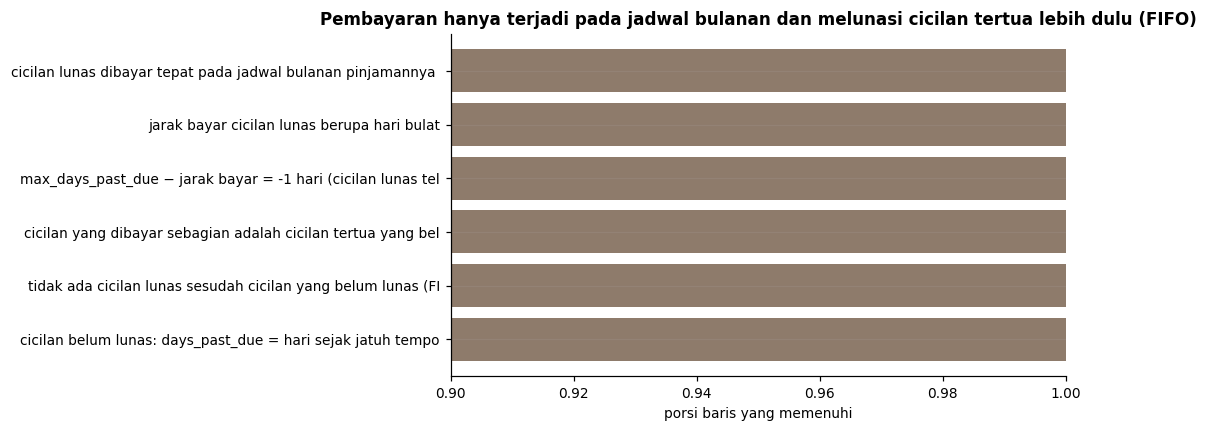

porsi cicilan dibayar sebagian 0,0199 | KS univariat tingkat keterlambatan 0,4391 (cakupan 0,662) | 8 detik


In [10]:
DAY = 86400.0


def safe_div(a, b):
    a = np.asarray(a, dtype=float); b = np.asarray(b, dtype=float)
    out = np.full(np.broadcast(a, b).shape, np.nan)
    np.divide(a, b, out=out, where=(b != 0) & ~np.isnan(b))
    return out


def slope(values):
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n < 3:
        return np.nan
    x = np.arange(n) - (n - 1) / 2
    return float((x * (values - values.mean())).sum() / (x * x).sum())


def attach_cut(frame, key='customer_id'):
    frame['cut'] = CUT.reindex(frame[key]).to_numpy()
    return frame


t0 = time.time()
rp = pd.read_csv(CFG.data_dir / 'repayment_history.csv', parse_dates=['due_date', 'last_payment_datetime'],
                 usecols=lambda c: c != 'installment_id')
rp = attach_cut(rp)
assert (rp.due_date <= rp.cut).all(), 'cicilan jatuh tempo setelah cutoff'
paid_any = rp.last_payment_datetime.notna()
assert (rp.last_payment_datetime[paid_any] <= rp.cut[paid_any]).all(), 'pembayaran setelah cutoff'
rp = rp.sort_values(['loan_id', 'due_date']).reset_index(drop=True)
rp['k'] = rp.groupby('loan_id').cumcount()
n_rows = len(rp)
due_key = (rp[['loan_id', 'due_date', 'k']].rename(columns={'due_date': 'last_payment_datetime', 'k': 'k_pay'})
           .drop_duplicates(['loan_id', 'last_payment_datetime']))
rp = rp.merge(due_key, on=['loan_id', 'last_payment_datetime'], how='left')
assert len(rp) == n_rows, 'merge jatuh tempo menggandakan baris'
paid_any = rp.last_payment_datetime.notna().to_numpy()
full = (rp.amount_paid >= rp.amount_due).to_numpy()
unpaid = ~full
partial = ((rp.amount_paid > 0) & (rp.amount_paid < rp.amount_due)).to_numpy()
gap = ((rp.last_payment_datetime - rp.due_date).dt.total_seconds() / DAY).to_numpy()
fp = full & paid_any
late_full = fp & (gap > 0)
first_unpaid = rp[unpaid].groupby('loan_id').k.min()
fu = rp.loan_id.map(first_unpaid).to_numpy()
fifo_violation = full & ~np.isnan(fu) & (rp.k.to_numpy() > fu)
days_since_due = np.floor((rp.cut - rp.due_date).dt.total_seconds().to_numpy() / DAY)
loan_dec = prev_apps.dropna(subset=['loan_id']).drop_duplicates('loan_id').set_index('loan_id').decision_datetime
base = pd.Series(loan_dec.reindex(rp.loan_id).to_numpy())
lp_vals = rp.last_payment_datetime.to_numpy()
base_np = base.to_numpy()
m_est = np.round((lp_vals - base_np) / np.timedelta64(1, 'D') / 30.4375)
on_sched = np.zeros(len(rp), bool)
for mm in np.unique(m_est[fp & ~np.isnan(m_est)]):
    sel = fp & (m_est == mm)
    on_sched[sel] = (pd.Series(base_np[sel]) + pd.DateOffset(months=int(mm))).to_numpy() == lp_vals[sel]
dpd_minus_gap = pd.Series(rp.max_days_past_due.to_numpy()[late_full] - gap[late_full]).value_counts(normalize=True)
MECH = pd.DataFrame([
    ('cicilan lunas dibayar tepat pada jadwal bulanan pinjamannya (keputusan + m bulan)', on_sched[fp].mean()),
    ('jarak bayar cicilan lunas berupa hari bulat', np.isclose(np.mod(gap[fp], 1), 0).mean()),
    (f'max_days_past_due − jarak bayar = {dpd_minus_gap.index[0]:+.0f} hari (cicilan lunas telat)', float(dpd_minus_gap.iloc[0])),
    ('cicilan yang dibayar sebagian adalah cicilan tertua yang belum lunas', (rp.k.to_numpy()[partial] == fu[partial]).mean()),
    ('tidak ada cicilan lunas sesudah cicilan yang belum lunas (FIFO)', 1 - fifo_violation.mean()),
    ('cicilan belum lunas: days_past_due = hari sejak jatuh tempo', (rp.days_past_due.to_numpy()[unpaid] == days_since_due[unpaid]).mean()),
], columns=['pemeriksaan', 'porsi baris yang memenuhi'])
tampil_tabel(MECH, 'Mekanisme pembayaran yang dipakai generator data')
fig, ax = plt.subplots()
ax.barh([s_[:60] for s_ in MECH.pemeriksaan], MECH['porsi baris yang memenuhi'], color=PALET['utama'])
ax.set_xlim(0.9, 1.0); ax.set_xlabel('porsi baris yang memenuhi'); ax.invert_yaxis()
ax.set_title('Pembayaran hanya terjadi pada jadwal bulanan dan melunasi cicilan tertua lebih dulu (FIFO)')
plt.tight_layout(); plt.show()
cust_late = rp.assign(late=rp.max_days_past_due > 0).groupby('customer_id').late.mean().reindex(train.customer_id)
m_late = cust_late.notna().to_numpy()
catat(f'porsi cicilan dibayar sebagian {angka_id(partial.mean())} | KS univariat tingkat keterlambatan {angka_id(ks_stat(y[m_late], cust_late.to_numpy()[m_late]))} '
      f'(cakupan {angka_id(m_late.mean(), 3)}) | {angka_id(time.time() - t0, 0)} detik')
del base, base_np, lp_vals, m_est, on_sched, gap, fu, fifo_violation, days_since_due, cust_late; _ = gc.collect()

> ### Insights
>
> <<INS_5_6>>

## 5.7 Belanja Melonjak Menjelang Pengajuan <a name="bab5-7"></a>

Apakah perilaku e-commerce dan arus kas rekening berubah menjelang keputusan, dan berbeda antara nasabah gagal bayar dan lancar? Bila perubahan terkonsentrasi pada hari-hari terakhir, fitur harus dihitung pada jendela waktu relatif terhadap keputusan dan dibandingkan dengan *baseline* pribadi.

**Intensitas pesanan e-commerce menurut jarak ke keputusan**

,jendela (hari),pesanan/hari lancar,pesanan/hari default,rasio default/lancar
0,"[0, 3)","0,1049","0,2751","2,6232"
1,"[3, 7)","0,0924","0,1945","2,1039"
2,"[7, 14)","0,0770","0,1413","1,8365"
3,"[14, 30)","0,0690","0,1078","1,5618"
4,"[30, 60)","0,0652","0,0880","1,3491"
5,"[60, 90)","0,0642","0,0762","1,1869"
6,"[90, 180)","0,0664","0,0666","1,0024"
7,"[180, 365)","0,0532","0,0455","0,8556"
8,"[365, 730)","0,0216","0,0161","0,7478"


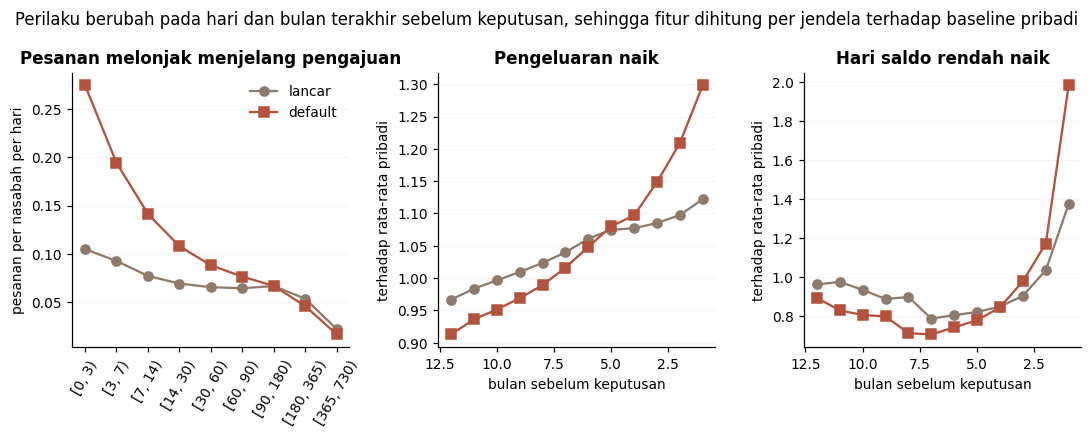

rasio intensitas pesanan default/lancar 0–3 hari 2,62 vs 365–730 hari 0,75 | pesanan per hari 0–3 vs 365–730 hari (semua nasabah): 6,15×


In [11]:
orders = ecom.drop_duplicates('order_id')[['customer_id', 'transaction_datetime', 'order_total', 'payment_method']]
orders = orders[orders.customer_id.isin(train.customer_id)].copy()
orders['d'] = (CUT.reindex(orders.customer_id).to_numpy() - orders.transaction_datetime).dt.total_seconds() / 86400
orders['y'] = ytr_cust.reindex(orders.customer_id).to_numpy()
EDGES = [0, 3, 7, 14, 30, 60, 90, 180, 365, 730]
orders['window'] = pd.cut(orders.d, EDGES, right=False)
n_class = train.target.value_counts()
counts = orders.groupby(['window', 'y'], observed=False).size().unstack()
intensity = counts.div(n_class, axis=1).div(np.diff(EDGES), axis=0)
profil_ec = pd.DataFrame({'jendela (hari)': [str(w) for w in intensity.index], 'pesanan/hari lancar': intensity[0].to_numpy(),
                          'pesanan/hari default': intensity[1].to_numpy(), 'rasio default/lancar': (intensity[1] / intensity[0]).to_numpy()})
tampil_tabel(profil_ec, 'Intensitas pesanan e-commerce menurut jarak ke keputusan')
ac = account[account.customer_id.isin(train.customer_id)].copy()
cut_ac = CUT.reindex(ac.customer_id)
ac['k'] = (cut_ac.dt.year.to_numpy() - ac.month.dt.year.to_numpy()) * 12 + (cut_ac.dt.month.to_numpy() - ac.month.dt.month.to_numpy())
ac['y'] = ytr_cust.reindex(ac.customer_id).to_numpy()
fig, axes = plt.subplots(1, 3)
axes[0].plot(profil_ec['jendela (hari)'], profil_ec['pesanan/hari lancar'], 'o-', label='lancar')
axes[0].plot(profil_ec['jendela (hari)'], profil_ec['pesanan/hari default'], 's-', color=PALET['aksen1'], label='default')
axes[0].set_ylabel('pesanan per nasabah per hari'); axes[0].tick_params(axis='x', rotation=60); axes[0].legend()
axes[0].set_title('Pesanan melonjak menjelang pengajuan')
for ax, col in zip(axes[1:], ['outflows', 'low_balance_days']):
    rel = ac[col] / ac.groupby('customer_id')[col].transform('mean').replace(0, np.nan)
    curve = ac.assign(rel=rel)[ac.k <= 12].groupby(['k', 'y']).rel.mean().unstack()
    ax.plot(curve.index, curve[0], 'o-', label='lancar'); ax.plot(curve.index, curve[1], 's-', color=PALET['aksen1'], label='default')
    ax.invert_xaxis(); ax.set_xlabel('bulan sebelum keputusan'); ax.set_ylabel('terhadap rata-rata pribadi')
    ax.set_title('Pengeluaran naik' if col == 'outflows' else 'Hari saldo rendah naik')
fig.suptitle('Perilaku berubah pada hari dan bulan terakhir sebelum keputusan, sehingga fitur dihitung per jendela terhadap baseline pribadi')
plt.tight_layout(); plt.show()
catat(f"rasio intensitas pesanan default/lancar 0–3 hari {angka_id(profil_ec['rasio default/lancar'].iloc[0], 2)} vs "
      f"365–730 hari {angka_id(profil_ec['rasio default/lancar'].iloc[-1], 2)} | pesanan per hari 0–3 vs 365–730 hari (semua nasabah): "
      f"{angka_id((counts.sum(axis=1) / np.diff(EDGES)).iloc[0] / (counts.sum(axis=1) / np.diff(EDGES)).iloc[-1], 2)}×")
del orders, ac, cut_ac; _ = gc.collect()

> ### Insights
>
> <<INS_5_7>>

## 5.8 Nasabah Berisiko Membeli Barang Lebih Mahal <a name="bab5-8"></a>

Apakah harga item yang dibeli nasabah membawa informasi setelah efek kategori dan bulan dihilangkan? Log harga diuraikan menjadi efek kategori×bulan, efek nasabah, dan derau; bila efek nasabah stabil dan berkaitan dengan *default*, efek itu menjadi fitur `pr_*`.

**Dekomposisi log harga item = efek kategori×bulan + efek nasabah + derau**

,besaran,nilai
0,sigma derau,"0,6567"
1,tau efek nasabah,"0,2204"
2,ICC,"0,1013"
3,reliabilitas median,"0,8221"


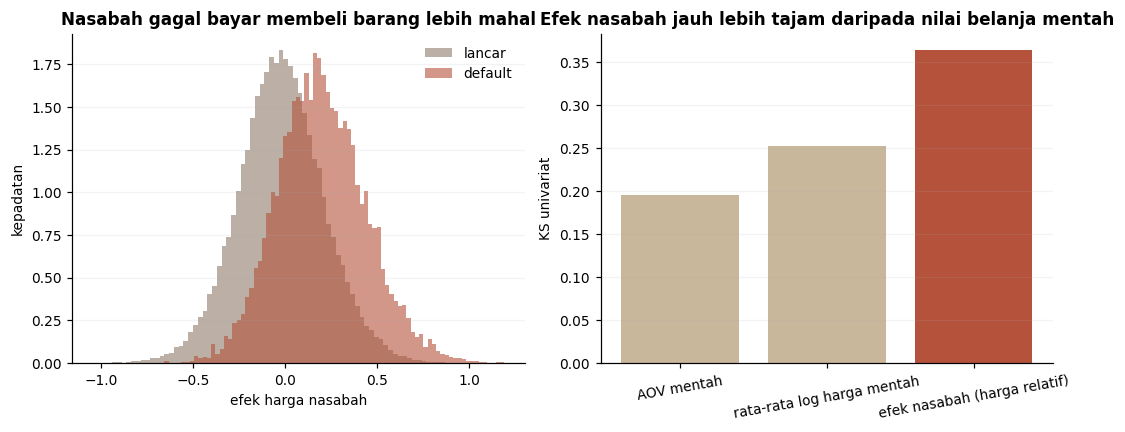

KS univariat: AOV mentah 0,1950, rata-rata log harga mentah 0,2521, efek nasabah (harga relatif) 0,3646
Bab 5 selesai: 0,4 menit


In [12]:
items = ecom[['customer_id', 'product_category', 'transaction_datetime', 'quantity', 'item_total']].copy()
items['lp'] = np.log(items.item_total / items.quantity)
items['m'] = items.transaction_datetime.dt.year * 12 + items.transaction_datetime.dt.month
cm = items.groupby(['product_category', 'm'], observed=True).lp.agg(['sum', 'size']).reset_index()
trail = pd.concat([cm.assign(m=cm.m + lag) for lag in (1, 2, 3)]).groupby(['product_category', 'm'], observed=True)[['sum', 'size']].sum()
items = items.join((trail['sum'] / trail['size']).rename('ref'), on=['product_category', 'm'])
items['ref'] = items.ref.fillna(items.groupby('product_category', observed=True).ref.transform('first'))
items['r'] = items.lp - items.ref
items['cmean'] = items.groupby('customer_id').r.transform('mean')
cust = items.groupby('customer_id').agg(u=('r', 'mean'), n=('r', 'size'))
sigma2 = ((items.r - items.cmean) ** 2).sum() / (len(items) - len(cust))
tau2 = cust.u.var() - np.mean(sigma2 / cust.n)
orders_v = ecom.drop_duplicates('order_id').groupby('customer_id').order_total.mean()
compare_ks = {'AOV mentah': ks_stat(ytr_cust, orders_v.reindex(ytr_cust.index)),
              'rata-rata log harga mentah': ks_stat(ytr_cust, items.groupby('customer_id').lp.mean().reindex(ytr_cust.index)),
              'efek nasabah (harga relatif)': ks_stat(ytr_cust, cust.u.reindex(ytr_cust.index))}
tampil_tabel(pd.DataFrame({'besaran': ['sigma derau', 'tau efek nasabah', 'ICC', 'reliabilitas median'],
                           'nilai': [np.sqrt(sigma2), np.sqrt(tau2), tau2 / (tau2 + sigma2), np.median(tau2 / (tau2 + sigma2 / cust.n))]}),
             'Dekomposisi log harga item = efek kategori×bulan + efek nasabah + derau')
fig, ax = plt.subplots(1, 2)
u_tr = cust.u.reindex(ytr_cust.index)
for lab, col in ((0, PALET['utama']), (1, PALET['aksen1'])):
    ax[0].hist(u_tr[ytr_cust == lab].dropna(), bins=80, density=True, alpha=0.6, color=col, label='lancar' if lab == 0 else 'default')
ax[0].set_xlabel('efek harga nasabah'); ax[0].set_ylabel('kepadatan'); ax[0].legend()
ax[0].set_title('Nasabah gagal bayar membeli barang lebih mahal')
ax[1].bar(list(compare_ks), list(compare_ks.values()), color=[PALET['lembut'], PALET['lembut'], PALET['aksen1']])
ax[1].set_ylabel('KS univariat'); ax[1].tick_params(axis='x', rotation=10)
ax[1].set_title('Efek nasabah jauh lebih tajam daripada nilai belanja mentah')
plt.tight_layout(); plt.show()
catat('KS univariat: ' + ', '.join(f'{k} {angka_id(v)}' for k, v in compare_ks.items()))
del items, cm, trail, cust, orders_v, u_tr; _ = gc.collect()
selesai_bab('Bab 5')

> ### Insights
>
> <<INS_5_8>>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 6. Desain Validasi <a name="bab6"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## 6.1 Lipatan Bersama untuk Semua Model <a name="bab6-1"></a>

Agar dua model dapat dibandingkan secara berpasangan, semua model memakai `StratifiedKFold(5, shuffle=True, random_state=42)` yang sama. Sel ini juga memeriksa fungsi KS notebook terhadap `ks_2samp` SciPy. Perkiraan waktu bab: <<WAKTU_EST_6>>.

In [13]:
FOLDS = list(StratifiedKFold(CFG.n_folds, shuffle=True, random_state=CFG.seed).split(np.zeros(len(y)), y))


def competition_score(solution: pd.DataFrame, submission: pd.DataFrame, row_id_column_name: str) -> float:
    target_col = 'default_probability'
    sol = solution.sort_values(by=row_id_column_name).reset_index(drop=True)
    sub = submission.sort_values(by=row_id_column_name).reset_index(drop=True)
    y_true = sol[target_col].to_numpy()
    y_pred = sub[target_col].to_numpy()
    preds_bad = y_pred[y_true == 1]
    preds_good = y_pred[y_true == 0]
    if len(preds_bad) == 0 or len(preds_good) == 0:
        return 0.0
    return float(ks_2samp(preds_bad, preds_good).statistic)


probe = np.random.default_rng(0).random(len(y)) + 0.3 * y
sol = pd.DataFrame({'application_id': train.application_id, 'default_probability': y})
sub = pd.DataFrame({'application_id': train.application_id, 'default_probability': probe})
KS_SELISIH = abs(competition_score(sol, sub, 'application_id') - ks_stat(y, probe))
assert KS_SELISIH < 1e-12
tampil_tabel(pd.DataFrame([(k, len(a), len(b), y[b].mean()) for k, (a, b) in enumerate(FOLDS)],
                          columns=['fold', 'baris latih', 'baris validasi', 'default rate validasi']), 'Lipatan bersama')
catat(f"selisih KS notebook vs fungsi skor panitia: {f'{KS_SELISIH:.1e}'.replace('.', ',')}")
del probe, sol, sub

**Lipatan bersama**

,fold,baris latih,baris validasi,default rate validasi
0,0,56.000,14.000,"0,1358"
1,1,56.000,14.000,"0,1358"
2,2,56.000,14.000,"0,1358"
3,3,56.000,14.000,"0,1359"
4,4,56.000,14.000,"0,1359"


selisih KS notebook vs fungsi skor panitia: 0,0e+00


> ### Insights
>
> <<INS_6_1>>

## 6.2 Validasi Adversarial <a name="bab6-2"></a>

Dapatkah sebuah model membedakan baris latih dari baris uji? AUC ±0,50 berarti keduanya berasal dari distribusi yang sama, sehingga AUC OOF adalah penduga yang jujur untuk data uji.

In [14]:
ADV_COLS = ['loan_amount', 'annual_interest_rate', 'proposed_monthly_installment', 'term_months', 'age', 'employment_tenure_months',
            'declared_monthly_income', 'dependents', 'loan_purpose', 'region', 'employment_type', 'housing_status']
adv = apps.merge(profiles, on='customer_id', how='left')
A_adv = adv[ADV_COLS].copy()
for c in ('loan_purpose', 'region', 'employment_type', 'housing_status'):
    A_adv[c] = A_adv[c].astype('category')
A_adv['hari_keputusan'] = (adv.decision_datetime - pd.Timestamp('2025-01-01')).dt.total_seconds() / 86400
is_test = (~adv.is_train).astype(int).to_numpy()
adv_oof = np.zeros(len(A_adv))
for a, b in StratifiedKFold(5, shuffle=True, random_state=CFG.seed).split(A_adv, is_test):
    m = lgb.train(dict(objective='binary', learning_rate=0.05, num_leaves=31, verbosity=-1, n_jobs=CFG.n_jobs, seed=CFG.seed),
                  lgb.Dataset(A_adv.iloc[a], is_test[a]), 200)
    adv_oof[b] = m.predict(A_adv.iloc[b])
ADV_AUC = roc_auc_score(is_test, adv_oof)
catat(f'validasi adversarial latih vs uji ({len(A_adv.columns)} kolom aplikasi, profil, dan hari keputusan): AUC {angka_id(ADV_AUC)}')
del adv, A_adv, adv_oof; _ = gc.collect()

validasi adversarial latih vs uji (13 kolom aplikasi, profil, dan hari keputusan): AUC 0,5054


> ### Insights
>
> <<INS_6_2>>

## 6.3 Alat Uji dan Kapan Dipakai <a name="bab6-3"></a>

Keputusan diambil dengan alat yang dayanya terukur, dan kriteria setiap uji ditulis sebelum hasilnya keluar (pra-registrasi). Tabel berikut merangkum alat yang dipakai notebook ini dan perannya.

| Alat | Pertanyaan | Dipakai di | Ambang |
| --- | --- | --- | --- |
| DeLong berpasangan atas AUC | Apakah model/paket A lebih baik dari B pada *fold* yang sama? | §9.3, §11.4 | z > 2 |
| KS dan ΔKS *bootstrap* | Berapa perubahan metrik lomba? | dilaporkan saja | — |
| Uji skor Rao | Apakah satu fitur membawa informasi di atas *offset* paket? | §11.2 | Bonferroni |
| Uji skor gabungan (χ²) | Apakah sekelompok fitur membawa informasi? | §10 (run terdahulu) | z setara > 2 |
| Validasi adversarial | Apakah latih dan uji sebanding? | §6.2 | AUC ≈ 0,50 |
| *Early stopping* | Kapan berhenti melatih? | §8 | AUC validasi, kesabaran 250 |

KS hanya dilaporkan karena SE-nya ±0,004 pada 70.000 baris dan seleksi berbasis KS terbukti *overfit* pada derau (CLAUDE.md Submission 7). Sel kode mendefinisikan DeLong dan uji skor Rao, lalu memeriksanya pada contoh yang diketahui jawabannya.

In [15]:
def delong(y_true, preds):
    order = np.argsort(-y_true, kind='mergesort')
    yy = y_true[order]; P = np.vstack([np.asarray(p)[order] for p in preds])
    m = int(yy.sum()); n = len(yy) - m
    tx = np.vstack([rankdata(r[:m]) for r in P]); ty = np.vstack([rankdata(r[m:]) for r in P]); tz = np.vstack([rankdata(r) for r in P])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx) / n
    v10 = 1 - (tz[:, m:] - ty) / m
    S = np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
    return aucs, S


def delong_test(y_true, p, q, mask=None):
    if mask is not None:
        y_true, p, q = y_true[mask], p[mask], q[mask]
    aucs, S = delong(y_true, [p, q])
    d = aucs[0] - aucs[1]; se = np.sqrt(S[0, 0] + S[1, 1] - 2 * S[0, 1])
    return d, se, d / se, 2 * norm.sf(abs(d / se))


def score_test(values, p, mask):
    v = np.asarray(values, float)[mask]; s = norm.ppf((rankdata(v) - 0.5) / len(v))
    yy, pp = y[mask], p[mask]; ww = pp * (1 - pp)
    U = np.sum((yy - pp) * s); I = np.sum(ww * s * s) - np.sum(ww * s) ** 2 / np.sum(ww)
    return U / np.sqrt(I)


def logit_p(p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))


rng_uji = np.random.default_rng(1)
p_dummy = np.clip(0.05 + 0.2 * rng_uji.random(len(y)), 1e-3, 1 - 1e-3)
acak = rng_uji.normal(size=len(y))
bersinyal = acak + 0.5 * y
semua = np.ones(len(y), bool)
d_acak, se_acak, z_acak, _ = delong_test(y, p_dummy + 1e-3 * acak, p_dummy)
d_sin, se_sin, z_sin, _ = delong_test(y, p_dummy + 1e-3 * bersinyal, p_dummy)
tampil_tabel(pd.DataFrame([('DeLong: skor + derau acak vs skor', d_acak, z_acak), ('DeLong: skor + sinyal vs skor', d_sin, z_sin),
                           ('Rao: kolom acak di atas skor', np.nan, score_test(acak, p_dummy, semua)),
                           ('Rao: kolom bersinyal di atas skor', np.nan, score_test(bersinyal, p_dummy, semua))],
                          columns=['pemeriksaan', 'ΔAUC', 'z']), 'Pemeriksaan alat uji pada contoh yang jawabannya diketahui')
del p_dummy, acak, bersinyal
selesai_bab('Bab 6')

**Pemeriksaan alat uji pada contoh yang jawabannya diketahui**

,pemeriksaan,ΔAUC,z
0,DeLong: skor + derau acak vs skor,"0,0000","0,3476"
1,DeLong: skor + sinyal vs skor,"0,0025","45,1580"
2,Rao: kolom acak di atas skor,—,"0,1948"
3,Rao: kolom bersinyal di atas skor,—,"43,6006"


Bab 6 selesai: 0,1 menit


> ### Insights
>
> <<INS_6_3>>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 7. Rekayasa Fitur <a name="bab7"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Setiap keluarga fitur mewakili satu mekanisme dan dihitung oleh satu fungsi yang memfilter serta mengasersi batas `decision_datetime`. Matriks akhir X7 terdiri dari 275 kolom S4, 5 interaksi antar-laten (khusus regresi logistik), dan 47 kolom dinamika tunggakan. Perkiraan waktu bab: <<WAKTU_EST_7>>.

## 7.1 Aplikasi dan Profil <a name="bab7-1"></a>

| Kelompok | Contoh kolom | Mekanisme |
| --- | --- | --- |
| Pinjaman kini | `loan_amount`, `annual_interest_rate`, `proposed_monthly_installment` | harga risiko dari pemberi pinjaman |
| Kapasitas bayar | `dti`, `lti`, `residual_income`, `income_per_head` | beban cicilan terhadap pendapatan |
| Profil | umur, masa kerja, tanggungan, region, pekerjaan, rumah | stabilitas pendapatan |

In [16]:
def feat_application(apps, profiles):
    a = apps.merge(profiles, on='customer_id', how='left')
    f = pd.DataFrame({'customer_id': a.customer_id})
    for c in ['loan_amount', 'annual_interest_rate', 'proposed_monthly_installment', 'age',
              'employment_tenure_months', 'declared_monthly_income', 'dependents']:
        f[c] = a[c].astype(float)
    for c in ['loan_purpose', 'region', 'employment_type', 'housing_status']:
        f[c] = a[c].astype('category')
    f['decision_lag_h'] = (a.decision_datetime - a.application_datetime).dt.total_seconds() / 3600
    f['app_hour'] = a.application_datetime.dt.hour
    f['app_dow'] = a.application_datetime.dt.dayofweek
    f['dti'] = safe_div(a.proposed_monthly_installment, a.declared_monthly_income)
    f['lti'] = safe_div(a.loan_amount, a.declared_monthly_income)
    f['income_per_head'] = safe_div(a.declared_monthly_income, a.dependents + 1)
    f['residual_income'] = a.declared_monthly_income - a.proposed_monthly_installment
    f['tenure_over_age'] = safe_div(a.employment_tenure_months / 12, a.age - 17)
    f['interest_cost'] = a.proposed_monthly_installment * a.term_months - a.loan_amount
    return f.set_index('customer_id')


def ringkas_blok(nama, blok, t0):
    """Satu baris log per keluarga fitur: jumlah kolom, porsi sel hilang pada nasabah latih + uji, waktu."""
    b = blok.reindex(APPS.index)
    catat(f'{nama}: {b.shape[1]} kolom | porsi sel hilang {angka_id(float(b.isna().mean().mean()), 3)} | '
          f'nasabah tanpa satu pun nilai {angka_id(float(b.isna().all(axis=1).mean()), 3)} | {angka_id(time.time() - t0, 0)} detik')


BLOK = {}
t0 = time.time()
BLOK['aplikasi'] = feat_application(apps, profiles)
ringkas_blok('aplikasi dan profil', BLOK['aplikasi'], t0)

aplikasi dan profil: 20 kolom | porsi sel hilang 0,000 | nasabah tanpa satu pun nilai 0,000 | 0 detik


> ### Insights
>
> <<INS_7_1>>

## 7.2 Aplikasi Sebelumnya <a name="bab7-2"></a>

| Kelompok | Contoh kolom | Mekanisme |
| --- | --- | --- |
| Frekuensi | `prev_n`, `prev_n_90d`, `prev_rej_365d` | intensitas mencari kredit |
| Penolakan | `prev_reject_rate`, `prev_last_decision_rej` | penilaian pemberi pinjaman sebelumnya |
| Kewajiban berjalan | `prev_active_loans`, `prev_remaining_due` | sisa jadwal kontraktual saat keputusan |

In [17]:
def feat_previous(pa):
    pa = attach_cut(pa.copy())
    assert (pa.decision_datetime <= pa.cut).all(), 'aplikasi lama melewati cutoff'
    pa = pa[pa.decision_datetime <= pa.cut].copy()
    pa['days_before'] = (pa.cut - pa.application_datetime).dt.total_seconds() / DAY
    pa['is_app'] = (pa.decision == 'approved').astype(float)
    pa['is_rej'] = (pa.decision == 'rejected').astype(float)
    pa['is_can'] = (pa.decision == 'cancelled').astype(float)
    pa['dec_lag_h'] = (pa.decision_datetime - pa.application_datetime).dt.total_seconds() / 3600
    pa['months_elapsed'] = np.floor((pa.cut - pa.decision_datetime).dt.days / 30.4375)
    pa['remaining_inst'] = np.where(pa.is_app == 1, np.clip(pa.term_months - pa.months_elapsed, 0, None), np.nan)
    pa['active'] = (pa.remaining_inst > 0).astype(float)
    pa['active_inst'] = pa.scheduled_monthly_installment.fillna(0) * pa.active
    pa['remaining_due'] = pa.scheduled_monthly_installment.fillna(0) * pa.remaining_inst.fillna(0)
    pa = pa.sort_values(['customer_id', 'application_datetime'])
    g = pa.groupby('customer_id')
    f = g.agg(prev_n=('application_id', 'size'), prev_n_approved=('is_app', 'sum'), prev_n_rejected=('is_rej', 'sum'),
              prev_n_cancelled=('is_can', 'sum'), prev_reject_rate=('is_rej', 'mean'), prev_cancel_rate=('is_can', 'mean'),
              prev_days_since_last=('days_before', 'min'), prev_days_since_first=('days_before', 'max'),
              prev_req_mean=('requested_amount', 'mean'), prev_req_max=('requested_amount', 'max'),
              prev_appr_sum=('approved_amount', 'sum'), prev_rate_mean=('annual_interest_rate', 'mean'),
              prev_rate_max=('annual_interest_rate', 'max'), prev_term_mean=('term_months', 'mean'),
              prev_dec_lag_mean=('dec_lag_h', 'mean'), prev_active_loans=('active', 'sum'),
              prev_active_inst=('active_inst', 'sum'), prev_remaining_due=('remaining_due', 'sum'))
    last = g.tail(1).set_index('customer_id')
    f['prev_last_decision_rej'] = last.is_rej
    f['prev_last_decision_can'] = last.is_can
    f['prev_last_req'] = last.requested_amount
    last_approved = pa[pa.is_app == 1].groupby('customer_id').tail(1).set_index('customer_id')
    f['prev_last_rate'] = last_approved.annual_interest_rate
    f['prev_last_appr_days'] = last_approved.days_before
    for w in (90, 180, 365):
        recent = pa[pa.days_before <= w].groupby('customer_id')
        f[f'prev_n_{w}d'] = recent.size().reindex(f.index).fillna(0)
        f[f'prev_rej_{w}d'] = recent.is_rej.sum().reindex(f.index).fillna(0)
    f['prev_inst_to_income'] = safe_div(f.prev_active_inst, INCOME.reindex(f.index))
    f['prev_remaining_to_income'] = safe_div(f.prev_remaining_due, INCOME.reindex(f.index))
    return f


t0 = time.time()
BLOK['aplikasi lama'] = feat_previous(prev_apps)
ringkas_blok('aplikasi sebelumnya', BLOK['aplikasi lama'], t0)

aplikasi sebelumnya: 31 kolom | porsi sel hilang 0,304 | nasabah tanpa satu pun nilai 0,300 | 1 detik


> ### Insights
>
> <<INS_7_2>>

## 7.3 Riwayat Pembayaran <a name="bab7-3"></a>

| Kelompok | Contoh kolom | Mekanisme |
| --- | --- | --- |
| Tingkat telat | `rp_late_rate`, `rp_wlate_rate` | kebiasaan membayar |
| Keparahan | `rp_maxdpd_max`, `rp_late90_n` | kedalaman tunggakan |
| Tren | `rp_late_trend`, `rp_last3_maxdpd` | perubahan menjelang keputusan |

In [18]:
def feat_repayment(rp):
    rp = attach_cut(rp)
    assert (rp.due_date <= rp.cut).all(), 'cicilan jatuh tempo setelah cutoff'
    rp = rp[rp.due_date <= rp.cut].copy()
    rp['days_before'] = (rp.cut - rp.due_date).dt.total_seconds() / DAY
    dpd = rp.max_days_past_due
    rp['unpaid'] = (rp.amount_paid < rp.amount_due).astype(float)
    rp['arrears'] = (rp.amount_due - rp.amount_paid).astype(float)
    rp['late'] = (dpd > 0).astype(float)
    rp['late30'] = (dpd >= 30).astype(float)
    rp['late60'] = (dpd >= 60).astype(float)
    rp['late90'] = (dpd >= 90).astype(float)
    rp['partial'] = ((rp.amount_paid > 0) & (rp.amount_paid < rp.amount_due)).astype(float)
    rp['w'] = np.exp(-rp.days_before / 180)
    rp['w_late'] = rp.late * rp.w
    rp['w_dpd'] = dpd * rp.w
    rp['b_1_7'] = ((dpd > 0) & (dpd <= 7)).astype(float)
    rp['b_8_30'] = ((dpd > 7) & (dpd <= 30)).astype(float)
    rp['b_31p'] = (dpd > 30).astype(float)
    g = rp.groupby('customer_id')
    f = g.agg(rp_n=('loan_id', 'size'), rp_loans=('loan_id', 'nunique'), rp_due_sum=('amount_due', 'sum'),
              rp_paid_sum=('amount_paid', 'sum'), rp_unpaid_n=('unpaid', 'sum'), rp_unpaid_rate=('unpaid', 'mean'),
              rp_late_rate=('late', 'mean'), rp_late30_n=('late30', 'sum'), rp_late60_n=('late60', 'sum'),
              rp_late90_n=('late90', 'sum'), rp_partial_n=('partial', 'sum'), rp_maxdpd_max=('max_days_past_due', 'max'),
              rp_maxdpd_mean=('max_days_past_due', 'mean'), rp_dpd_now_max=('days_past_due', 'max'),
              rp_dpd_now_sum=('days_past_due', 'sum'), rp_arrears=('arrears', 'sum'),
              rp_w_late=('w_late', 'sum'), rp_w=('w', 'sum'), rp_w_dpd=('w_dpd', 'sum'),
              rp_days_since_last_due=('days_before', 'min'),
              rp_rate_b_1_7=('b_1_7', 'mean'), rp_rate_b_8_30=('b_8_30', 'mean'), rp_rate_b_31p=('b_31p', 'mean'))
    f['rp_wlate_rate'] = safe_div(f.rp_w_late, f.rp_w)
    f['rp_wdpd_mean'] = safe_div(f.rp_w_dpd, f.rp_w)
    f['rp_paid_ratio'] = safe_div(f.rp_paid_sum, f.rp_due_sum)
    f['rp_arrears_to_income'] = safe_div(f.rp_arrears, INCOME.reindex(f.index))
    f['rp_days_since_late'] = rp[rp.late == 1].groupby('customer_id').days_before.min().reindex(f.index)
    f['rp_dpd_given_late'] = rp[rp.late == 1].groupby('customer_id').max_days_past_due.mean().reindex(f.index)
    for w in (90, 180):
        s = rp[rp.days_before <= w].groupby('customer_id').agg(late=('late', 'mean'), dpd=('max_days_past_due', 'max'))
        f[f'rp_late_rate_{w}d'] = s.late.reindex(f.index)
        f[f'rp_maxdpd_{w}d'] = s.dpd.reindex(f.index)
    rp = rp.sort_values(['customer_id', 'due_date'])
    last3 = rp.groupby('customer_id').tail(3).groupby('customer_id')
    f['rp_last3_maxdpd'] = last3.max_days_past_due.max()
    f['rp_last3_unpaid'] = last3.unpaid.sum()
    per_loan = rp.groupby(['customer_id', 'loan_id']).agg(dpd=('max_days_past_due', 'max'), late=('late', 'mean'),
                                                          first_due=('due_date', 'min'))
    f['rp_loans_ever_late30'] = (per_loan.dpd >= 30).groupby('customer_id').sum()
    f['rp_loan_late_rate_max'] = per_loan.late.groupby('customer_id').max()
    last_loan = per_loan.reset_index().sort_values('first_due').groupby('customer_id').tail(1).set_index('customer_id')
    f['rp_lastloan_late_rate'] = last_loan.late
    f['rp_lastloan_maxdpd'] = last_loan.dpd
    rp['pos'] = rp.groupby('customer_id').cumcount() / rp.groupby('customer_id').loan_id.transform('size')
    half = rp.assign(h=(rp.pos >= 0.5).astype(int)).groupby(['customer_id', 'h']).late.mean().unstack()
    f['rp_late_trend'] = (half.get(1) - half.get(0)).reindex(f.index)
    rp['late_cum'] = rp.groupby('customer_id').late.cumsum()
    total_late = rp.groupby('customer_id').late.transform('sum')
    f['rp_ontime_streak'] = (rp[rp.late_cum == total_late].groupby('customer_id').size().reindex(f.index)
                             - (f.rp_late_rate > 0).astype(float))
    return f.drop(columns=['rp_w_late', 'rp_w', 'rp_w_dpd'])


t0 = time.time()
BLOK['repayment'] = feat_repayment(repay)
ringkas_blok('riwayat pembayaran', BLOK['repayment'], t0)

riwayat pembayaran: 38 kolom | porsi sel hilang 0,355 | nasabah tanpa satu pun nilai 0,338 | 6 detik


> ### Insights
>
> <<INS_7_3>>

## 7.4 Dinamika Antrian Tunggakan <a name="bab7-4"></a>

| Kelompok | Contoh kolom | Mekanisme |
| --- | --- | --- |
| Laju antrian | `q_miss_cur`, `q_catch2`, `q_rate_zero_arr` | masuk dan keluar tunggakan per jatuh tempo |
| Episode | `ep_n`, `ep_sev3`, `ep_dur_mean`, `ep_pd9` | lama dan keparahan episode tunggakan |
| Keadaan kini | `q_r_now_sum`, `ep_open_r` | antrian yang masih terbuka pada T |

Panel bulanan per pinjaman merekonstruksi berapa cicilan terutang sebelum dan sesudah setiap jadwal bayar (FIFO, §5.6).

In [19]:
def build_panel(rp):
    """Panel bulan-pinjaman: b_k (tunggakan sebelum bayar), c_k (cicilan lunas pada jatuh tempo k), r_k = b_k - c_k."""
    full = (rp.amount_paid >= rp.amount_due).to_numpy()
    paid = rp.last_payment_datetime.notna().to_numpy()
    gap_m = np.round((rp.last_payment_datetime - rp.due_date).dt.total_seconds().to_numpy() / DAY / 30.4375)
    kp = np.where(rp.k_pay.notna().to_numpy(), rp.k_pay.to_numpy(), rp.k.to_numpy() + gap_m)
    kp = np.where(full & paid, np.maximum(kp, rp.k.to_numpy()), np.inf)
    cl = pd.DataFrame({'loan_id': rp.loan_id.to_numpy(), 'k': kp})
    cl = cl[np.isfinite(cl.k)].astype({'k': 'int64'}).groupby(['loan_id', 'k']).size().rename('c').reset_index()
    M = rp[['loan_id', 'customer_id', 'k', 'due_date', 'cut']].merge(cl, on=['loan_id', 'k'], how='left')
    M['c'] = M.c.fillna(0).astype(int)
    M = M.sort_values(['loan_id', 'k']).reset_index(drop=True)
    M['b'] = M.k + 1 - (M.groupby('loan_id').c.cumsum() - M.c)
    M['r'] = M.b - M.c
    M['mb'] = (M.cut - M.due_date).dt.total_seconds() / DAY / 30.4375
    M['is_pop'] = M.due_date < pd.Timestamp('2025-01-01')
    assert (M.b >= 1).all() and (M.r >= 0).all()
    return M


def feat_queue(M):
    M = M.assign(cur=M.b == 1, arr=M.b >= 2)
    M['miss_cur'] = M.cur & (M.c == 0)
    M['zero_arr'] = M.arr & (M.c == 0)
    M['catch2'] = M.arr & (M.c >= 2)
    M['netred'] = np.where(M.arr, M.c - 1, np.nan)
    M['w'] = np.exp(-M.mb / 12)
    P0 = M[M.is_pop]
    p_cur = P0.miss_cur.sum() / max(P0.cur.sum(), 1)
    p_zero = P0.zero_arr.sum() / max(P0.arr.sum(), 1)
    p_c2 = P0.catch2.sum() / max(P0.arr.sum(), 1)
    g = M.groupby('customer_id')
    f = pd.DataFrame({'q_months': g.size(), 'q_n_cur': g.cur.sum(), 'q_miss_cur': g.miss_cur.sum(), 'q_n_arr': g.arr.sum(),
                      'q_zero_arr': g.zero_arr.sum(), 'q_catch2': g.catch2.sum(), 'q_netred_mean': g.netred.mean(),
                      'q_r_max': g.r.max(), 'q_r_mean': g.r.mean(), 'q_b_mean': g.b.mean()})
    f['q_rate_miss_cur'] = (f.q_miss_cur + 2.2 * p_cur) / (f.q_n_cur + 2.2)
    f['q_rate_zero_arr'] = (f.q_zero_arr + 4 * p_zero) / (f.q_n_arr + 4)
    f['q_rate_catch2'] = (f.q_catch2 + 4 * p_c2) / (f.q_n_arr + 4)
    f['q_share_arr'] = f.q_n_arr / f.q_months
    gw = M.assign(wc=M.w * M.cur, wm=M.w * M.miss_cur, wa=M.w * M.arr, wr=M.w * M.r).groupby('customer_id')
    f['q_wrate_miss_cur'] = (gw.wm.sum() + 1.1 * p_cur) / (gw.wc.sum() + 1.1)
    f['q_wshare_arr'] = gw.wa.sum() / gw.w.sum()
    f['q_wr_mean'] = gw.wr.sum() / gw.w.sum()
    for w in (6, 12):
        s = M[M.mb <= w].groupby('customer_id')
        f[f'q_miss_cur_{w}m'] = (s.miss_cur.sum() + 2.2 * p_cur) / (s.cur.sum() + 2.2)
        f[f'q_share_arr_{w}m'] = s.arr.mean()
        f[f'q_r_max_{w}m'] = s.r.max()
    last = M.sort_values('k').groupby('loan_id').tail(1)
    f['q_r_now_sum'] = last.groupby('customer_id').r.sum()
    f['q_r_now_max'] = last.groupby('customer_id').r.max()
    A = M[M.arr].assign(c3=lambda d: d.c.clip(upper=3))
    cnt = A.groupby(['customer_id', 'c3']).size().unstack(fill_value=0).reindex(columns=range(4), fill_value=0)
    cnt = cnt.reindex(f.index, fill_value=0)
    pop_cnt = A[A.is_pop].c3.value_counts().reindex(range(4), fill_value=0).to_numpy(float)
    alpha = 6 * pop_cnt / max(pop_cnt.sum(), 1)
    Pa = (cnt.to_numpy(float) + alpha) / (cnt.to_numpy(float) + alpha).sum(1, keepdims=True)
    for j in range(4):
        f[f'q_parr{j}'] = Pa[:, j]
    return f, dict(p_cur=p_cur, p_zero=p_zero, p_c2=p_c2)


def feat_episode(M):
    prev_r = M.groupby('loan_id').r.shift().fillna(0).to_numpy()
    start = (prev_r == 0) & (M.r.to_numpy() > 0)
    M = M.assign(ep=np.cumsum(start), in_ep=M.r.to_numpy() > 0)
    E = M[M.in_ep].groupby('ep').agg(customer_id=('customer_id', 'first'), rmax=('r', 'max'), dur=('r', 'size'),
                                     mb_start=('mb', 'max'), mb_end=('mb', 'min'), is_pop=('is_pop', 'first'))
    last_k = M.groupby('loan_id').k.transform('max')
    E['open'] = E.index.isin(M[M.in_ep & (M.k == last_k)].ep.unique())
    cur = M[M.b == 1]
    f = pd.DataFrame(index=pd.Index(M.customer_id.unique(), name='customer_id'))
    g = E.groupby('customer_id')
    f['ep_n'] = g.size().reindex(f.index).fillna(0)
    for s in (2, 3, 4):
        f[f'ep_sev{s}'] = E[E.rmax >= s].groupby('customer_id').size().reindex(f.index).fillna(0)
    f['ep_dur_mean'] = g.dur.mean()
    f['ep_rmax_mean'] = g.rmax.mean()
    f['ep_closed_dur_mean'] = E[~E.open].groupby('customer_id').dur.mean()
    f['ep_last_mb'] = g.mb_end.min()
    f['ep_open_r'] = E[E.open].groupby('customer_id').rmax.max()
    f['cur_months'] = cur.groupby('customer_id').size().reindex(f.index).fillna(0)
    Ep, cur_p = E[E.is_pop], cur[cur.is_pop]
    s3bar = float((Ep.rmax >= 3).mean()) if len(Ep) else 0.0
    s2bar = float((Ep.rmax >= 2).mean()) if len(Ep) else 0.0
    hbar = len(Ep) / max(len(cur_p), 1)
    h3bar = float((Ep.rmax >= 3).sum()) / max(len(cur_p), 1)
    f['ep_s3_eb'] = (f.ep_sev3 + 3 * s3bar) / (f.ep_n + 3)
    f['ep_s2_eb'] = (f.ep_sev2 + 3 * s2bar) / (f.ep_n + 3)
    f['ep_h_eb'] = (f.ep_n + 2 * hbar) / (f.cur_months + 2)
    f['ep_h3_eb'] = (f.ep_sev3 + 4 * h3bar) / (f.cur_months + 4)
    f['ep_pd9'] = 1 - (1 - f.ep_h_eb * f.ep_s3_eb) ** 9
    f['ep_pd9_direct'] = 1 - (1 - f.ep_h3_eb) ** 9
    Er = E[E.mb_start <= 12]
    f['ep_n_12m'] = Er.groupby('customer_id').size().reindex(f.index).fillna(0)
    f['ep_sev3_12m'] = Er[Er.rmax >= 3].groupby('customer_id').size().reindex(f.index).fillna(0)
    return f, dict(hbar=hbar, s3bar=s3bar, h3bar=h3bar)


t0 = time.time()
PANEL = build_panel(rp)
QF, Q_POP = feat_queue(PANEL)
EPF, EP_POP = feat_episode(PANEL)
Q_NEW = pd.concat([QF, EPF], axis=1).reindex(BLOK['aplikasi'].index)
Q_COLS = list(Q_NEW.columns)
P_CB = pd.crosstab(PANEL.b.clip(upper=6), PANEL.c.clip(upper=3), normalize='index')
tampil_tabel(P_CB.reset_index().rename(columns={'b': 'cicilan terutang (b)'}).rename(columns=lambda c: f'dilunasi c = {c}' if isinstance(c, (int, np.integer)) else c),
             'Peluang jumlah cicilan dilunasi per jadwal bayar menurut panjang antrian', desimal=3)
catat(f'panel {angka_id(len(PANEL))} bulan-pinjaman ({angka_id(float(PANEL.is_pop.mean()), 3)} sebelum 2025 untuk konstanta populasi) | '
      'konstanta populasi: ' + ', '.join(f'{k} {angka_id(float(v))}' for k, v in {**Q_POP, **EP_POP}.items()))
ringkas_blok('dinamika antrian tunggakan', Q_NEW, t0)
del PANEL, QF, EPF, rp; _ = gc.collect()

**Peluang jumlah cicilan dilunasi per jadwal bayar menurut panjang antrian**

,cicilan terutang (b),dilunasi c = 0,dilunasi c = 1,dilunasi c = 2,dilunasi c = 3
0,1,"0,151","0,849","0,000","0,000"
1,2,"0,217","0,462","0,321","0,000"
2,3,"0,267","0,421","0,271","0,041"
3,4,"0,304","0,410","0,243","0,043"
4,5,"0,331","0,407","0,222","0,039"
5,6,"0,392","0,383","0,188","0,037"


panel 1.361.341 bulan-pinjaman (0,644 sebelum 2025 untuk konstanta populasi) | konstanta populasi: p_cur 0,1527, p_zero 0,2468, p_c2 0,3084, hbar 0,1527, s3bar 0,1662, h3bar 0,0254
dinamika antrian tunggakan: 47 kolom | porsi sel hilang 0,367 | nasabah tanpa satu pun nilai 0,338 | 7 detik


> ### Insights
>
> <<INS_7_4>>

## 7.5 Perilaku Rekening <a name="bab7-5"></a>

| Kelompok | Contoh kolom | Mekanisme |
| --- | --- | --- |
| Rata-rata pribadi | `ac_mean_*`, `ac_months` | tingkat arus kas biasa |
| Bulan terakhir vs rata-rata | `ac_l1_vs_all_*`, `ac_out_spike` | tekanan likuiditas menjelang keputusan |
| Penyangga | `ac_buffer_months`, `ac_minbal_to_inst` | kemampuan menutup cicilan baru |

In [20]:
def feat_account(ac):
    ac = attach_cut(ac)
    month_end = ac.month + pd.offsets.MonthBegin(1)
    assert (month_end <= ac.cut).all(), 'bulan rekening belum lengkap saat keputusan'
    ac = ac[month_end <= ac.cut].sort_values(['customer_id', 'month']).reset_index(drop=True)
    ac['net'] = ac.inflows - ac.outflows
    ac['out_in'] = safe_div(ac.outflows, ac.inflows)
    ac['low_flag'] = (ac.low_balance_days > 0).astype(float)
    ac['nonincome_in'] = ac.inflows - ac.income_like_credits
    ac['rank_desc'] = ac.groupby('customer_id').cumcount(ascending=False)
    num = ['inflows', 'outflows', 'income_like_credits', 'average_balance', 'minimum_balance', 'closing_balance',
           'low_balance_days', 'net', 'out_in', 'nonincome_in', 'low_flag']
    g = ac.groupby('customer_id')
    f = g[num].mean().add_prefix('ac_mean_')
    f['ac_months'] = g.size()
    for k in (1, 3, 6):
        f = f.join(ac[ac.rank_desc < k].groupby('customer_id')[num].mean().add_prefix(f'ac_l{k}_'))
    for c in ('outflows', 'inflows', 'low_balance_days', 'net', 'income_like_credits'):
        f[f'ac_l1_vs_all_{c}'] = safe_div(f[f'ac_l1_{c}'] - f[f'ac_mean_{c}'], f[f'ac_mean_{c}'].abs() + 1e5)
    f['ac_std_inflows'] = g.inflows.std()
    f['ac_std_income'] = g.income_like_credits.std()
    f['ac_cv_income'] = safe_div(f.ac_std_income, f.ac_mean_income_like_credits)
    f['ac_cv_inflows'] = safe_div(f.ac_std_inflows, f.ac_mean_inflows)
    f['ac_neg_net_l6'] = ac[ac.rank_desc < 6].assign(n=lambda d: (d.net < 0).astype(float)).groupby('customer_id').n.mean()
    prior_max_out = ac[ac.rank_desc >= 1].groupby('customer_id').outflows.max()
    f['ac_out_spike'] = safe_div(f.ac_l1_outflows, prior_max_out.reindex(f.index))
    f['ac_min_minbal'] = g.minimum_balance.min()
    f['ac_max_lowdays'] = g.low_balance_days.max()
    f['ac_last_closing'] = g.closing_balance.last()
    f['ac_first_closing'] = g.closing_balance.first()
    f['ac_bal_growth'] = safe_div(f.ac_last_closing - f.ac_first_closing, f.ac_months)
    f = f.join(g.agg(ac_slope_avgbal=('average_balance', slope), ac_slope_income=('income_like_credits', slope),
                     ac_slope_net=('net', slope), ac_slope_out=('outflows', slope)))
    inc = INCOME.reindex(f.index); inst = INSTALLMENT.reindex(f.index)
    f['ac_income_verif'] = safe_div(f.ac_mean_income_like_credits, inc)
    f['ac_l3_income_verif'] = safe_div(f.ac_l3_income_like_credits, inc)
    f['ac_inst_to_obs_income'] = safe_div(inst, f.ac_l6_income_like_credits)
    f['ac_inst_to_net'] = safe_div(inst, f.ac_l6_net)
    f['ac_buffer_months'] = safe_div(f.ac_l3_average_balance, inst)
    f['ac_minbal_to_inst'] = safe_div(f.ac_l3_minimum_balance, inst)
    f['ac_slope_avgbal_rel'] = safe_div(f.ac_slope_avgbal, f.ac_mean_average_balance.abs())
    f['ac_slope_income_rel'] = safe_div(f.ac_slope_income, f.ac_mean_income_like_credits)
    f['ac_l3_vs_all_income'] = safe_div(f.ac_l3_income_like_credits, f.ac_mean_income_like_credits)
    f['ac_l3_vs_all_out'] = safe_div(f.ac_l3_outflows, f.ac_mean_outflows)
    return f


t0 = time.time()
BLOK['rekening'] = feat_account(account)
ringkas_blok('perilaku rekening', BLOK['rekening'], t0)

perilaku rekening: 75 kolom | porsi sel hilang 0,300 | nasabah tanpa satu pun nilai 0,300 | 17 detik


> ### Insights
>
> <<INS_7_5>>

## 7.6 Biro Kredit <a name="bab7-6"></a>

| Kelompok | Contoh kolom | Mekanisme |
| --- | --- | --- |
| Laporan saat keputusan | `bc_score_*`, `bc_util_*`, `bc_delinq_*` | penilaian pihak ketiga |
| Laporan historis | `bh_*`, `b_*_change` | lintasan risiko |
| Rata-rata antar-provider | `bp_*` | penurunan derau ukur (§5.5) |

In [21]:
def feat_bureau(bu):
    bu = attach_cut(bu)
    assert (bu.available_datetime <= bu.cut).all(), 'laporan biro belum tersedia saat keputusan'
    bu = bu[bu.available_datetime <= bu.cut].copy()
    bu['is_sel'] = bu.application_id.to_numpy() == SEL_APP.reindex(bu.customer_id).to_numpy()
    bu['days_before'] = (bu.cut - bu.available_datetime).dt.total_seconds() / DAY
    bu['score_missing'] = bu.score.isna().astype(float)
    cur = bu[bu.is_sel]
    g = cur.groupby('customer_id')
    f = g.agg(bc_n=('score', 'size'), bc_score_mean=('score', 'mean'), bc_score_min=('score', 'min'),
              bc_score_max=('score', 'max'), bc_score_std=('score', 'std'), bc_score_missing=('score_missing', 'sum'),
              bc_active_mean=('active_accounts', 'mean'), bc_active_max=('active_accounts', 'max'),
              bc_out_mean=('outstanding_balance', 'mean'), bc_out_max=('outstanding_balance', 'max'),
              bc_revlim_max=('revolving_credit_limit', 'max'), bc_revout_max=('revolving_outstanding_balance', 'max'),
              bc_util_mean=('utilization', 'mean'), bc_util_max=('utilization', 'max'),
              bc_inq_mean=('inquiries_last_6m', 'mean'), bc_inq_max=('inquiries_last_6m', 'max'),
              bc_delinq_max=('delinquent_accounts_last_12m', 'max'), bc_delinq_sum=('delinquent_accounts_last_12m', 'sum'),
              bc_age_mean=('days_before', 'mean'))
    for p in ('Bureau_A', 'Bureau_B', 'Bureau_C'):
        f[f'bc_score_{p[-1]}'] = cur[cur.bureau_provider == p].groupby('customer_id').score.mean()
    report_age = (cur.cut - cur.report_datetime).dt.total_seconds() / DAY
    f['bc_report_age_mean'] = report_age.groupby(cur.customer_id).mean()
    fresh = cur.assign(rage=report_age).sort_values('rage').groupby('customer_id').head(1).set_index('customer_id')
    f['bc_score_freshest'] = fresh.score
    f['bc_util_freshest'] = fresh.utilization
    w_fresh = np.exp(-report_age / 60) * cur.score.notna()
    f['bc_score_fresh_wmean'] = ((cur.score.fillna(0) * w_fresh).groupby(cur.customer_id).sum()
                                 / w_fresh.groupby(cur.customer_id).sum().replace(0, np.nan))
    hist = bu[~bu.is_sel]
    h = hist.groupby('customer_id').agg(bh_n=('score', 'size'), bh_score_mean=('score', 'mean'), bh_score_min=('score', 'min'),
                                        bh_util_mean=('utilization', 'mean'), bh_inq_mean=('inquiries_last_6m', 'mean'),
                                        bh_delinq_max=('delinquent_accounts_last_12m', 'max'),
                                        bh_out_mean=('outstanding_balance', 'mean'), bh_days_last=('days_before', 'min'),
                                        bh_active_mean=('active_accounts', 'mean'))
    h['bh_score_slope'] = hist.sort_values('available_datetime').groupby('customer_id').score.agg(lambda s: slope(s.dropna()))
    f = f.join(h, how='outer')
    every = bu.groupby('customer_id')
    f['b_all_score_mean'] = every.score.mean()
    f['b_all_score_n'] = every.score.count()
    w_all = np.exp(-bu.days_before / 365) * bu.score.notna()
    f['b_all_score_wmean'] = ((bu.score.fillna(0) * w_all).groupby(bu.customer_id).sum()
                              / w_all.groupby(bu.customer_id).sum().replace(0, np.nan))
    last_hist = hist.sort_values('available_datetime').groupby(['customer_id', 'bureau_provider']).tail(1)
    for p in ('Bureau_A', 'Bureau_B', 'Bureau_C'):
        prev_p = last_hist[last_hist.bureau_provider == p].set_index('customer_id')
        f[f'b_dscore_{p[-1]}'] = f[f'bc_score_{p[-1]}'] - prev_p.score.reindex(f.index)
    f['b_dscore_mean'] = f[['b_dscore_A', 'b_dscore_B', 'b_dscore_C']].mean(axis=1)
    f['b_inq_change'] = f.bc_inq_mean - f.bh_inq_mean
    f['b_active_change'] = f.bc_active_mean - f.bh_active_mean
    f['b_score_change'] = f.bc_score_mean - f.bh_score_mean
    f['b_util_change'] = f.bc_util_mean - f.bh_util_mean
    f['b_out_change'] = safe_div(f.bc_out_mean - f.bh_out_mean, f.bh_out_mean + 1e6)
    inc = INCOME.reindex(f.index); inst = INSTALLMENT.reindex(f.index)
    f['bc_out_to_income'] = safe_div(f.bc_out_mean, inc)
    f['bc_debt_to_income_total'] = safe_div(f.bc_out_mean + 12 * inst, 12 * inc)
    f['bc_revout_to_income'] = safe_div(f.bc_revout_max, inc)
    return f


def feat_bureau_pool(bu):
    bu = attach_cut(bu[['customer_id', 'available_datetime', 'utilization', 'inquiries_last_6m',
                        'delinquent_accounts_last_12m', 'outstanding_balance']].copy())
    assert (bu.available_datetime <= bu.cut).all(), 'laporan biro belum tersedia saat keputusan'
    g = bu[bu.available_datetime <= bu.cut].groupby('customer_id')
    return pd.DataFrame({'bp_inq_mean': g.inquiries_last_6m.mean(), 'bp_delinq_mean': g.delinquent_accounts_last_12m.mean(),
                         'bp_util_mean': g.utilization.mean(), 'bp_out_mean': g.outstanding_balance.mean()})


t0 = time.time()
BLOK['biro'] = feat_bureau(bureau)
BLOK['biro gabungan'] = feat_bureau_pool(bureau)
ringkas_blok('biro kredit', BLOK['biro'], t0)
ringkas_blok('rata-rata antar-provider', BLOK['biro gabungan'], t0)

biro kredit: 51 kolom | porsi sel hilang 0,181 | nasabah tanpa satu pun nilai 0,000 | 14 detik
rata-rata antar-provider: 4 kolom | porsi sel hilang 0,130 | nasabah tanpa satu pun nilai 0,000 | 14 detik


> ### Insights
>
> <<INS_7_6>>

## 7.7 E-commerce <a name="bab7-7"></a>

| Kelompok | Contoh kolom | Mekanisme |
| --- | --- | --- |
| Volume dan nilai | `ec_orders`, `ec_spend_*`, `ec_aov` | tingkat konsumsi |
| Lonjakan | `ec_surge_n_0_3` … `ec_surge_sp_30_90`, `ec_ewm_n_*` | belanja menjelang pengajuan (§5.7) |
| Cara bayar | `ec_pm_*`, `ec_cod_90d` | akses terhadap instrumen keuangan |

In [22]:
def feat_ecommerce(ec):
    ec = attach_cut(ec)
    assert (ec.transaction_datetime <= ec.cut).all(), 'transaksi setelah cutoff'
    ec = ec[ec.transaction_datetime <= ec.cut].copy()
    ec['days_before'] = (ec.cut - ec.transaction_datetime).dt.total_seconds() / DAY
    ec['done'] = ec.order_status == 'completed'
    cat_spend = ec[ec.done].pivot_table(index='customer_id', columns='product_category', values='item_total',
                                        aggfunc='sum', observed=True).fillna(0)
    f = cat_spend.div(cat_spend.sum(axis=1).replace(0, np.nan), axis=0).add_prefix('ec_share_')
    f.columns = [str(c) for c in f.columns]
    o = ec.drop_duplicates('order_id').copy()
    del ec
    o['spend'] = np.where(o.done, o.order_total, 0)
    o['cancel'] = (~o.done).astype(float)
    pms = ['COD', 'e_wallet', 'bank_transfer', 'debit_card', 'credit_card']
    for pm in pms:
        o[f'pm_{pm}'] = (o.payment_method == pm).astype(float)
    g = o.groupby('customer_id')
    f = g.agg(ec_orders=('order_id', 'size'), ec_cancel_rate=('cancel', 'mean'), ec_spend=('spend', 'sum'),
              ec_aov=('order_total', 'mean'), ec_aov_max=('order_total', 'max'), ec_days_since_last=('days_before', 'min'),
              ec_days_since_first=('days_before', 'max'),
              **{f'ec_pm_{pm}': (f'pm_{pm}', 'mean') for pm in pms}).join(f)
    span_months = np.maximum(f.ec_days_since_first / 30.4375, 1)
    f['ec_spend_month'] = f.ec_spend / span_months
    f['ec_orders_month'] = f.ec_orders / span_months
    for w in (30, 90, 180):
        s = o[o.days_before <= w].groupby('customer_id').agg(n=('order_id', 'size'), sp=('spend', 'sum'),
                                                              c=('cancel', 'mean'), cod=('pm_COD', 'mean'))
        f[f'ec_spend_{w}d'] = s.sp.reindex(f.index).fillna(0)
        f[f'ec_n_{w}d'] = s.n.reindex(f.index).fillna(0)
        if w == 90:
            f['ec_cancel_90d'] = s.c.reindex(f.index)
            f['ec_cod_90d'] = s.cod.reindex(f.index)
    prev90 = o[(o.days_before > 90) & (o.days_before <= 180)].groupby('customer_id').spend.sum().reindex(f.index).fillna(0)
    f['ec_spend_trend'] = safe_div(f.ec_spend_90d - prev90, f.ec_spend_90d + prev90 + 1)
    base_mask = (o.days_before >= 90) & (o.days_before < 365)
    base = o[base_mask].groupby('customer_id').agg(n=('order_id', 'size'), sp=('spend', 'sum'), aov=('order_total', 'mean'),
                                                   cod=('pm_COD', 'mean'), cc=('pm_credit_card', 'mean'))
    base_rate = base.n.reindex(f.index).fillna(0) / 275.0
    base_spend = base.sp.reindex(f.index).fillna(0) / 275.0
    for lo, hi in ((0, 3), (0, 7), (0, 14), (7, 30), (30, 90)):
        s = o[(o.days_before >= lo) & (o.days_before < hi)].groupby('customer_id').agg(n=('order_id', 'size'), sp=('spend', 'sum'))
        n = s.n.reindex(f.index).fillna(0); sp = s.sp.reindex(f.index).fillna(0)
        f[f'ec_surge_n_{lo}_{hi}'] = (n / (hi - lo) + 0.01) / (base_rate + 0.01)
        f[f'ec_surge_sp_{lo}_{hi}'] = (sp / (hi - lo) + 1e3) / (base_spend + 1e3)
    recent90 = o[o.days_before < 90].groupby('customer_id')
    f['ec_aov_90d'] = recent90.order_total.mean().reindex(f.index)
    f['ec_aov_surge'] = safe_div(f.ec_aov_90d, base.aov.reindex(f.index))
    f['ec_aov_30d'] = o[o.days_before < 30].groupby('customer_id').order_total.mean().reindex(f.index)
    f['ec_cod_change'] = f.ec_cod_90d - base.cod.reindex(f.index)
    f['ec_cc_change'] = recent90.pm_credit_card.mean().reindex(f.index) - base.cc.reindex(f.index)
    for half_life in (3, 10, 30):
        f[f'ec_ewm_n_{half_life}'] = np.exp(-o.days_before / half_life).groupby(o.customer_id).sum().reindex(f.index).fillna(0)
    f['ec_n_old'] = o[o.days_before >= 365].groupby('customer_id').size().reindex(f.index).fillna(0)
    f['ec_spend_90d_vs_avg'] = safe_div(f.ec_spend_90d / 3, f.ec_spend_month)
    inc = INCOME.reindex(f.index)
    f['ec_spend_to_income'] = safe_div(f.ec_spend_month, inc)
    f['ec_spend90_to_income'] = safe_div(f.ec_spend_90d / 3, inc)
    cc_spend = o[o.payment_method == 'credit_card'].groupby('customer_id').spend.sum().reindex(f.index).fillna(0)
    f['ec_cc_spend_share'] = safe_div(cc_spend, f.ec_spend)
    return f


t0 = time.time()
BLOK['e-commerce'] = feat_ecommerce(ecom)
ringkas_blok('e-commerce', BLOK['e-commerce'], t0)

e-commerce: 53 kolom | porsi sel hilang 0,010 | nasabah tanpa satu pun nilai 0,000 | 11 detik


> ### Insights
>
> <<INS_7_7>>

## 7.8 Efek Harga Nasabah <a name="bab7-8"></a>

| Kelompok | Contoh kolom | Mekanisme |
| --- | --- | --- |
| Efek nasabah | `pr_mean`, `pr_eb`, `pr_wmean365` | preferensi harga di luar efek kategori×bulan (§5.8) |
| Dinamika | `pr_mean_90d`, `pr_escalation` | perubahan preferensi menjelang pengajuan |

Referensi harga per kategori diambil dari transaksi 2023–2024 yang mendahului semua keputusan. Indeks *trailing* tidak dipakai karena transaksi 2025 didominasi pembeli pra-pengajuan yang lebih mahal, sehingga indeks itu bias komposisi (CLAUDE.md Submission 4).

In [23]:
def load_items(cols=('customer_id', 'product_category', 'quantity', 'item_total', 'order_status')):
    dt = {'customer_id': 'string', 'product_category': 'category', 'quantity': 'int16', 'item_total': 'int64',
          'order_status': 'category', 'order_id': 'string', 'payment_method': 'category', 'order_total': 'int64'}
    usecols = list(cols) + ['transaction_datetime']
    ec = pd.read_csv(CFG.data_dir / 'ecommerce_transactions.csv', dtype={k: v for k, v in dt.items() if k in cols},
                     parse_dates=['transaction_datetime'], usecols=usecols)
    ec = ec[ec.transaction_datetime <= CUT.reindex(ec.customer_id).to_numpy()].copy()
    ec['d'] = (CUT.reindex(ec.customer_id).to_numpy() - ec.transaction_datetime).dt.total_seconds().to_numpy() / DAY
    return ec


def feat_price_static(ec):
    ec = ec[['customer_id', 'product_category', 'transaction_datetime', 'quantity', 'item_total', 'order_status', 'd']].copy()
    ec['lp'] = np.log(ec.item_total / ec.quantity)
    ref = ec[ec.transaction_datetime < '2025-01-01'].groupby('product_category', observed=True).lp.mean()
    ec['r'] = ec.lp - ec.product_category.map(ref).astype(float)
    ec['z'] = ec.r / ec.groupby('product_category', observed=True).r.transform('std')
    g = ec.groupby('customer_id')
    f = g.agg(pr_mean=('r', 'mean'), pr_median=('r', 'median'), pr_zmean=('z', 'mean'), pr_sd=('r', 'std'), pr_n=('r', 'size'))
    sigma2 = (ec.r - g.r.transform('mean')).pow(2).sum() / (len(ec) - len(f))
    tau2 = max(f.pr_mean.var() - np.mean(sigma2 / f.pr_n), 1e-6)
    grand = ec.r.mean()
    f['pr_eb'] = grand + tau2 / (tau2 + sigma2 / f.pr_n) * (f.pr_mean - grand)
    f['pr_eb_sd'] = np.sqrt(1 / (1 / tau2 + f.pr_n / sigma2))
    for name, lo, hi in (('90d', 0, 90), ('base', 90, 365), ('old', 365, 1e9)):
        f[f'pr_mean_{name}'] = ec[(ec.d >= lo) & (ec.d < hi)].groupby('customer_id').r.mean()
    f['pr_escalation'] = f.pr_mean_90d - f.pr_mean_base
    w = np.exp(-ec.d / 180)
    f['pr_wmean'] = (ec.r * w).groupby(ec.customer_id).sum() / w.groupby(ec.customer_id).sum()
    w = np.exp(-ec.d / 365)
    sw, sw2 = w.groupby(ec.customer_id).sum(), (w ** 2).groupby(ec.customer_id).sum()
    f['pr_wmean365'] = (ec.r * w).groupby(ec.customer_id).sum() / sw
    f['pr_wmean365_eb'] = grand + tau2 / (tau2 + sigma2 / (sw ** 2 / sw2)) * (f.pr_wmean365 - grand)
    f['pr_mean_cancelled'] = ec[ec.order_status == 'cancelled'].groupby('customer_id').r.mean()
    return f


t0 = time.time()
items4 = load_items()
BLOK['harga relatif'] = feat_price_static(items4).reindex(BLOK['aplikasi'].index)
del items4; _ = gc.collect()
ringkas_blok('efek harga nasabah (referensi statis 2023–2024)', BLOK['harga relatif'], t0)

efek harga nasabah (referensi statis 2023–2024): 15 kolom | porsi sel hilang 0,044 | nasabah tanpa satu pun nilai 0,000 | 18 detik


> ### Insights
>
> <<INS_7_8>>

## 7.9 Interaksi Antar-Laten <a name="bab7-9"></a>

Regresi logistik tidak dapat membentuk interaksi sendiri, padahal mekanisme risiko saling memperkuat: nasabah yang membeli mahal **dan** melonjak belanjanya **dan** sering telat lebih berisiko daripada jumlah ketiganya. Lima interaksi (harga×lonjakan, harga×skor biro, harga×telat, lonjakan×telat, porsi kredit-mirip-pendapatan) hanya dimasukkan ke regresi logistik; GBDT membentuk interaksinya sendiri.

In [24]:
INTER_COLS = ['x_price_x_surge', 'x_price_x_score', 'x_surge_x_late', 'x_price_x_late', 'x_inc_share']
INTER_SRC = ['pr_wmean365', 'ec_surge_n_0_14', 'bc_score_mean', 'rp_late_rate', 'ac_mean_income_like_credits', 'ac_mean_inflows']


def inter_cols(X):
    """Lima interaksi antar-laten: harga x (lonjakan, skor, telat) memakai pr_wmean365 statis (float64);
    lonjakan x telat dan porsi kredit-mirip-pendapatan dibulatkan ke float32 lalu +-inf menjadi NaN, seperti pustaka kandidat S3."""
    miss = [c for c in INTER_SRC if c not in X.columns]
    assert not miss, f'kolom sumber interaksi tidak ada: {miss}'
    f32 = lambda s: s.astype('float32').replace([np.inf, -np.inf], np.nan)
    pw = X.pr_wmean365
    out = pd.DataFrame({'x_price_x_surge': pw * np.log(X.ec_surge_n_0_14),
                        'x_price_x_score': pw * (X.bc_score_mean - 669) / 53,
                        'x_surge_x_late': f32(np.log(X.ec_surge_n_0_14) * X.rp_late_rate),
                        'x_price_x_late': pw * X.rp_late_rate,
                        'x_inc_share': f32(X.ac_mean_income_like_credits / X.ac_mean_inflows)})
    return out[INTER_COLS].astype(float)


t0 = time.time()
SUMBER_INTER = pd.concat([BLOK[k] for k in ('harga relatif', 'e-commerce', 'biro', 'repayment', 'rekening')], axis=1)[INTER_SRC]
INTER = inter_cols(SUMBER_INTER.reindex(BLOK['aplikasi'].index))
tampil_tabel(pd.DataFrame({'interaksi': INTER_COLS, 'porsi hilang': INTER.isna().mean().to_numpy(),
                           'Spearman dengan target (latih)': [spearmanr(INTER[c].reindex(train.customer_id), y, nan_policy='omit').statistic for c in INTER_COLS]}),
             'Lima interaksi antar-laten (khusus regresi logistik)')
ringkas_blok('interaksi antar-laten', INTER, t0)
del SUMBER_INTER

**Lima interaksi antar-laten (khusus regresi logistik)**

,interaksi,porsi hilang,Spearman dengan target (latih)
0,x_price_x_surge,"0,0000","0,0944"
1,x_price_x_score,"0,0024","-0,1269"
2,x_surge_x_late,"0,3384","0,2239"
3,x_price_x_late,"0,3384","0,3022"
4,x_inc_share,"0,3000","0,0171"


interaksi antar-laten: 5 kolom | porsi sel hilang 0,196 | nasabah tanpa satu pun nilai 0,000 | 2 detik


> ### Insights
>
> <<INS_7_9>>

## 7.10 Belanja Kebutuhan Dasar (*Groceries*) <a name="bab7-10"></a>

Keluarga `ek_groc_*` tidak termasuk X7. Keluarga ini dibangun dan diuji di Bab 11 dengan pra-registrasinya sendiri, agar pipeline S7 di Bab 7–9 tetap identik dengan S7 yang dikirim dan dapat diperiksa reproduksinya sebelum fitur baru ditambahkan.

## 7.11 Perakitan Matriks X7 <a name="bab7-11"></a>

Apakah matriks akhir lengkap, berurutan sesuai `train_applications`, dan bebas kolom derau? Semua blok digabung per nasabah, 15 kolom yang terbukti derau (pembatalan, porsi kategori, jam dan hari pengajuan; Empirical Bayes, CLAUDE.md Submission 2) dibuang, tabel mentah dilepas dari memori, dan ukuran serta porsi hilang dicetak per keluarga.

In [25]:
t0 = time.time()
FEATS = None
for nama in ('aplikasi', 'aplikasi lama', 'repayment', 'rekening', 'biro', 'biro gabungan', 'harga relatif', 'e-commerce'):
    FEATS = BLOK[nama] if FEATS is None else FEATS.join(BLOK[nama])
FEATS['has_history'] = FEATS.prev_n.notna().astype(int)
FEATS['total_obligation_to_income'] = safe_div(INSTALLMENT.reindex(FEATS.index) + FEATS.prev_active_inst.fillna(0),
                                               INCOME.reindex(FEATS.index))
FEATS['rate_minus_prev_rate'] = FEATS.annual_interest_rate - FEATS.prev_rate_mean
for col in FEATS.columns:
    if str(FEATS[col].dtype) in ('Int64', 'Float64', 'boolean'):
        FEATS[col] = FEATS[col].astype(float)
FEATS = FEATS.copy()
NOISE = ['decision_lag_h', 'app_hour', 'app_dow', 'prev_n_cancelled', 'prev_cancel_rate', 'prev_last_decision_can',
         'ec_cancel_rate', 'ec_cancel_90d'] + [c for c in FEATS.columns if c.startswith('ec_share_')]
S2_COLS = [c for c in FEATS.columns if c not in NOISE]
X4 = FEATS.reindex(train.customer_id).reset_index(drop=True)[S2_COLS]
X4_test = FEATS.reindex(test.customer_id).reset_index(drop=True)[S2_COLS]
q_tr = Q_NEW.reindex(train.customer_id).reset_index(drop=True)
q_te = Q_NEW.reindex(test.customer_id).reset_index(drop=True)
assert not set(Q_COLS) & set(X4.columns), 'nama fitur dinamika tunggakan bentrok dengan kolom S4'
X4_int = pd.concat([X4, INTER.reindex(train.customer_id).reset_index(drop=True)], axis=1)
X4_int_test = pd.concat([X4_test, INTER.reindex(test.customer_id).reset_index(drop=True)], axis=1)
X7, X7_test = pd.concat([X4, q_tr], axis=1), pd.concat([X4_test, q_te], axis=1)
X7_int, X7_int_test = pd.concat([X4_int, q_tr], axis=1), pd.concat([X4_int_test, q_te], axis=1)
HIST = X7.has_history.to_numpy() == 1
HIST_TEST = X7_test.has_history.to_numpy() == 1
t_dec = (train.decision_datetime - pd.Timestamp('2025-01-01')).dt.total_seconds().to_numpy() / 86400
t_test = (test.decision_datetime - pd.Timestamp('2025-01-01')).dt.total_seconds().to_numpy() / 86400
CAT_COLS = [c for c in X7.columns if str(X7[c].dtype) == 'category']
assert len(X7) == len(train) and len(X7_test) == len(test) and X7.shape[1] == X7_test.shape[1]
KELUARGA = {'aplikasi dan profil': lambda c: not c.startswith(('prev_', 'rp_', 'ac_', 'bc_', 'bh_', 'b_', 'ec_', 'pr_', 'bp_', 'q_', 'ep_', 'cur_months', 'x_')),
            'aplikasi sebelumnya': lambda c: c.startswith('prev_'), 'riwayat pembayaran': lambda c: c.startswith('rp_'),
            'dinamika tunggakan': lambda c: c in Q_COLS, 'rekening': lambda c: c.startswith('ac_'),
            'biro kredit': lambda c: c.startswith(('bc_', 'bh_', 'b_', 'bp_')), 'e-commerce': lambda c: c.startswith('ec_'),
            'efek harga nasabah': lambda c: c.startswith('pr_'), 'interaksi (LR)': lambda c: c in INTER_COLS}
keluarga_of = lambda c: next(k for k, f in KELUARGA.items() if f(c))
fam = pd.Series({c: keluarga_of(c) for c in X7_int.columns})
tampil_tabel(pd.DataFrame([(k, int((fam == k).sum()), float(X7_int.loc[:, fam == k].isna().mean().mean()),
                            float(X7_int.loc[HIST][fam.index[fam == k]].isna().mean().mean()), float(X7_int.loc[~HIST][fam.index[fam == k]].isna().mean().mean()))
                           for k in KELUARGA], columns=['keluarga', 'kolom', 'porsi hilang', 'porsi hilang berhistori', 'porsi hilang thin-file']),
             'Matriks akhir per keluarga (data latih)', desimal=3)
catat(f'dibuang sebagai derau: {len(NOISE)} kolom | X4 {X4.shape[1]} kolom, X7 {X7.shape[1]} kolom (+{len(Q_COLS)} dinamika), '
      f'X7_int {X7_int.shape[1]} kolom (+{len(INTER_COLS)} interaksi) | kategorikal {CAT_COLS} | berhistori {angka_id(HIST.mean(), 3)} | '
      f'{angka_id(time.time() - t0, 0)} detik')
del repay, account, bureau, ecom, BLOK, FEATS, q_tr, q_te; _ = gc.collect()
selesai_bab('Bab 7')

**Matriks akhir per keluarga (data latih)**

,keluarga,kolom,porsi hilang,porsi hilang berhistori,porsi hilang thin-file
0,aplikasi dan profil,20,"0,017","0,002","0,050"
1,aplikasi sebelumnya,28,"0,305","0,007","1,000"
2,riwayat pembayaran,38,"0,355","0,078","1,000"
3,dinamika tunggakan,47,"0,367","0,095","1,000"
4,rekening,75,"0,300","0,000","1,000"
5,biro kredit,55,"0,177","0,083","0,397"
6,e-commerce,44,"0,011","0,011","0,011"
7,efek harga nasabah,15,"0,044","0,044","0,044"
8,interaksi (LR),5,"0,196","0,022","0,601"


dibuang sebagai derau: 15 kolom | X4 275 kolom, X7 322 kolom (+47 dinamika), X7_int 327 kolom (+5 interaksi) | kategorikal ['loan_purpose', 'region', 'employment_type', 'housing_status'] | berhistori 0,700 | 3 detik
Bab 7 selesai: 1,3 menit


> ### Insights
>
> <<INS_7_11>>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 8. Pemodelan <a name="bab8"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## 8.1 Fungsi Pelatihan Bersama <a name="bab8-1"></a>

Ketiga anggota dilatih dengan protokol yang sama: *fold* bersama, prapemrosesan di dalam *fold*, dan satu baris log per model berisi AUC, KS, dan waktu. Perkiraan waktu bab: <<WAKTU_EST_8>>.

In [26]:
LGB_PARAMS = dict(objective='binary', metric='auc', learning_rate=CFG.learning_rate, num_leaves=15,
                  min_child_samples=300, feature_fraction=0.3, bagging_fraction=0.7, bagging_freq=1,
                  lambda_l2=30.0, verbosity=-1, n_jobs=CFG.n_jobs)


XGB_PARAMS = dict(objective='binary:logistic', eval_metric='auc', eta=CFG.learning_rate, max_depth=4,
                  min_child_weight=20, subsample=0.7, colsample_bytree=0.3, reg_lambda=30.0,
                  tree_method='hist', nthread=CFG.n_jobs, seed=CFG.seed)


def train_lgb(Xtr, Xte, seed):
    oof = np.zeros(len(Xtr)); test_pred = np.zeros(len(Xte)); imp = 0; iters = []
    for a, b in FOLDS:
        booster = lgb.train({**LGB_PARAMS, 'seed': seed}, lgb.Dataset(Xtr.iloc[a], y[a]), CFG.lgb_rounds,
                            valid_sets=[lgb.Dataset(Xtr.iloc[b], y[b])],
                            callbacks=[lgb.early_stopping(CFG.early_stopping, verbose=False)])
        oof[b] = booster.predict(Xtr.iloc[b], num_iteration=booster.best_iteration)
        test_pred += booster.predict(Xte, num_iteration=booster.best_iteration) / CFG.n_folds
        imp = imp + pd.Series(booster.feature_importance('gain'), index=Xtr.columns)
        iters.append(booster.best_iteration)
    return oof, test_pred, imp, iters


def train_lgb_folds(Xtr, Xte, seed, folds):
    oof = np.zeros(len(Xtr)); test_pred = np.zeros(len(Xte)); iters = []
    for a, b in folds:
        booster = lgb.train({**LGB_PARAMS, 'seed': seed}, lgb.Dataset(Xtr.iloc[a], y[a]), CFG.lgb_rounds,
                            valid_sets=[lgb.Dataset(Xtr.iloc[b], y[b])], callbacks=[lgb.early_stopping(CFG.early_stopping, verbose=False)])
        oof[b] = booster.predict(Xtr.iloc[b], num_iteration=booster.best_iteration)
        test_pred += booster.predict(Xte, num_iteration=booster.best_iteration) / len(folds)
        iters.append(booster.best_iteration)
    return oof, test_pred, iters


def logreg_design(frame):
    cats = [c for c in frame.columns if str(frame[c].dtype) == 'category']
    numeric = frame.drop(columns=cats).astype(float)
    parts = [numeric, numeric.isna().astype(float).add_suffix('_na')]
    if cats:
        parts.append(pd.get_dummies(frame[cats], dtype=float))
    design = pd.concat(parts, axis=1)
    return design.loc[:, design.iloc[:len(y)].std() > 0] if len(design) > len(y) else design.loc[:, design.std() > 0]


def logreg_oof(design_train, design_test=None):
    oof = np.zeros(len(y)); test_pred = None if design_test is None else np.zeros(len(design_test)); model = None
    for a, b in FOLDS:
        med = design_train.iloc[a].median()
        lo, hi = design_train.iloc[a].quantile(0.01), design_train.iloc[a].quantile(0.99)
        prep = lambda d: d.fillna(med).clip(lo, hi, axis=1)
        scaler = StandardScaler().fit(prep(design_train.iloc[a]))
        model = LogisticRegression(C=CFG.logreg_c, max_iter=3000).fit(scaler.transform(prep(design_train.iloc[a])), y[a])
        oof[b] = model.decision_function(scaler.transform(prep(design_train.iloc[b])))
        if design_test is not None:
            test_pred += model.decision_function(scaler.transform(prep(design_test))) / CFG.n_folds
    return oof, test_pred, model


OOF, TEST, SCOREBOARD = {}, {}, []


def report(name, oof, test_pred, seconds):
    """Simpan prediksi anggota dan catat satu baris: AUC, KS, KS per fold, waktu."""
    per_fold = [ks_stat(y[b], oof[b]) for _, b in FOLDS]
    OOF[name], TEST[name] = oof, test_pred
    SCOREBOARD.append({'anggota': name, 'AUC OOF': roc_auc_score(y, oof), 'KS OOF': ks_stat(y, oof), 'KS fold rata-rata': float(np.mean(per_fold)),
                       'KS fold SD': float(np.std(per_fold)), 'AUC berhistori': roc_auc_score(y[HIST], oof[HIST]),
                       'AUC thin-file': roc_auc_score(y[~HIST], oof[~HIST]), 'detik': seconds})
    r_ = SCOREBOARD[-1]
    catat(f"{name:18s} AUC {angka_id(r_['AUC OOF'])} | KS {angka_id(r_['KS OOF'])} | {angka_id(seconds, 0)} detik")


def train_xgb(Xtr, Xte):
    """XGBoost pada FOLDS dengan early stopping; prediksi uji = rata-rata model fold."""
    oof = np.zeros(len(Xtr)); test_pred = np.zeros(len(Xte)); d_test = xgb.DMatrix(Xte, enable_categorical=True)
    for a, b in FOLDS:
        d_tr = xgb.DMatrix(Xtr.iloc[a], y[a], enable_categorical=True); d_va = xgb.DMatrix(Xtr.iloc[b], y[b], enable_categorical=True)
        bst = xgb.train(XGB_PARAMS, d_tr, CFG.xgb_rounds, evals=[(d_va, 'valid')], early_stopping_rounds=CFG.early_stopping, verbose_eval=False)
        rng_ = (0, bst.best_iteration + 1); oof[b] = bst.predict(d_va, iteration_range=rng_); test_pred += bst.predict(d_test, iteration_range=rng_) / CFG.n_folds
    return oof, test_pred


def train_lgb_paket(Xtr, Xte):
    """LightGBM S7: FOLDS (seed lgb) + pembagian fold tambahan, prediksi uji = 0,5 rata-rata fold + 0,5 refit 100% (1,15 x rata-rata ronde)."""
    o0, t0_pred, imp, it0 = train_lgb(Xtr, Xte, CFG.lgb_seed)
    so, st, its = [o0], [t0_pred], list(it0)
    for split_seed in CFG.extra_split_seeds:
        fs = list(StratifiedKFold(CFG.n_folds, shuffle=True, random_state=split_seed).split(Xtr, y))
        o, t_, it = train_lgb_folds(Xtr, Xte, CFG.seed, fs); so.append(o); st.append(t_); its += it
    full = lgb.train({**LGB_PARAMS, 'seed': CFG.seed}, lgb.Dataset(Xtr, y), int(1.15 * np.mean(its)))
    return np.mean(so, axis=0), 0.5 * np.mean(st, axis=0) + 0.5 * full.predict(Xte), imp, its


catat(f"LightGBM: lr {angka_id(LGB_PARAMS['learning_rate'], 2)}, {LGB_PARAMS['num_leaves']} daun, ronde maks {CFG.lgb_rounds}, early stopping {CFG.early_stopping}, "
      f"pembagian fold {(CFG.seed,) + tuple(CFG.extra_split_seeds)} | XGBoost: eta {angka_id(XGB_PARAMS['eta'], 2)}, kedalaman {XGB_PARAMS['max_depth']} | "
      f'regresi logistik C {angka_id(CFG.logreg_c, 2)}')

LightGBM: lr 0,03, 15 daun, ronde maks 6000, early stopping 250, pembagian fold (42, 2026, 7) | XGBoost: eta 0,03, kedalaman 4 | regresi logistik C 0,05


> ### Insights
>
> <<INS_8_1>>

## 8.2 Regresi Logistik dengan Interaksi <a name="bab8-2"></a>

Seberapa jauh model linear yang dapat ditafsirkan tertinggal dari GBDT? Bila jaraknya kecil, plafon ditentukan informasi, bukan algoritma, dan model linear menjadi anggota ensemble yang beragam.

In [27]:
t0 = time.time()
D7 = logreg_design(pd.concat([X7_int, X7_int_test], ignore_index=True))
oof, test_pred, _ = logreg_oof(D7.iloc[:len(X7)], D7.iloc[len(X7):])
report('logreg_int_s7', oof, test_pred, time.time() - t0)
catat(f'matriks desain regresi logistik: {D7.shape[1]} kolom (numerik + indikator hilang + dummy kategori)')
del D7; _ = gc.collect()

logreg_int_s7      AUC 0,8457 | KS 0,5233 | 86 detik
matriks desain regresi logistik: 577 kolom (numerik + indikator hilang + dummy kategori)


> ### Insights
>
> <<INS_8_2>>

## 8.3 LightGBM: Tiga Pembagian *Fold* dan *Refit* Penuh <a name="bab8-3"></a>

Variansi algoritmik LightGBM dikurangi dengan merata-ratakan tiga pembagian *fold* (seed 42, 2026, 7); prediksi uji = setengah rata-rata 15 model *fold* + setengah model *refit* pada 100% data.

In [28]:
t0 = time.time()
oof, test_pred, IMP7, ITERS7 = train_lgb_paket(X7, X7_test)
report('lightgbm_s7', oof, test_pred, time.time() - t0)
catat(f'iterasi terbaik per fold: {ITERS7} | ronde refit {int(1.15 * np.mean(ITERS7))}')

lightgbm_s7        AUC 0,8472 | KS 0,5293 | 276 detik
iterasi terbaik per fold: [644, 597, 683, 721, 619, 576, 657, 419, 515, 569, 680, 816, 490, 571, 557] | ronde refit 698


> ### Insights
>
> <<INS_8_3>>

## 8.4 XGBoost <a name="bab8-4"></a>

Apakah implementasi GBDT kedua menambah keragaman? XGBoost dilatih pada *fold* yang sama; bobotnya ditentukan oleh *blend* di Bab 9.

In [29]:
t0 = time.time()
oof, test_pred = train_xgb(X7, X7_test)
report('xgboost_s7', oof, test_pred, time.time() - t0)

xgboost_s7         AUC 0,8458 | KS 0,5266 | 214 detik


> ### Insights
>
> <<INS_8_4>>

## 8.5 *Scoreboard* dan Kepentingan Fitur <a name="bab8-5"></a>

Anggota mana yang terkuat, seberapa mirip urutannya, dan mekanisme mana yang paling banyak dipakai model? Grafik menunjukkan 20 fitur dengan *gain* LightGBM terbesar, diwarnai menurut keluarga.

**Scoreboard anggota (OOF, fold bersama)**

,anggota,AUC OOF,KS OOF,KS fold rata-rata,KS fold SD,AUC berhistori,AUC thin-file,detik
0,logreg_int_s7,"0,8457","0,5233","0,5292","0,0124","0,8509","0,8305","85,6471"
1,lightgbm_s7,"0,8472","0,5293","0,5326","0,0104","0,8527","0,8304","276,0703"
2,xgboost_s7,"0,8458","0,5266","0,5308","0,0095","0,8513","0,8289","213,5894"


**Korelasi Spearman antaranggota (OOF)**

,anggota,logreg_int_s7,lightgbm_s7,xgboost_s7
0,logreg_int_s7,"1,0000","0,9747","0,9731"
1,lightgbm_s7,"0,9747","1,0000","0,9941"
2,xgboost_s7,"0,9731","0,9941","1,0000"


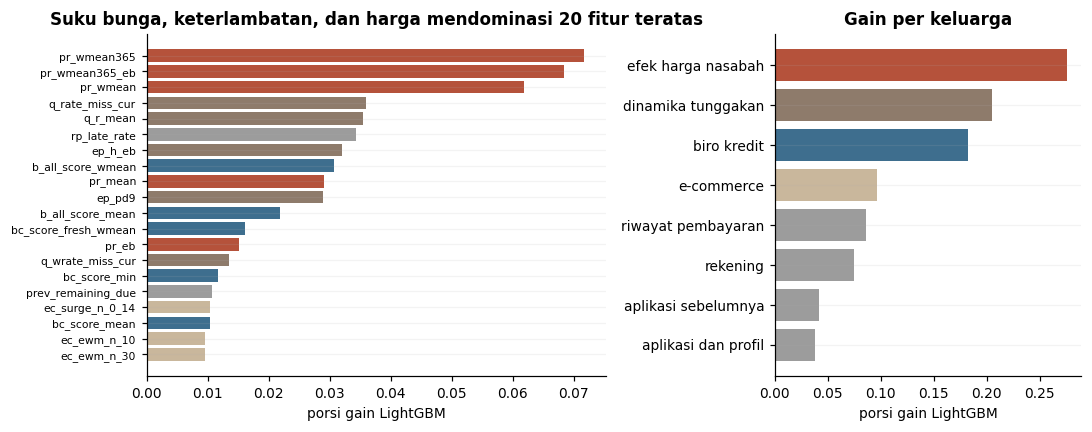

porsi gain per keluarga: efek harga nasabah 0,276, dinamika tunggakan 0,205, biro kredit 0,182, e-commerce 0,096, riwayat pembayaran 0,086, rekening 0,075, aplikasi sebelumnya 0,042, aplikasi dan profil 0,038
Bab 8 selesai: 9,6 menit


In [30]:
S7_NAMES = ['logreg_int_s7', 'lightgbm_s7', 'xgboost_s7']
tampil_tabel(pd.DataFrame(SCOREBOARD), 'Scoreboard anggota (OOF, fold bersama)')
rho_m = pd.DataFrame(spearmanr(np.column_stack([OOF[n] for n in S7_NAMES])).statistic, index=S7_NAMES, columns=S7_NAMES)
tampil_tabel(rho_m.reset_index(names='anggota'), 'Korelasi Spearman antaranggota (OOF)')
g7 = (IMP7 / IMP7.sum()).sort_values(ascending=False)
top = g7.head(20)[::-1]
fam_g = g7.groupby(g7.index.map(keluarga_of)).sum().sort_values(ascending=False)
warna = dict(zip(fam_g.index, [PALET['aksen1'], PALET['utama'], PALET['aksen2'], PALET['lembut']] + ['#9C9C9C'] * 10))
fig, ax = plt.subplots(1, 2, gridspec_kw={'width_ratios': [3, 2]})
ax[0].barh(top.index, top.to_numpy(), color=[warna[keluarga_of(c)] for c in top.index]); ax[0].set_xlabel('porsi gain LightGBM')
ax[0].set_title('Suku bunga, keterlambatan, dan harga mendominasi 20 fitur teratas'); ax[0].tick_params(axis='y', labelsize=7)
ax[1].barh(fam_g.index[::-1], fam_g.to_numpy()[::-1], color=[warna[k] for k in fam_g.index[::-1]]); ax[1].set_xlabel('porsi gain LightGBM')
ax[1].set_title('Gain per keluarga')
plt.tight_layout(); plt.show()
catat('porsi gain per keluarga: ' + ', '.join(f'{k} {angka_id(v, 3)}' for k, v in fam_g.items()))
selesai_bab('Bab 8')

> ### Insights
>
> <<INS_8_5>>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 9. Ensemble dan Kalibrasi <a name="bab9"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## 9.1 *Rank Blend Cross-Fit* <a name="bab9-1"></a>

Karena KS hanya menilai urutan, anggota digabung di ruang persentil (CDF OOF). Bobot dicari dengan *grid* pada AUC, dan agar AUC paket tidak optimistis, bobot untuk *fold* k dipasang hanya pada empat *fold* lain (*cross-fit*). Perkiraan waktu bab: <<WAKTU_EST_9>>.

In [31]:
def to_percentile(reference, values):
    ref = np.sort(reference)
    return np.searchsorted(ref, values, side='right') / len(ref)


def logit(u):
    u = np.clip(u, 1e-6, 1 - 1e-6)
    return np.log(u / (1 - u))


def platt_fit(score, target):
    z = logit(score).reshape(-1, 1)
    return LogisticRegression(C=1e6, max_iter=1000).fit(z, target)


GRID = np.array([w for w in product(np.arange(0, 1.0001, 0.05), repeat=3) if abs(sum(w) - 1) < 1e-9])


def fit_grid(P, idx):
    """Skema 'grid global' S2–S7: bobot dengan AUC terbaik pada baris idx, lalu Platt pada baris yang sama."""
    w = GRID[int(np.argmax([roc_auc_score(y[idx], P[idx] @ w_) for w_ in GRID]))]
    cal = platt_fit(P[idx] @ w, y[idx])
    return (lambda Q: cal.predict_proba(logit(Q @ w).reshape(-1, 1))[:, 1]), w


def blend_paket(names):
    """Rank blend cross-fit: persentil OOF, bobot dan Platt fold k dipasang pada empat fold lain; versi akhir pada semua baris."""
    P_oof = np.column_stack([to_percentile(OOF[n], OOF[n]) for n in names])
    P_te = np.column_stack([to_percentile(OOF[n], TEST[n]) for n in names])
    cf, w_fold = np.zeros(len(y)), []
    for a, b in FOLDS:
        apply, w = fit_grid(P_oof, a); cf[b] = apply(P_oof[b]); w_fold.append(w)
    apply_all, w_all = fit_grid(P_oof, np.arange(len(y)))
    return cf, apply_all(P_oof), apply_all(P_te), w_all, w_fold


t0 = time.time()
S7_BLEND_CF, S7_BLEND_OOF, S7_BLEND_TEST, W7, W7_FOLD = blend_paket(S7_NAMES)
tampil_tabel(pd.DataFrame([[f'fold {k}', *w] for k, w in enumerate(W7_FOLD)] + [['semua baris (akhir)', *W7]], columns=['dipasang pada', *S7_NAMES]),
             'Bobot rank blend (grid 0,05)', desimal=2)
catat(f'blend cross-fit S7: AUC {angka_id(roc_auc_score(y, S7_BLEND_CF))} | KS {angka_id(ks_stat(y, S7_BLEND_CF))} | {len(GRID)} titik grid | '
      f'{angka_id(time.time() - t0, 0)} detik')

**Bobot rank blend (grid 0,05)**

,dipasang pada,logreg_int_s7,lightgbm_s7,xgboost_s7
0,fold 0,"0,40","0,60","0,00"
1,fold 1,"0,35","0,65","0,00"
2,fold 2,"0,40","0,60","0,00"
3,fold 3,"0,45","0,55","0,00"
4,fold 4,"0,40","0,60","0,00"
5,semua baris (akhir),"0,40","0,60","0,00"


blend cross-fit S7: AUC 0,8483 | KS 0,5299 | 231 titik grid | 20 detik


> ### Insights
>
> <<INS_9_1>>

## 9.2 Kalibrasi Platt dan Koreksi Angkatan Keputusan <a name="bab9-2"></a>

Residual paket berbeda menurut minggu keputusan. Sebagian disebabkan aturan kalender DPD-90 (jendela tiga bulan yang memuat Februari lebih pendek dari 91 hari). Pergeseran logit per tanggal keputusan diestimasi dengan kernel Nadaraya–Watson secara *cross-fit*, dan *bandwidth* dipilih dari {7, 14, 30, 60} hari. Koreksi kalender eksak 2 parameter terbukti setara (z −0,51, run Kaggle DSC0082, CLAUDE.md DSC0082), sehingga kernel yang dipertahankan.

In [32]:
def vintage_shift(t_fit, p_fit, y_fit, t_eval, h):
    grid = np.arange(-5, 370, 1.0)
    K = np.exp(-0.5 * ((grid[:, None] - t_fit[None, :]) / h) ** 2)
    shift = (K @ (y_fit - p_fit)) / np.maximum(K @ (p_fit * (1 - p_fit)), 1e-9)
    return np.interp(t_eval, grid, shift)


def heterogeneity(p, groups):
    g = pd.DataFrame({'g': groups, 'r': y - p, 'v': p * (1 - p)}).groupby('g').agg(r=('r', 'sum'), v=('v', 'sum'))
    stat = float((g.r ** 2 / g.v).sum())
    return stat, len(g), float(chi2.sf(stat, len(g)))


def apply_time_nw(blend_cf, blend_oof, blend_test, h):
    """Koreksi angkatan keputusan kernel Nadaraya–Watson: cross-fit untuk OOF, dipasang pada semua baris untuk uji."""
    z = logit_p(blend_cf).copy()
    for a, b in FOLDS:
        z[b] += vintage_shift(t_dec[a], blend_cf[a], y[a], t_dec[b], h)
    z_oof = logit_p(blend_oof) + vintage_shift(t_dec, blend_oof, y, t_dec, h)
    z_te = logit_p(blend_test) + vintage_shift(t_dec, blend_oof, y, t_test, h)
    sig = lambda v: 1 / (1 + np.exp(-v))
    return sig(z), sig(z_oof), sig(z_te)


week = (t_dec // 7).astype(int)
mon = train.decision_datetime.dt.month.to_numpy()
diag_h = []
for h in (7, 14, 30, 60):
    cf_h = apply_time_nw(S7_BLEND_CF, S7_BLEND_OOF, S7_BLEND_TEST, h)[0]
    diag_h.append((h, roc_auc_score(y, cf_h), ks_stat(y, cf_h), heterogeneity(cf_h, week)[0], h == CFG.h_best))
tampil_tabel(pd.DataFrame([('tanpa koreksi', roc_auc_score(y, S7_BLEND_CF), ks_stat(y, S7_BLEND_CF), heterogeneity(S7_BLEND_CF, week)[0], False)]
                          + [(f'kernel {h} hari', a_, k_, c_, p_) for h, a_, k_, c_, p_ in diag_h],
                          columns=['koreksi', 'AUC cross-fit', 'KS cross-fit', 'chi2 mingguan', 'dipakai']),
             'Koreksi angkatan keputusan (bandwidth tetap 14 hari; baris lain diagnostik)')
S7_CF, S7_PROB_OOF, S7_PROB_TEST = apply_time_nw(S7_BLEND_CF, S7_BLEND_OOF, S7_BLEND_TEST, CFG.h_best)
catat(f'heterogeneity mingguan (db {heterogeneity(S7_CF, week)[1]}): {angka_id(heterogeneity(S7_BLEND_CF, week)[0], 1)} -> {angka_id(heterogeneity(S7_CF, week)[0], 1)} | '
      f'bulanan: {angka_id(heterogeneity(S7_BLEND_CF, mon)[0], 1)} -> {angka_id(heterogeneity(S7_CF, mon)[0], 1)}')

**Koreksi angkatan keputusan (bandwidth tetap 14 hari; baris lain diagnostik)**

,koreksi,AUC cross-fit,KS cross-fit,chi2 mingguan,dipakai
0,tanpa koreksi,"0,8483","0,5299","104,2946",tidak
1,kernel 7 hari,"0,8486","0,5291","36,5550",tidak
2,kernel 14 hari,"0,8487","0,5291","51,6071",ya
3,kernel 30 hari,"0,8486","0,5299","62,7515",tidak
4,kernel 60 hari,"0,8485","0,5303","77,6900",tidak


heterogeneity mingguan (db 52): 104,3 -> 51,6 | bulanan: 52,9 -> 4,7


> ### Insights
>
> <<INS_9_2>>

## 9.3 Reproduksi S7 <a name="bab9-3"></a>

**Pra-registrasi 1 (ditulis sebelum hasil).** Pipeline Bab 7–9 harus mereproduksi S7 yang dikirim: Spearman prediksi uji terhadap `submission_s7.csv` run (3) **> 0,999**, dan AUC OOF *cross-fit* dalam **±0,0003** dari 0,8487 (S7_CF 0,84865, run Kaggle DSC0082). Bila salah satu gagal, run dihentikan dan dilaporkan.

In [33]:
S7_AUC, S7_KS = roc_auc_score(y, S7_CF), ks_stat(y, S7_CF)
ref_env = os.environ.get('LOGIKA_S7_REF')
ref_hits = ([Path(ref_env)] if ref_env else []) + (sorted(Path('/kaggle/input').rglob('submission_s7.csv')) if Path('/kaggle/input').exists() else [])
ref_hits = [p for p in ref_hits if p.exists()]
S7_RHO = np.nan
if ref_hits:
    ref = pd.read_csv(ref_hits[0]).set_index('application_id').default_probability.reindex(test.application_id)
    S7_RHO = float(spearmanr(S7_PROB_TEST, ref.to_numpy()).statistic)
cek1 = pd.DataFrame([
    ('AUC OOF cross-fit S7', S7_AUC, f'|AUC − {angka_id(CFG.s7_auc_ref)}| ≤ {angka_id(CFG.s7_auc_tol)}', bool(abs(S7_AUC - CFG.s7_auc_ref) <= CFG.s7_auc_tol)),
    ('Spearman prediksi uji vs submission_s7.csv run (3)', S7_RHO, f'> {angka_id(CFG.s7_rho_min, 3)}', bool(S7_RHO > CFG.s7_rho_min) if np.isfinite(S7_RHO) else np.nan),
], columns=['pemeriksaan', 'nilai', 'kriteria', 'lulus'])
tampil_tabel(cek1.astype(object), 'Pra-registrasi 1: reproduksi S7')
catat(f"S7 cross-fit: AUC {angka_id(S7_AUC)} | KS {angka_id(S7_KS)} | berhistori AUC {angka_id(roc_auc_score(y[HIST], S7_CF[HIST]))} | "
      f"thin-file AUC {angka_id(roc_auc_score(y[~HIST], S7_CF[~HIST]))} | berkas acuan: {ref_hits[0].name if ref_hits else 'tidak dilampirkan (cek Spearman dilewati)'}")
if PROFILE == 'full':
    assert cek1.lulus.iloc[0], f'pra-registrasi 1 gagal: AUC S7 {S7_AUC:.5f} di luar {CFG.s7_auc_ref} ± {CFG.s7_auc_tol}; run dihentikan'
    assert not ref_hits or cek1.lulus.iloc[1], f'pra-registrasi 1 gagal: Spearman uji {S7_RHO:.5f} <= {CFG.s7_rho_min}; run dihentikan'
selesai_bab('Bab 9')

**Pra-registrasi 1: reproduksi S7**

,pemeriksaan,nilai,kriteria,lulus
0,AUC OOF cross-fit S7,"0,8487","|AUC − 0,8487| ≤ 0,0003",ya
1,Spearman prediksi uji vs submission_s7.csv run...,—,"> 0,999",—


S7 cross-fit: AUC 0,8487 | KS 0,5291 | berhistori AUC 0,8542 | thin-file AUC 0,8317 | berkas acuan: tidak dilampirkan (cek Spearman dilewati)
Bab 9 selesai: 0,5 menit


> ### Insights
>
> <<INS_9_3>>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 10. Audit Forensik Kebocoran <a name="bab10"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bab ini meringkas audit Bagian 29 (`DSC0082_Audit_Forensik.ipynb`, run lokal 24 Oktober 2026, CLAUDE.md Bagian 29). Audit tidak dijalankan ulang di sini; semua angka di bab ini berasal dari run itu.

**Pertanyaan.** Apakah ada kolom turunan, ID, tautan antartabel, atau urutan baris yang membawa informasi sesudah `decision_datetime`? Dan apakah ada sumber sah yang belum terpakai di atas S7? Seluruh uji, hipotesis nol, dan kriteria dipra-registrasi di `DSC0082_B29_audit_forensik.md` sebelum eksekusi, dengan Bonferroni m = 48 (z_krit 3,28).

| Bagian | Uji | Hasil (run lokal 24 Oktober 2026) | Putusan |
| --- | --- | --- | --- |
| A. Kolom turunan cicilan | DPD vs umur cicilan, DPD maks vs jarak bayar, bayar sesudah T, rekonstruksi `dpd_T` | DPD tidak pernah melebihi umur cicilan; rekonstruksi eksak pada 58.772 cicilan belum lunas; A2 11 baris kurang bayar 1–2 rupiah (AUC 0,4999) | 8 bersih, 1 anomali netral |
| B. Tabel lain | identitas pesanan, saldo rekening, utilisasi biro, `report`/`available`, ID yatim, pinjaman tanpa cicilan | semua identitas eksak; B3c jeda biro 0 hari 6,3% nasabah (z +3,04, berstrata +1,20); B4c 10 pinjaman jatuh tempo pertamanya tepat = T | 13 bersih, 2 anomali netral |
| C. ID dan urutan | komponen monoton 7 ID, celah penomoran, urutan 6 tabel anak, posisi baris train/test/sample | semua ID heksadesimal acak (\|ρ\| ≤ 0,0008); urutan baris \|ρ\| ≤ 0,0025 | 21 bersih, 3 tidak berlaku |
| Pasca-hoc | `application_id` biro, `loan_id` cicilan | tidak ada yatim; 812 aplikasi lama sejadwal dengan T (AUC 0,5007) | bersih |
| D. Utang di lender lain | residual biro − internal (9 fitur) | uji skor gabungan χ² 7,1 / 9 db, z setara −0,31 (kontrol daya +6,92, kalibrasi −0,10) | negatif |
| E. Kebijakan pemberi pinjaman | guru penolakan, kejutan bunga | guru AUC 0,693, Rao thin +1,67; kejutan bunga z +1,27 | negatif |
| F. Sinyal *thin* NN | lokasi sinyal RealMLP, ≤ 3 fitur eksplisit | sinyal NN terkait `pr_*`; belanja *groceries* 30 hari thin Rao z +4,50 | **positif → Bab 11** |

**Kesimpulan audit.** Dari 48 uji kebocoran yang dipra-registrasi, 0 positif dan 3 anomali netral yang semuanya terjelaskan secara mekanis, sehingga celah ke skor publik teratas tidak berasal dari kebocoran. Temuan metodologis: penyaring residual LightGBM (`resid_boost`) tidak mampu mendeteksi informasi berukuran S7 (dinamika tunggakan di atas S4 z +0,92), sedangkan uji skor gabungan mendeteksinya (z setara +6,92) dan terkalibrasi (−0,10 untuk informasi yang sudah terpakai). Satu-satunya sumber sah baru, belanja *groceries* nasabah *thin-file*, diuji di Bab 11.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 11. Fitur *Groceries* Nasabah *Thin-File* <a name="bab11"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## 11.1 Hipotesis Mekanisme <a name="bab11-1"></a>

Nasabah *thin-file* tidak punya jejak kredit, sehingga komposisi belanja kebutuhan dasar menjelang pengajuan menjadi proksi tekanan likuiditas yang tidak tersedia dari sumber lain: rumah tangga yang anggarannya menyempit menggeser belanja ke kebutuhan pokok. Pada nasabah berhistori, tekanan yang sama sudah terwakili oleh dinamika tunggakan, sehingga efeknya diharapkan hanya muncul di segmen *thin-file*. Perkiraan waktu bab: <<WAKTU_EST_11>>.

## 11.2 Pra-Registrasi <a name="bab11-2"></a>

Ditulis sebelum hasil Bab 11 keluar dan tidak diubah sesudahnya.

| No. | Uji | Kriteria | Peran |
| --- | --- | --- | --- |
| 2 | Uji skor Rao tiap kolom `ek_groc_*` di atas *offset* S7_CF, per segmen | Bonferroni atas (jumlah kolom × 3 segmen); diharapkan `ek_groc_ls_30` thin z > 2,77 sesuai audit | diagnostik |
| 3 | DeLong berpasangan paket *groceries* vs paket S7 pada `FOLDS` yang sama | **z > 2 → lolos gerbang** | keputusan |
| 3 | ΔKS *bootstrap* (70.000 baris) dan subset 9.000 baris | — | informasi |
| 4 | Prediksi ex-ante (binormal, analisis B26): z thin 4,5 → ±+0,0007 AUC thin, ±+0,0002 AUC total | dibandingkan dengan realisasi | kalibrasi harapan |

Fitur masuk ke ketiga anggota, dan bobot *blend* dicari ulang dengan prosedur yang sama, sehingga struktur paket tidak berubah.

## 11.3 Fitur `ek_groc_*` <a name="bab11-3"></a>

| Kolom | Definisi (≤ `decision_datetime`, status *completed*) |
| --- | --- |
| `ek_groc_ls_30`, `ek_groc_ls_90` | log(1 + total belanja *groceries* 30/90 hari) |
| `ek_groc_n_30`, `ek_groc_n_90` | jumlah item *groceries* 30/90 hari |
| `ek_groc_sh_30`, `ek_groc_sh_90` | porsi *groceries* terhadap total belanja 30/90 hari |
| `ek_groc_rel_30` | belanja *groceries* 30 hari dibagi rata-rata pribadi per 30 hari selama 365 hari |

Sel kode menghitung ketujuh kolom, mengasersi bahwa tidak ada transaksi sesudah batas, dan mencetak porsi nasabah yang punya transaksi *groceries* per segmen.

In [34]:
def feat_groceries(path):
    """Keluarga ek_groc_*: belanja groceries 30/90 hari sebelum decision_datetime dari item berstatus completed."""
    ec = pd.read_csv(path, usecols=['customer_id', 'product_category', 'order_status', 'item_total', 'transaction_datetime'],
                     dtype={'customer_id': 'string', 'product_category': 'category', 'order_status': 'category', 'item_total': 'int64'},
                     parse_dates=['transaction_datetime'])
    ec = attach_cut(ec)
    assert (ec.transaction_datetime <= ec.cut).all(), 'transaksi setelah cutoff'
    ec = ec[(ec.transaction_datetime <= ec.cut) & (ec.order_status == 'completed')].copy()
    ec['d'] = (ec.cut - ec.transaction_datetime).dt.total_seconds() / DAY
    ec['groc'] = ec.product_category == 'groceries'
    f = pd.DataFrame(index=APPS.index)
    for w in (30, 90):
        e = ec[ec.d < w]
        g_sp = e[e.groc].groupby('customer_id').item_total.sum().reindex(f.index).fillna(0)
        f[f'ek_groc_ls_{w}'] = np.log1p(g_sp)
        f[f'ek_groc_n_{w}'] = e[e.groc].groupby('customer_id').size().reindex(f.index).fillna(0)
        f[f'ek_groc_sh_{w}'] = safe_div(g_sp, e.groupby('customer_id').item_total.sum().reindex(f.index).fillna(0))
    g365 = ec[ec.groc & (ec.d < 365)].groupby('customer_id').item_total.sum().reindex(f.index).fillna(0)
    f['ek_groc_rel_30'] = safe_div(np.expm1(f.ek_groc_ls_30), g365 * 30 / 365)
    return f


t0 = time.time()
GROC = feat_groceries(CFG.data_dir / 'ecommerce_transactions.csv')
GROC_COLS = list(GROC.columns)
G_tr, G_te = GROC.reindex(train.customer_id).reset_index(drop=True), GROC.reindex(test.customer_id).reset_index(drop=True)
tampil_tabel(pd.DataFrame([(c, *[float(np.nanmean(G_tr[c].to_numpy(float)[m])) for m in (HIST, ~HIST)],
                            *[float(np.isfinite(G_tr[c].to_numpy(float)[m]).mean()) for m in (HIST, ~HIST)]) for c in GROC_COLS],
                          columns=['kolom', 'rata-rata berhistori', 'rata-rata thin-file', 'terisi berhistori', 'terisi thin-file']),
             'Keluarga ek_groc_* per segmen (data latih)', desimal=3)
catat(f"nasabah latih dengan belanja groceries 30 hari: berhistori {angka_id(float((G_tr.ek_groc_n_30.to_numpy()[HIST] > 0).mean()), 3)}, "
      f"thin-file {angka_id(float((G_tr.ek_groc_n_30.to_numpy()[~HIST] > 0).mean()), 3)} | {len(GROC_COLS)} kolom | {angka_id(time.time() - t0, 0)} detik")

**Keluarga ek_groc_* per segmen (data latih)**

,kolom,rata-rata berhistori,rata-rata thin-file,terisi berhistori,terisi thin-file
0,ek_groc_ls_30,"5,356","5,364","1,000","1,000"
1,ek_groc_n_30,"0,942","0,949","1,000","1,000"
2,ek_groc_sh_30,"0,173","0,173","0,731","0,728"
3,ek_groc_ls_90,"9,158","9,122","1,000","1,000"
4,ek_groc_n_90,"2,400","2,410","1,000","1,000"
5,ek_groc_sh_90,"0,140","0,144","0,952","0,949"
6,ek_groc_rel_30,"1,377","1,363","0,979","0,976"


nasabah latih dengan belanja groceries 30 hari: berhistori 0,449, thin-file 0,450 | 7 kolom | 11 detik


> ### Insights
>
> <<INS_11_3>>

## 11.4 Uji Skor Rao di Atas S7 <a name="bab11-4"></a>

Apakah setiap kolom membawa informasi di atas paket S7, dan di segmen mana? Uji skor Rao memakai transformasi peringkat-normal sehingga kebal terhadap skala dan pencilan (pra-registrasi 2).

In [35]:
SEGS = (('semua', np.ones(len(y), bool)), ('berhistori', HIST), ('thin-file', ~HIST))
Z_RAO = float(norm.isf(0.025 / (len(GROC_COLS) * len(SEGS))))
rao = pd.DataFrame([(c, *[score_test(G_tr[c].to_numpy(float), S7_CF, m & np.isfinite(G_tr[c].to_numpy(float))) for _, m in SEGS]) for c in GROC_COLS],
                   columns=['kolom', 'z semua', 'z berhistori', 'z thin-file'])
rao['lolos Bonferroni'] = rao[['z semua', 'z berhistori', 'z thin-file']].abs().max(axis=1) >= Z_RAO
tampil_tabel(rao, f'Pra-registrasi 2: uji skor Rao di atas S7_CF (Bonferroni m = {len(GROC_COLS) * len(SEGS)}, z_krit {angka_id(Z_RAO, 2)})', desimal=2)
Z_LS30_THIN = float(rao.set_index('kolom').loc['ek_groc_ls_30', 'z thin-file'])
catat(f'ek_groc_ls_30 thin-file z {angka_id(Z_LS30_THIN, 2)} (harapan audit > 2,77: {Z_LS30_THIN > 2.77}) | kolom lolos Bonferroni: {int(rao["lolos Bonferroni"].sum())}')

**Pra-registrasi 2: uji skor Rao di atas S7_CF (Bonferroni m = 21, z_krit 3,04)**

,kolom,z semua,z berhistori,z thin-file,lolos Bonferroni
0,ek_groc_ls_30,"1,73","-1,02","4,72",ya
1,ek_groc_n_30,"2,27","-0,27","4,58",ya
2,ek_groc_sh_30,"2,17","0,08","3,96",ya
3,ek_groc_ls_90,"1,73","-0,63","4,12",ya
4,ek_groc_n_90,"2,12","0,09","3,77",ya
5,ek_groc_sh_90,"1,64","0,20","2,75",tidak
6,ek_groc_rel_30,"0,93","-1,68","4,36",ya


ek_groc_ls_30 thin-file z 4,72 (harapan audit > 2,77: True) | kolom lolos Bonferroni: 6


> ### Insights
>
> <<INS_11_4>>

## 11.5 Latih Ulang Tiga Anggota dengan `ek_groc_*` <a name="bab11-5"></a>

Informasi baru baru berguna bila model memanfaatkannya bersama fitur lain. Ketiga anggota dilatih ulang pada X7 + `ek_groc_*` dengan protokol, *fold*, dan seed yang sama dengan Bab 8.

In [36]:
X7g, X7g_test = pd.concat([X7, G_tr], axis=1), pd.concat([X7_test, G_te], axis=1)
X7g_int, X7g_int_test = pd.concat([X7_int, G_tr], axis=1), pd.concat([X7_int_test, G_te], axis=1)
t0 = time.time()
D7g = logreg_design(pd.concat([X7g_int, X7g_int_test], ignore_index=True))
oof, test_pred, _ = logreg_oof(D7g.iloc[:len(X7g)], D7g.iloc[len(X7g):])
report('logreg_int_groc', oof, test_pred, time.time() - t0)
del D7g; _ = gc.collect()
t0 = time.time()
oof, test_pred, IMPG, _ = train_lgb_paket(X7g, X7g_test)
report('lightgbm_groc', oof, test_pred, time.time() - t0)
t0 = time.time()
oof, test_pred = train_xgb(X7g, X7g_test)
report('xgboost_groc', oof, test_pred, time.time() - t0)
GROC_NAMES = ['logreg_int_groc', 'lightgbm_groc', 'xgboost_groc']
mem = []
for new, old in zip(GROC_NAMES, S7_NAMES):
    for seg, m in SEGS:
        d, se, z, _ = delong_test(y, OOF[new], OOF[old], m)
        mem.append((f'{new} vs {old}', seg, d, z))
tampil_tabel(pd.DataFrame(mem, columns=['anggota', 'segmen', 'ΔAUC', 'z']), 'Anggota dengan ek_groc_* vs anggota S7 (DeLong)', desimal=5)
catat(f'porsi gain LightGBM pada ek_groc_*: {angka_id(float((IMPG / IMPG.sum())[GROC_COLS].sum()), 4)}')

logreg_int_groc    AUC 0,8457 | KS 0,5230 | 85 detik
lightgbm_groc      AUC 0,8472 | KS 0,5280 | 248 detik
xgboost_groc       AUC 0,8459 | KS 0,5250 | 231 detik


**Anggota dengan ek_groc_* vs anggota S7 (DeLong)**

,anggota,segmen,ΔAUC,z
0,logreg_int_groc vs logreg_int_s7,semua,"-0,00001","-0,07808"
1,logreg_int_groc vs logreg_int_s7,berhistori,"-0,00010","-1,03044"
2,logreg_int_groc vs logreg_int_s7,thin-file,"0,00027","1,30872"
3,lightgbm_groc vs lightgbm_s7,semua,"-0,00003","-0,18991"
4,lightgbm_groc vs lightgbm_s7,berhistori,"-0,00015","-0,76650"
5,lightgbm_groc vs lightgbm_s7,thin-file,"0,00029","0,85500"
6,xgboost_groc vs xgboost_s7,semua,"0,00016","0,64204"
7,xgboost_groc vs xgboost_s7,berhistori,"0,00014","0,46411"
8,xgboost_groc vs xgboost_s7,thin-file,"0,00018","0,40331"


porsi gain LightGBM pada ek_groc_*: 0,0073


> ### Insights
>
> <<INS_11_5>>

## 11.6 Paket *Groceries* dan Gerbang DeLong <a name="bab11-6"></a>

Apakah paket dengan fitur *groceries* lebih baik daripada S7 pada *fold* yang sama (pra-registrasi 3), dan berapa realisasinya dibanding prediksi ex-ante (pra-registrasi 4)? Paket dibangun dengan *blend*, Platt, dan koreksi angkatan yang sama dengan Bab 9.

In [37]:
G_BLEND_CF, G_BLEND_OOF, G_BLEND_TEST, WG, WG_FOLD = blend_paket(GROC_NAMES)
G_CF, G_PROB_OOF, G_PROB_TEST = apply_time_nw(G_BLEND_CF, G_BLEND_OOF, G_BLEND_TEST, CFG.h_best)
rows = []
for seg, m in SEGS:
    d, se, z, _ = delong_test(y, G_CF, S7_CF, m)
    rows.append((seg, roc_auc_score(y[m], G_CF[m]), roc_auc_score(y[m], S7_CF[m]), d, se, z, ks_stat(y[m], G_CF[m]) - ks_stat(y[m], S7_CF[m])))
GATE = pd.DataFrame(rows, columns=['segmen', 'AUC groceries', 'AUC S7', 'ΔAUC', 'SE', 'z', 'ΔKS'])
tampil_tabel(GATE, 'Pra-registrasi 3: paket groceries vs paket S7 (DeLong, fold sama)', desimal=5)
rng_b = np.random.default_rng(CFG.seed); boot_full, boot_pub = [], []
for _ in range(CFG.bootstrap):
    i = rng_b.integers(0, len(y), len(y)); boot_full.append(ks_stat(y[i], G_CF[i]) - ks_stat(y[i], S7_CF[i]))
    j = rng_b.choice(len(y), min(9000, len(y)), replace=False); boot_pub.append(ks_stat(y[j], G_CF[j]) - ks_stat(y[j], S7_CF[j]))
boot_full, boot_pub = np.array(boot_full), np.array(boot_pub)
GROC_Z = float(GATE.z.iloc[0])
LOLOS = bool(np.isfinite(GROC_Z) and GROC_Z > CFG.select_z)
gr = GATE.set_index('segmen')
tampil_tabel(pd.DataFrame([
    ('ΔAUC total', 0.0002, gr.loc['semua', 'ΔAUC']), ('ΔAUC thin-file', 0.0007, gr.loc['thin-file', 'ΔAUC']),
    ('ΔKS bootstrap 70.000 baris (rata-rata)', np.nan, boot_full.mean()), ('P(ΔKS > 0), 70.000 baris', np.nan, (boot_full > 0).mean()),
    ('ΔKS subset 9.000 baris (rata-rata)', np.nan, boot_pub.mean()), ('P(ΔKS > 0), subset 9.000', np.nan, (boot_pub > 0).mean())],
    columns=['besaran', 'prediksi ex-ante (pra-registrasi 4)', 'realisasi']), 'Pra-registrasi 4 dan informasi KS', desimal=5)
tampil_tabel(pd.DataFrame([('DeLong paket groceries vs S7, semua baris', GROC_Z, f'z > {angka_id(CFG.select_z, 1)}', LOLOS, 'groceries' if LOLOS else 'S7')],
                          columns=['gerbang', 'z', 'kriteria', 'lolos', 'submission.csv']).astype(object), 'Keputusan gerbang')
catat('bobot blend groceries: ' + ', '.join(f'{n} {angka_id(float(w), 2)}' for n, w in zip(GROC_NAMES, WG))
      + f' | Spearman uji groceries vs S7 {angka_id(float(spearmanr(G_PROB_TEST, S7_PROB_TEST).statistic))}')
selesai_bab('Bab 11')

**Pra-registrasi 3: paket groceries vs paket S7 (DeLong, fold sama)**

,segmen,AUC groceries,AUC S7,ΔAUC,SE,z,ΔKS
0,semua,"0,84864","0,84865","-0,00001","0,00011","-0,06350","-0,00024"
1,berhistori,"0,85410","0,85423","-0,00013","0,00012","-1,03082","-0,00278"
2,thin-file,"0,83206","0,83173","0,00033","0,00025","1,29820","-0,00054"


**Pra-registrasi 4 dan informasi KS**

,besaran,prediksi ex-ante (pra-registrasi 4),realisasi
0,ΔAUC total,"0,00020","-0,00001"
1,ΔAUC thin-file,"0,00070","0,00033"
2,ΔKS bootstrap 70.000 baris (rata-rata),—,"-0,00049"
3,"P(ΔKS > 0), 70.000 baris",—,"0,31333"
4,ΔKS subset 9.000 baris (rata-rata),—,"-0,00076"
5,"P(ΔKS > 0), subset 9.000",—,"0,36000"


**Keputusan gerbang**

,gerbang,z,kriteria,lolos,submission.csv
0,"DeLong paket groceries vs S7, semua baris","-0,0635","z > 2,0",tidak,S7


bobot blend groceries: logreg_int_groc 0,40, lightgbm_groc 0,60, xgboost_groc 0,00 | Spearman uji groceries vs S7 0,9992
Bab 11 selesai: 12,2 menit


> ### Insights
>
> <<INS_11_6>>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 12. Submisi <a name="bab12"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## 12.1 Penulisan Berkas dan Asersi Format <a name="bab12-1"></a>

Apakah kedua berkas memenuhi format panitia? Prediksi dipetakan ke urutan `sample_submission` lewat `application_id`, lalu diperiksa: jumlah baris, ID unik dan lengkap, nilai dalam [0, 1], dan tanpa nilai hilang. Perkiraan waktu bab: <<WAKTU_EST_12>>.

In [38]:
def write_sub(prob, path):
    pred = pd.Series(prob, index=test.application_id.to_numpy())
    sub = pd.DataFrame({'application_id': sample_submission.application_id,
                        'default_probability': pred.reindex(sample_submission.application_id).to_numpy()})
    assert sub.application_id.tolist() == sample_submission.application_id.tolist()
    assert sub.default_probability.notna().all()
    assert sub.default_probability.between(0, 1).all()
    assert len(sub) == len(sample_submission)
    sub.to_csv(path, index=False)
    return sub


FILES = {'submission_final_s7.csv': S7_PROB_TEST, 'submission_final_groc.csv': G_PROB_TEST}
cek = []
for fn, p in FILES.items():
    s_ = write_sub(p, CFG.out_dir / fn)
    back = pd.read_csv(CFG.out_dir / fn)
    cek.append((fn, len(back) == len(sample_submission), back.application_id.tolist() == sample_submission.application_id.tolist(),
                back.application_id.is_unique, bool(back.default_probability.notna().all()), bool(back.default_probability.between(0, 1).all())))
CEK_FORMAT = pd.DataFrame(cek, columns=['berkas', 'jumlah baris', 'urutan = sample_submission', 'ID unik', 'tanpa nilai hilang', 'nilai dalam [0, 1]'])
tampil_tabel(CEK_FORMAT, 'Asersi format berkas submisi')
assert CEK_FORMAT.drop(columns='berkas').all().all()

**Asersi format berkas submisi**

,berkas,jumlah baris,urutan = sample_submission,ID unik,tanpa nilai hilang,"nilai dalam [0, 1]"
0,submission_final_s7.csv,ya,ya,ya,ya,ya
1,submission_final_groc.csv,ya,ya,ya,ya,ya


> ### Insights
>
> <<INS_12_1>>

## 12.2 Keputusan `submission.csv` <a name="bab12-2"></a>

`submission.csv` sama dengan versi *groceries* bila gerbang §11.6 lolos, dan sama dengan reproduksi S7 bila tidak. Berkas `submission.csv` run (3) di folder proyek tidak disentuh.

In [39]:
PILIHAN = 'submission_final_groc.csv' if LOLOS else 'submission_final_s7.csv'
write_sub(FILES[PILIHAN], CFG.out_dir / 'submission.csv')
tampil_tabel(pd.DataFrame([('gerbang groceries (z > 2)', GROC_Z, LOLOS, PILIHAN)], columns=['dasar', 'z', 'lolos', 'submission.csv']).astype(object),
             'Keputusan submission.csv')


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


SHA = {fn: sha256_file(CFG.out_dir / fn) for fn in (*FILES, 'submission.csv')}
tampil_tabel(pd.DataFrame([(fn, (CFG.out_dir / fn).stat().st_size / 1e6, sha) for fn, sha in SHA.items()], columns=['berkas', 'ukuran (MB)', 'SHA-256']),
             'Berkas keluaran', desimal=2)
assert SHA['submission.csv'] == SHA[PILIHAN]

**Keputusan submission.csv**

,dasar,z,lolos,submission.csv
0,gerbang groceries (z > 2),"-0,0635",tidak,submission_final_s7.csv


**Berkas keluaran**

,berkas,ukuran (MB),SHA-256
0,submission_final_s7.csv,"1,17",a86ed209646c20e591c94ba21b0f611ea95e2bdef00a17...
1,submission_final_groc.csv,"1,17",c29dd0d9a572819c655defcc99b25f7eb3a86a8af563c2...
2,submission.csv,"1,17",a86ed209646c20e591c94ba21b0f611ea95e2bdef00a17...


> ### Insights
>
> <<INS_12_2>>

## 12.3 *Manifest* Reproduksibilitas <a name="bab12-3"></a>

Apa yang dibutuhkan untuk mengulang run ini persis? *Manifest* mencatat versi Python dan pustaka, seed, jumlah *thread*, profil, ukuran data, bobot *blend*, *bandwidth*, hasil gerbang, SHA-256 berkas, serta waktu per bab dan total.

In [40]:
selesai_bab('Bab 12')
manifest = {'profil': PROFILE, 'versi': VERSI, 'config': {k: str(v) for k, v in asdict(CFG).items()}, 'thread': CFG.n_jobs,
            'data': {n: int(len(f)) for n, (f, _) in TABLES.items()}, 'kolom': {'X4': X4.shape[1], 'X7': X7.shape[1], 'X7_int': X7_int.shape[1],
                                                                              'dinamika': len(Q_COLS), 'groceries': GROC_COLS},
            'adversarial_auc': ADV_AUC, 'scoreboard': SCOREBOARD, 'bobot_s7': dict(zip(S7_NAMES, map(float, W7))),
            'bobot_groc': dict(zip(GROC_NAMES, map(float, WG))), 'h_best': CFG.h_best,
            's7': {'auc_cf': S7_AUC, 'ks_cf': S7_KS, 'spearman_ref': S7_RHO, 'ref': str(ref_hits[0]) if ref_hits else None},
            'rao_groc': rao.to_dict('records'), 'gerbang': GATE.to_dict('records'), 'groc_z': GROC_Z, 'lolos': LOLOS, 'pilihan': PILIHAN,
            'dks_boot': [float(boot_full.mean()), float(boot_full.std()), float(boot_pub.mean()), float(boot_pub.std())],
            'sha256': SHA, 'waktu_menit': {k: v / 60 for k, v in WAKTU.items()}, 'total_menit': (time.time() - RUN_T0) / 60}
(CFG.out_dir / 'run_manifest.json').write_text(json.dumps(manifest, indent=2, default=float))
tampil_tabel(pd.DataFrame([(k, v / 60) for k, v in WAKTU.items()] + [('total sampai Bab 12', (time.time() - RUN_T0) / 60)], columns=['bab', 'menit']),
             'Waktu per bab', desimal=1)
catat(f'run_manifest.json ditulis ({angka_id((CFG.out_dir / "run_manifest.json").stat().st_size / 1e3, 1)} KB)')

Bab 12 selesai: 0,0 menit


**Waktu per bab**

,bab,menit
0,Bab 4,"0,5"
1,Bab 5,"0,4"
2,Bab 6,"0,1"
3,Bab 7,"1,3"
4,Bab 8,"9,6"
5,Bab 9,"0,5"
6,Bab 11,"12,2"
7,Bab 12,"0,0"
8,total sampai Bab 12,"24,7"


run_manifest.json ditulis (6,9 KB)


> ### Insights
>
> <<INS_12_3>>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 13. Paket Privat: S8 + LightGBM Hibrida, Dapat Direproduksi <a name="bab13"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bab ini membangun paket untuk **leaderboard privat** dari data panitia saja. Paket ini menggabungkan dua perbaikan yang masing-masing sudah terbukti di atas S7:
- **S8** (Bagian 22, run Kaggle (3)): S7 + RealMLP + TabM pada X7, AUC *cross-fit* 0,84893 / KS 0,5289, ΔAUC +0,00028 (z 2,11) vs S7.
- **LightGBM hibrida** (Bagian 35): LightGBM `t9x` di atas logit regresi logistik bersarang, AUC 0,84751 lokal dan 0,8475 di run Kaggle (7). Kekuatannya di thin-file (0,83166 vs `lightgbm_s7` 0,83024).

Uji lokal 29 Oktober (`s8hyb.py`; anggota S7/NN dari output Kaggle run S8, hibrida dari run lokal). Prosedur paket diverifikasi: S7 dan S8 yang dibangun ulang sama persis dengan Kaggle (0,84865 / 0,84893), dan prediksi uji S8 identik dengan `submission_s8.csv` (selisih 3e-16).
- **S8 + hibrida: AUC 0,84915 / KS 0,5299, ΔAUC +0,00022 (z +2,73) vs S8**; berhistori z +1,80, thin-file z +2,04.
- ΔKS *bootstrap* +0,0010 (CI 95% [−0,0009; +0,0024], P > 0 = 0,80); 4/5 *fold* positif.
- Bobot: `lightgbm_s7` 0,30 / RealMLP 0,20 / TabM 0,10 / hibrida 0,40 (LR dan XGB 0); Spearman uji vs S8 0,9996.

Prediksi uji hibrida dalam uji itu berasal dari laptop, sehingga belum dapat direproduksi. Bab ini melatih ulang **seluruh** anggota di Kaggle dengan resep yang sama:
- RealMLP/TabM: kode §13.4 notebook Publik (yang mereproduksi `s4nn` persis), dijalankan pada X7;
- hibrida: kode §13.3 notebook Publik dengan desain regresi logistik X7.

Perkiraan waktu bab: <<WAKTU_EST_13>> (GPU T4 untuk RealMLP/TabM; hibrida di CPU ±90–120 menit).

## 13.1 Pra-Registrasi <a name="bab13-1"></a>

Ditulis sebelum run Kaggle dan tidak diubah sesudahnya:

| No. | Uji | Kriteria | Peran |
| --- | --- | --- | --- |
| 11 | `lightgbm_hyb`: hibrida LR → `t9x` pada X7, resep §8.3 (3 pembagian + *refit*); regresi logistik T pada pembagian 42 diasersi identik dengan `logreg_int_s7` | AUC dilaporkan; acuan lokal 0,84751, run Kaggle (7) 0,8475 | reproduksi |
| 12 | `realmlp_s8` + `tabm_s8` pada X7 (resep Bagian 22: `QuantileTransformer` per *fold*, indikator pola hilang, potongan dalam 10%, 2 *seed*) | AUC dilaporkan; acuan run (3) 0,8470 / 0,8464 | reproduksi S8 |
| 13 | Paket **S8** = S7 + RealMLP + TabM (grid 0,05, Platt, kernel NW 14 hari) vs `S7_CF` | acuan run (3) AUC 0,84893, z 2,11 | reproduksi |
| 14 | **Paket `S8_hyb`** = S8 + `lightgbm_hyb` (grid 0,1 untuk 6 anggota) vs S8 (DeLong, *fold* sama) | **z > 2** → `submission.csv` = `S8_hyb`; selain itu S8 (atau S7 bila NN gagal) | **keputusan** |
| 15 | Ex-ante (uji lokal): ΔAUC +0,00022 (z +2,73), KS ±0,530. Dengan SE ±0,00008, peluang z > 2 ±75%. Bila NN gagal, pembandingnya S7 dan kandidatnya S7 + hibrida (lokal +0,00031, z +2,87 vs S7) | dibandingkan dengan realisasi | kalibrasi harapan |

Berkas `submission_privat_s7.csv`, `submission_privat_s8.csv` (bila NN berhasil), dan `submission_privat_s8_hyb.csv` **selalu ditulis**. Di Kaggle, dua pilihan final privat **tetap dipilih manual**. Rekomendasi sebelum run: paket terpilih (`submission.csv`) + S7.

## 13.2 LightGBM Hibrida pada X7 <a name="bab13-2"></a>

Konfigurasi `t9x` (lr 0,01, 9 daun, `min_child_samples` 200, `feature_fraction` 0,2, `lambda_l2` 10, `path_smooth` 10, `extra_trees`) dilatih dengan resep §8.3 persis. `init_score` = logit regresi logistik X7 bersarang: baris T dari 5 *fold* dalam T, V dan uji dari regresi logistik pada seluruh T. *Refit* memakai OOF `logreg_int_s7`. Fungsi `lr_fit_idx` dan `train_lgb_resep` sama dengan notebook Publik §13.3.

In [41]:
LGB_T9X = {**LGB_PARAMS, 'learning_rate': 0.01, 'num_leaves': 9, 'min_child_samples': 200, 'feature_fraction': 0.2,
           'lambda_l2': 10.0, 'path_smooth': 10.0, 'extra_trees': True}
T9X_ROUNDS, T9X_ES = (20000, 600) if PROFILE == 'full' else (CFG.lgb_rounds, CFG.early_stopping)


def lr_fit_idx(design, idx):
    """Regresi logistik §8.2 (median, clip 1-99%, standardisasi, C CFG.logreg_c) dipasang pada baris idx; mengembalikan fungsi logit."""
    med = design.iloc[idx].median(); lo, hi = design.iloc[idx].quantile(0.01), design.iloc[idx].quantile(0.99)
    prep = lambda d: d.fillna(med).clip(lo, hi, axis=1)
    scaler = StandardScaler().fit(prep(design.iloc[idx]))
    model = LogisticRegression(C=CFG.logreg_c, max_iter=3000).fit(scaler.transform(prep(design.iloc[idx])), y[idx])
    return lambda d: model.decision_function(scaler.transform(prep(d)))


def train_lgb_resep(Xtr, Xte, params, rounds, es, design=None, design_te=None, lr_name=None):
    """Resep §8.3 dengan parameter sebagai argumen; bila design diberikan, hibrida LR -> LightGBM (init_score logit LR bersarang)."""
    so, st, its, cek = [], [], [], []
    hyb = design is not None
    for split_seed in (CFG.seed,) + tuple(CFG.extra_split_seeds):
        folds = FOLDS if split_seed == CFG.seed else list(StratifiedKFold(CFG.n_folds, shuffle=True, random_state=split_seed).split(Xtr, y))
        seed = CFG.lgb_seed if split_seed == CFG.seed else CFG.seed
        oof = np.zeros(len(Xtr)); tp = np.zeros(len(Xte))
        for k, (a, b) in enumerate(folds):
            if hyb:
                init_a = np.zeros(len(a))
                for ia, ib in StratifiedKFold(CFG.n_folds, shuffle=True, random_state=100 + k).split(a, y[a]):
                    init_a[ib] = lr_fit_idx(design, a[ia])(design.iloc[a[ib]])
                f = lr_fit_idx(design, a); init_b, init_te = f(design.iloc[b]), f(design_te)
                if split_seed == CFG.seed:
                    cek.append(float(np.abs(init_b - OOF[lr_name][b]).max()))
                d_tr, d_va = lgb.Dataset(Xtr.iloc[a], y[a], init_score=init_a), lgb.Dataset(Xtr.iloc[b], y[b], init_score=init_b)
            else:
                init_b = init_te = 0.0
                d_tr, d_va = lgb.Dataset(Xtr.iloc[a], y[a]), lgb.Dataset(Xtr.iloc[b], y[b])
            bst = lgb.train({**params, 'seed': seed}, d_tr, rounds, valid_sets=[d_va], callbacks=[lgb.early_stopping(es, verbose=False)])
            oof[b] = init_b + bst.predict(Xtr.iloc[b], num_iteration=bst.best_iteration, raw_score=hyb)
            tp += (init_te + bst.predict(Xte, num_iteration=bst.best_iteration, raw_score=hyb)) / len(folds); its.append(bst.best_iteration)
        so.append(oof); st.append(tp)
        catat(f'  pembagian {split_seed}: AUC {angka_id(roc_auc_score(y, oof))} | rata-rata {len(so)} pembagian {angka_id(roc_auc_score(y, np.mean(so, axis=0)))} | '
              f'ronde {its[-len(folds):]}')
    if hyb:
        full = lgb.train({**params, 'seed': CFG.seed}, lgb.Dataset(Xtr, y, init_score=OOF[lr_name]), int(1.15 * np.mean(its)))
        test_full = TEST[lr_name] + full.predict(Xte, raw_score=True)
    else:
        full = lgb.train({**params, 'seed': CFG.seed}, lgb.Dataset(Xtr, y), int(1.15 * np.mean(its)))
        test_full = full.predict(Xte)
    return np.mean(so, axis=0), 0.5 * np.mean(st, axis=0) + 0.5 * test_full, its, cek


t0 = time.time()
D7h = logreg_design(pd.concat([X7_int, X7_int_test], ignore_index=True))
D7h_tr, D7h_te = D7h.iloc[:len(y)], D7h.iloc[len(y):]
del D7h; _ = gc.collect()
oof, test_pred, ITERS_HYB, CEK_LR7 = train_lgb_resep(X7, X7_test, LGB_T9X, T9X_ROUNDS, T9X_ES, D7h_tr, D7h_te, 'logreg_int_s7')
assert max(CEK_LR7) < 1e-6, f'regresi logistik T tidak mereproduksi logreg_int_s7 (selisih maks {max(CEK_LR7):.2e})'
report('lightgbm_hyb', oof, test_pred, time.time() - t0)
del D7h_tr, D7h_te; _ = gc.collect()
MEM_HYB = pd.DataFrame([(seg, roc_auc_score(y[m], OOF['lightgbm_hyb'][m]), roc_auc_score(y[m], OOF['lightgbm_s7'][m]), *delong_test(y, OOF['lightgbm_hyb'], OOF['lightgbm_s7'], m)[:3])
                        for seg, m in SEGS], columns=['segmen', 'AUC lightgbm_hyb', 'AUC lightgbm_s7', 'ΔAUC', 'SE', 'z'])
tampil_tabel(MEM_HYB, 'Pra-registrasi 11: lightgbm_hyb vs lightgbm_s7 (DeLong, fold sama)', desimal=5)
catat(f"lightgbm_hyb: AUC {angka_id(roc_auc_score(y, OOF['lightgbm_hyb']), 5)} (acuan lokal 0,84751; Kaggle run (7) 0,8475) | thin "
      f"{angka_id(roc_auc_score(y[~HIST], OOF['lightgbm_hyb'][~HIST]), 5)} | LR T = logreg_int_s7 (selisih maks {max(CEK_LR7):.1e}) | ronde median {int(np.median(ITERS_HYB))} | "
      f"Spearman OOF vs lightgbm_s7 {angka_id(float(spearmanr(OOF['lightgbm_hyb'], OOF['lightgbm_s7']).statistic), 4)}")

  pembagian 42: AUC 0,8467 | rata-rata 1 pembagian 0,8467 | ronde [2927, 1829, 2022, 2707, 1027]
  pembagian 2026: AUC 0,8470 | rata-rata 2 pembagian 0,8473 | ronde [1905, 2880, 1442, 1876, 1428]
  pembagian 7: AUC 0,8470 | rata-rata 3 pembagian 0,8475 | ronde [2103, 980, 3676, 1013, 1606]
lightgbm_hyb       AUC 0,8475 | KS 0,5275 | 1.652 detik


**Pra-registrasi 11: lightgbm_hyb vs lightgbm_s7 (DeLong, fold sama)**

,segmen,AUC lightgbm_hyb,AUC lightgbm_s7,ΔAUC,SE,z
0,semua,"0,84750","0,84725","0,00025","0,00046","0,54738"
1,berhistori,"0,85267","0,85274","-0,00007","0,00056","-0,12617"
2,thin-file,"0,83169","0,83043","0,00125","0,00067","1,88025"


lightgbm_hyb: AUC 0,84750 (acuan lokal 0,84751; Kaggle run (7) 0,8475) | thin 0,83169 | LR T = logreg_int_s7 (selisih maks 0.0e+00) | ronde median 1876 | Spearman OOF vs lightgbm_s7 0,9836


> ### Insights
>
> <<INS_13_2>>

## 13.3 Anggota NN S8: RealMLP dan TabM pada X7 <a name="bab13-3"></a>

Kode anggota NN disalin apa adanya dari notebook Publik §13.4, yang mereproduksi `s4nn` persis (RealMLP 0,8451 / TabM 0,8448 = run (3)). Masukannya di sini X7, sama seperti S8 di Bagian 22:
- numerik X7 tanpa kolom konstan, satu indikator per **pola** hilang, dan 4 kolom kategorikal;
- `QuantileTransformer` per *fold* pada baris latih-dalam saja, dengan potongan dalam 10% (`random_state = k`);
- **RealMLP-TD** (Holzmüller dkk., 2024, arXiv:2407.04491) lewat `pytabkit`, dan **TabM** (Gorishniy dkk., 2025, arXiv:2410.24210), masing-masing 2 *seed*.

`pytabkit`, `tabm`, dan `rtdl_num_embeddings` dipasang dengan `pip` bila belum ada (Kaggle: **Internet On**, **GPU T4**). Bila pemasangan gagal atau versi paket inti berubah, anggota dilewati dengan rapi, dan paket privat menjadi S7 + hibrida.

In [42]:
import importlib
import importlib.metadata as ilm
import logging
import subprocess
import sys
import traceback
from sklearn.metrics import log_loss
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer

NN_CORE = ['numpy', 'pandas', 'scikit-learn', 'scipy', 'lightgbm', 'xgboost']


def core_versions():
    out = {}
    for p_ in NN_CORE + ['torch']:
        try:
            out[p_] = ilm.version(p_)
        except ilm.PackageNotFoundError:
            out[p_] = None
    return out


def ensure_pkg(module, spec):
    try:
        return importlib.import_module(module), 'sudah terpasang'
    except ImportError:
        pass
    try:
        r_ = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', spec], capture_output=True, text=True, timeout=900)
        if r_.returncode != 0:
            tail = (r_.stderr or r_.stdout).strip().splitlines()
            return None, 'pip gagal: ' + (tail[-1][:200] if tail else f'kode {r_.returncode}')
        importlib.invalidate_caches()
        return importlib.import_module(module), 'dipasang'
    except Exception as e:
        return None, f'{type(e).__name__}: {e}'[:200]


t0 = time.time()
NN_STATUS = {}
v_before = core_versions()
torch, s_torch = ensure_pkg('torch', 'torch')
pytabkit, s_ptk = ensure_pkg('pytabkit', 'pytabkit') if torch is not None else (None, 'torch tidak ada')
tabm, s_tabm = ensure_pkg('tabm', 'tabm') if torch is not None else (None, 'torch tidak ada')
rtdl_num_embeddings, s_rtdl = ensure_pkg('rtdl_num_embeddings', 'rtdl_num_embeddings') if tabm is not None else (None, 'tidak dicoba')
v_after = core_versions()
NN_ENV_CHANGED = {p_: (v_before[p_], v_after[p_]) for p_ in NN_CORE if v_before[p_] != v_after[p_]}
for nm in ('pytorch_lightning', 'lightning.pytorch', 'lightning_fabric', 'lightning'):
    logging.getLogger(nm).setLevel(logging.ERROR)
NN_STATUS['realmlp_s8'] = 'siap' if pytabkit is not None and not NN_ENV_CHANGED else f'dilewati: pytabkit {s_ptk}'
NN_STATUS['tabm_s8'] = 'siap' if tabm is not None and rtdl_num_embeddings is not None and not NN_ENV_CHANGED else f'dilewati: tabm {s_tabm} / rtdl {s_rtdl}'
if NN_ENV_CHANGED:
    NN_STATUS = {k_: 'dilewati: versi paket inti berubah setelah pip ' + str(NN_ENV_CHANGED) for k_ in NN_STATUS}
DEVICE = torch.device('cuda' if torch is not None and torch.cuda.is_available() else 'cpu') if torch is not None else None
NNP = dict(seeds=(CFG.seed, 2026), inner=0.1, rm_epochs=256, rm_batch=256, rm_time=1500,
           tm_k=32, tm_blocks=2, tm_d=512, tm_bins=48, tm_demb=16, tm_lr=2e-3, tm_wd=3e-4, tm_clip=1.0,
           tm_batch=256, tm_epochs=100, tm_patience=16, tm_eval_bs=1024)
if PROFILE == 'smoke':
    NNP.update(rm_epochs=3, rm_time=300, tm_k=4, tm_d=64, tm_bins=8, tm_demb=8, tm_epochs=3, tm_patience=1, tm_batch=512)
elif DEVICE is not None and DEVICE.type == 'cpu':
    catat('PERINGATAN: GPU tidak terdeteksi; RealMLP dan TabM diperkecil agar selesai di CPU. Aktifkan Accelerator GPU di Kaggle untuk versi penuh.')
    NNP.update(rm_epochs=32, rm_time=900, tm_k=8, tm_d=256, tm_bins=16, tm_demb=8, tm_epochs=20, tm_patience=4, tm_batch=512)
tampil_tabel(pd.DataFrame([('torch', s_torch, v_after.get('torch') or '-'), ('pytabkit', s_ptk, ilm.version('pytabkit') if pytabkit is not None else '-'),
                           ('tabm', s_tabm, ilm.version('tabm') if tabm is not None else '-'),
                           ('rtdl_num_embeddings', s_rtdl, ilm.version('rtdl_num_embeddings') if rtdl_num_embeddings is not None else '-')],
                          columns=['paket', 'status', 'versi']), 'Paket NN')


def make_design(Xtr, Xte, tag):
    """Matriks NN: numerik (tanpa kolom konstan), indikator per pola hilang, kode kategorikal (Bagian 22.2)."""
    num_all = [c for c in Xtr.columns if c not in CAT_COLS]
    XN = Xtr[num_all].to_numpy(np.float32, copy=True); XN_TE = Xte[num_all].to_numpy(np.float32, copy=True)
    XN[~np.isfinite(XN)] = np.nan; XN_TE[~np.isfinite(XN_TE)] = np.nan
    fin = np.isfinite(XN)
    varies = (fin.sum(0) >= 2) & (np.where(fin, XN, -np.inf).max(0) > np.where(fin, XN, np.inf).min(0))
    num = [c for c, v in zip(num_all, varies) if v]
    XN, XN_TE = XN[:, varies], XN_TE[:, varies]
    miss_tr, miss_te = np.isnan(XN), np.isnan(XN_TE)
    rate = miss_tr.mean(0); seen, miss = set(), []
    for j in np.where((rate > 0) & (rate < 1))[0]:
        key = hashlib.md5(np.packbits(miss_tr[:, j]).tobytes()).hexdigest()
        if key not in seen:
            seen.add(key); miss.append(int(j))
    XC = np.column_stack([Xtr[c].cat.codes.to_numpy() + 1 for c in CAT_COLS] + [miss_tr[:, j] for j in miss]).astype(np.int64)
    XC_TE = np.column_stack([Xte[c].cat.codes.to_numpy() + 1 for c in CAT_COLS] + [miss_te[:, j] for j in miss]).astype(np.int64)
    D = dict(tag=tag, num=num, XN=XN, XN_TE=XN_TE, XC=XC, XC_TE=XC_TE, cat=list(CAT_COLS) + [f'miss__{num[j]}' for j in miss],
             card=[int(max(XC[:, j].max(), XC_TE[:, j].max())) + 1 for j in range(XC.shape[1])], miss=miss, fold={})
    catat(f'[{tag}] numerik {len(num)} (dibuang konstan {len(num_all) - len(num)}) | {len(miss)} pola indikator hilang | kategorikal {len(CAT_COLS)}')
    return D


def nn_fold(D, k, a):
    if k not in D['fold']:
        ai, av = train_test_split(a, test_size=NNP['inner'], stratify=y[a], random_state=k)
        noise = np.random.default_rng(CFG.seed + k).normal(0.0, 1e-5, (len(ai), D['XN'].shape[1])).astype(np.float32)
        qt = QuantileTransformer(n_quantiles=max(min(len(ai) // 30, 1000), 10), output_distribution='normal',
                                 subsample=10**9, random_state=CFG.seed).fit(D['XN'][ai] + noise)
        D['fold'][k] = (ai, av, qt)
    return D['fold'][k]


def nn_num(qt, Xn):
    return np.nan_to_num(qt.transform(Xn).astype(np.float32), nan=0.0)


def realmlp_member(D):
    from pytabkit import RealMLP_TD_Classifier
    XN, XN_TE, XC, XC_TE, CATN, CARDN = D['XN'], D['XN_TE'], D['XC'], D['XC_TE'], D['cat'], D['card']

    def frame(Xn, Xc, qt):
        num = pd.DataFrame(nn_num(qt, Xn), columns=[f'n{j}' for j in range(Xn.shape[1])])
        cat = pd.DataFrame({c: pd.Categorical(Xc[:, j], categories=range(CARDN[j])) for j, c in enumerate(CATN)})
        return pd.concat([num, cat], axis=1)

    oof, test_pred = np.zeros(len(y)), np.zeros(len(XN_TE))
    for k, (a, b) in enumerate(FOLDS):
        ai, av, qt = nn_fold(D, k, a); rows = np.concatenate([ai, av])
        clf = RealMLP_TD_Classifier(device='cuda' if DEVICE.type == 'cuda' else 'cpu', random_state=CFG.seed + k, n_cv=len(NNP['seeds']), n_refit=0,
                                    n_epochs=NNP['rm_epochs'], batch_size=NNP['rm_batch'], val_metric_name='cross_entropy', use_ls=False,
                                    use_early_stopping=True, n_threads=CFG.n_jobs, verbosity=0)
        clf.fit(frame(XN[rows], XC[rows], qt), y[rows], val_idxs=np.arange(len(ai), len(rows)), cat_col_names=CATN, time_to_fit_in_seconds=NNP['rm_time'])
        oof[b] = clf.predict_proba(frame(XN[b], XC[b], qt))[:, 1]
        test_pred += clf.predict_proba(frame(XN_TE, XC_TE, qt))[:, 1] / len(FOLDS)
        catat(f'  RealMLP fold {k}: AUC OOF {angka_id(roc_auc_score(y[b], oof[b]))}')
        del clf; _ = gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
    return oof, test_pred


def tabm_member(D):
    import torch.nn.functional as F
    from tabm import TabM
    from rtdl_num_embeddings import PiecewiseLinearEmbeddings, compute_bins
    XN, XN_TE, XC, XC_TE, CARDN = D['XN'], D['XN_TE'], D['XC'], D['XC_TE'], D['card']

    @torch.inference_mode()
    def predict(model, xn, xc):
        model.eval(); out = []
        for i in range(0, len(xn), NNP['tm_eval_bs']):
            o = model(xn[i:i + NNP['tm_eval_bs']].to(DEVICE), xc[i:i + NNP['tm_eval_bs']].to(DEVICE)).squeeze(-1).float()
            out.append(torch.sigmoid(o).mean(1).cpu())
        return torch.cat(out).numpy()

    oof, test_pred = np.zeros(len(y)), np.zeros(len(XN_TE))
    for k, (a, b) in enumerate(FOLDS):
        ai, av, qt = nn_fold(D, k, a)
        xa = nn_num(qt, XN[ai]); keep = xa.max(0) > xa.min(0)
        T = {nm: torch.as_tensor(nn_num(qt, XN[r])[:, keep]) for nm, r in (('v', av), ('b', b))}
        T['a'] = torch.as_tensor(xa[:, keep]); T['t'] = torch.as_tensor(nn_num(qt, XN_TE)[:, keep])
        C = {nm: torch.as_tensor(c) for nm, c in (('a', XC[ai]), ('v', XC[av]), ('b', XC[b]), ('t', XC_TE))}
        bins = [bb for j in range(0, T['a'].shape[1], 64) for bb in compute_bins(T['a'][:, j:j + 64], n_bins=NNP['tm_bins'])]
        xa_d, ca_d, ya_d = T['a'].to(DEVICE), C['a'].to(DEVICE), torch.as_tensor(y[ai], dtype=torch.float32, device=DEVICE)
        pb, pt = [], []
        for s_ in NNP['seeds']:
            torch.manual_seed(s_ + k)
            model = TabM.make(n_num_features=int(keep.sum()), cat_cardinalities=CARDN, d_out=1,
                              num_embeddings=PiecewiseLinearEmbeddings(bins, d_embedding=NNP['tm_demb'], activation=False, version='B'),
                              k=NNP['tm_k'], n_blocks=NNP['tm_blocks'], d_block=NNP['tm_d']).to(DEVICE)
            opt = torch.optim.AdamW(model.parameters(), lr=NNP['tm_lr'], weight_decay=NNP['tm_wd'])
            best, best_state, wait = np.inf, None, 0
            for ep in range(NNP['tm_epochs']):
                model.train()
                for idx in torch.randperm(len(ai), device=DEVICE).split(NNP['tm_batch']):
                    out = model(xa_d[idx], ca_d[idx]).squeeze(-1)
                    loss = F.binary_cross_entropy_with_logits(out, ya_d[idx].unsqueeze(1).expand_as(out))
                    opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), NNP['tm_clip']); opt.step()
                ll = log_loss(y[av], np.clip(predict(model, T['v'], C['v']), 1e-7, 1 - 1e-7))
                if ll < best - 1e-6:
                    best, wait = ll, 0; best_state = {kk: v.detach().clone() for kk, v in model.state_dict().items()}
                else:
                    wait += 1
                if wait >= NNP['tm_patience']:
                    break
            model.load_state_dict(best_state)
            pb.append(predict(model, T['b'], C['b'])); pt.append(predict(model, T['t'], C['t']))
            del model, opt, best_state
            if DEVICE.type == 'cuda':
                torch.cuda.empty_cache()
        oof[b] = np.mean(pb, axis=0); test_pred += np.mean(pt, axis=0) / len(FOLDS)
        catat(f'  TabM fold {k}: AUC OOF rata-rata {len(pb)} seed {angka_id(roc_auc_score(y[b], oof[b]))}')
        del T, C, xa_d, ca_d, ya_d; _ = gc.collect()
    return oof, test_pred


def nn_run(name, fn):
    if NN_STATUS[name] != 'siap':
        catat(f'{name}: {NN_STATUS[name]}'); return
    t1 = time.time()
    try:
        oof, test_pred = fn()
    except Exception as e:
        NN_STATUS[name] = f'dilewati: {type(e).__name__}: {e}'[:300]
        catat(f'{name} DILEWATI -> {NN_STATUS[name]}'); traceback.print_exc(limit=4); return
    report(name, oof, test_pred, time.time() - t1)
    NN_STATUS[name] = 'ok'


if any(v == 'siap' for v in NN_STATUS.values()):
    DN7 = make_design(X7, X7_test, 'NN X7')
    nn_run('realmlp_s8', lambda: realmlp_member(DN7))
    nn_run('tabm_s8', lambda: tabm_member(DN7))
    del DN7; _ = gc.collect()
NN_OK = [n for n in ('realmlp_s8', 'tabm_s8') if NN_STATUS.get(n) == 'ok']
catat(f"anggota NN S8: {NN_STATUS} | perangkat {DEVICE} | " + ' | '.join(f"{n} AUC {angka_id(roc_auc_score(y, OOF[n]), 5)} (acuan run (3) {ref_})"
                                                                         for n, ref_ in (('realmlp_s8', '0,8470'), ('tabm_s8', '0,8464')) if n in NN_OK)
      + f" | {angka_id(time.time() - t0, 0)} detik")

**Paket NN**

,paket,status,versi
0,torch,sudah terpasang,2.11.0+cu128
1,pytabkit,dipasang,1.7.3
2,tabm,dipasang,0.0.3
3,rtdl_num_embeddings,sudah terpasang,0.0.12


[NN X7] numerik 318 (dibuang konstan 0) | 39 pola indikator hilang | kategorikal 4
  RealMLP fold 0: AUC OOF 0,8472
  RealMLP fold 1: AUC OOF 0,8509
  RealMLP fold 2: AUC OOF 0,8556
  RealMLP fold 3: AUC OOF 0,8424
  RealMLP fold 4: AUC OOF 0,8392
realmlp_s8         AUC 0,8470 | KS 0,5259 | 506 detik
  TabM fold 0: AUC OOF rata-rata 2 seed 0,8472
  TabM fold 1: AUC OOF rata-rata 2 seed 0,8494
  TabM fold 2: AUC OOF rata-rata 2 seed 0,8553
  TabM fold 3: AUC OOF rata-rata 2 seed 0,8428
  TabM fold 4: AUC OOF rata-rata 2 seed 0,8381
tabm_s8            AUC 0,8464 | KS 0,5256 | 2.358 detik
anggota NN S8: {'realmlp_s8': 'ok', 'tabm_s8': 'ok'} | perangkat cuda | realmlp_s8 AUC 0,84703 (acuan run (3) 0,8470) | tabm_s8 AUC 0,84637 (acuan run (3) 0,8464) | 2.904 detik


> ### Insights
>
> <<INS_13_3>>

## 13.4 Paket Privat, Gerbang, dan Berkas Submisi <a name="bab13-4"></a>

Paket dibangun dengan *blend* *cross-fit*, Platt, dan kernel NW Bab 9, seperti S7 dan S8. Grid bobot 0,05 dipakai untuk paket ≤ 5 anggota dan 0,1 untuk 6 anggota (3.003 titik), sama dengan uji lokal. Yang dilaporkan:
- DeLong `S8_hyb` vs S8 dan vs S7 per segmen;
- ΔKS *bootstrap* berstrata (positif dan negatif diundi terpisah) dengan CI 95%;
- ΔKS dan ΔAUC per *fold*.

Bila berkas acuan `submission_s8.csv` dari run (3) dilampirkan (dicari di `/kaggle/input` atau lewat env `LOGIKA_S8_REF`), korelasi Spearman paket S8 terhadapnya dicetak sebagai cek reproduksi.

In [43]:
def blend_paket_k(names, step=0.05):
    """blend_paket (§9.1) untuk sembarang jumlah anggota: GRID diganti sementara dengan grid berdimensi len(names)."""
    global GRID
    grid_lama = GRID
    GRID = np.array([w for w in product(np.arange(0, 1.0001, step), repeat=len(names)) if abs(sum(w) - 1) < 1e-9])
    try:
        return blend_paket(names)
    finally:
        GRID = grid_lama


def paket_cf(names, step):
    bcf, boof, bte, w, _ = blend_paket_k(names, step)
    cf, _, pte = apply_time_nw(bcf, boof, bte, CFG.h_best)
    return dict(cf=cf, test=pte, w=dict(zip(names, map(float, w))))


t0 = time.time()
PRIV = {'S7': dict(cf=S7_CF, test=S7_PROB_TEST, w=dict(zip(S7_NAMES, map(float, W7))))}
if NN_OK:
    PRIV['S8'] = paket_cf(S7_NAMES + NN_OK, 0.05)
names_h = S7_NAMES + NN_OK + ['lightgbm_hyb']
PRIV['S8_hyb'] = paket_cf(names_h, 0.1 if len(names_h) >= 6 else 0.05)
BASE_PRIV = 'S8' if 'S8' in PRIV else 'S7'
rows = []
for arm in PRIV:
    for ref in dict.fromkeys(('S7', BASE_PRIV)):
        if arm == ref:
            continue
        for seg, m in SEGS:
            d, se, z, _ = delong_test(y, PRIV[arm]['cf'], PRIV[ref]['cf'], m)
            rows.append((arm, ref, seg, roc_auc_score(y[m], PRIV[arm]['cf'][m]), d, se, z, ks_stat(y[m], PRIV[arm]['cf'][m]), ks_stat(y[m], PRIV[ref]['cf'][m])))
GATE_PRIV = pd.DataFrame(rows, columns=['paket', 'pembanding', 'segmen', 'AUC paket', 'ΔAUC', 'SE', 'z', 'KS paket', 'KS pembanding'])
tampil_tabel(GATE_PRIV, 'Pra-registrasi 13-14: paket privat (DeLong, fold sama)', desimal=5)
a_, b_ = PRIV['S8_hyb']['cf'], PRIV[BASE_PRIV]['cf']
pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0); rng_v = np.random.default_rng(CFG.seed); bt = []
for _ in range(CFG.bootstrap):
    j = np.r_[rng_v.choice(pos, len(pos)), rng_v.choice(neg, len(neg))]
    bt.append(ks_stat(y[j], a_[j]) - ks_stat(y[j], b_[j]))
bt = np.array(bt)
FOLD_PRIV = pd.DataFrame([(k, ks_stat(y[b], a_[b]) - ks_stat(y[b], b_[b]), roc_auc_score(y[b], a_[b]) - roc_auc_score(y[b], b_[b])) for k, (_, b) in enumerate(FOLDS)],
                         columns=['fold', 'ΔKS', 'ΔAUC'])
tampil_tabel(FOLD_PRIV, f'S8_hyb vs {BASE_PRIV} per fold', desimal=5)
g_ = GATE_PRIV[(GATE_PRIV.paket == 'S8_hyb') & (GATE_PRIV.pembanding == BASE_PRIV)].set_index('segmen')
Z_PRIV = float(g_.loc['semua', 'z'])
LOLOS_PRIV = Z_PRIV > 2
FN_OF = {'S7': 'submission_privat_s7.csv', 'S8': 'submission_privat_s8.csv', 'S8_hyb': 'submission_privat_s8_hyb.csv'}
FILES_PRIV = {FN_OF[a]: PRIV[a]['test'] for a in PRIV}
for fn, p in FILES_PRIV.items():
    write_sub(p, CFG.out_dir / fn)
PILIHAN_PRIV = 'S8_hyb' if LOLOS_PRIV else BASE_PRIV
write_sub(PRIV[PILIHAN_PRIV]['test'], CFG.out_dir / 'submission.csv')
SHA_PRIV = {fn: sha256_file(CFG.out_dir / fn) for fn in (*FILES_PRIV, 'submission.csv')}
assert SHA_PRIV['submission.csv'] == SHA_PRIV[FN_OF[PILIHAN_PRIV]]
REF_S8 = None
for root in [Path(p) for p in (os.environ.get('LOGIKA_S8_REF'), '/kaggle/input') if p]:
    cand = [root] if root.is_file() else (sorted(root.rglob('submission_s8.csv')) if root.exists() else [])
    if cand and 'S8' in PRIV:
        ref_ = pd.read_csv(cand[0]).set_index('application_id').default_probability.reindex(test.application_id).to_numpy()
        REF_S8 = float(spearmanr(PRIV['S8']['test'], ref_).statistic); break
man_p = CFG.out_dir / 'run_manifest.json'
man = json.loads(man_p.read_text())
man.update({'pilihan_bab12': PILIHAN, 'pilihan': FN_OF[PILIHAN_PRIV], 'catatan': 'submission.csv = paket privat Bab 13; dua pilihan final privat dipilih manual'})
man.setdefault('sha256', {}).update(SHA_PRIV)
man_p.write_text(json.dumps(man, indent=2, default=str))
(CFG.out_dir / 'run_manifest_privat.json').write_text(json.dumps({
    'params_t9x': {k: (v if isinstance(v, (int, float, str, bool)) else str(v)) for k, v in LGB_T9X.items()}, 'nn': {'status': NN_STATUS, 'konfigurasi': NNP, 'perangkat': str(DEVICE)},
    'cek_lr': CEK_LR7, 'hibrida_vs_lgb_s7': MEM_HYB.to_dict('records'), 'gerbang': GATE_PRIV.to_dict('records'), 'per_fold': FOLD_PRIV.to_dict('records'),
    'bobot': {k: v['w'] for k, v in PRIV.items()}, 'dks_bootstrap': [float(bt.mean()), float(bt.std(ddof=1)), *map(float, np.quantile(bt, [0.025, 0.975])), float((bt > 0).mean())],
    'basis': BASE_PRIV, 'z': Z_PRIV, 'lolos': bool(LOLOS_PRIV), 'pilihan': FN_OF[PILIHAN_PRIV], 'spearman_vs_submission_s8_run3': REF_S8, 'sha256': SHA_PRIV}, indent=2, default=float))
for arm in PRIV:
    catat(f"paket {arm}: AUC {angka_id(roc_auc_score(y, PRIV[arm]['cf']), 5)} | KS {angka_id(ks_stat(y, PRIV[arm]['cf']), 4)} | bobot "
          + ', '.join(f'{n} {angka_id(v, 2)}' for n, v in PRIV[arm]['w'].items()))
catat(f"S8_hyb vs {BASE_PRIV}: ΔAUC {angka_id(float(g_.loc['semua', 'ΔAUC']), 5)} z {angka_id(Z_PRIV, 2)} | berhistori z {angka_id(float(g_.loc['berhistori', 'z']), 2)} | "
      f"thin z {angka_id(float(g_.loc['thin-file', 'z']), 2)} | ΔKS {angka_id(float(ks_stat(y, a_) - ks_stat(y, b_)), 4)} (CI 95% [{angka_id(float(np.quantile(bt, 0.025)), 4)}; "
      f"{angka_id(float(np.quantile(bt, 0.975)), 4)}], P > 0 {angka_id(float((bt > 0).mean()), 2)}) | fold ΔKS > 0: {int((FOLD_PRIV.ΔKS > 0).sum())}/{len(FOLDS)}")
catat(f"gerbang privat: {'LOLOS' if LOLOS_PRIV else 'TIDAK LOLOS'} -> submission.csv = {FN_OF[PILIHAN_PRIV]} | Spearman uji vs S7 "
      f"{angka_id(float(spearmanr(PRIV[PILIHAN_PRIV]['test'], S7_PROB_TEST).statistic), 4)}"
      + (f" | Spearman paket S8 vs submission_s8.csv run (3) {angka_id(REF_S8, 5)}" if REF_S8 is not None else '') + ' | pilihan final privat: pilih manual di Kaggle')
tampil_tabel(pd.DataFrame([(fn, float(spearmanr(p, S7_PROB_TEST).statistic), SHA_PRIV[fn] == SHA_PRIV['submission.csv']) for fn, p in FILES_PRIV.items()],
                          columns=['berkas', 'Spearman uji vs S7', '= submission.csv']).astype(object), 'Berkas Bab 13', desimal=4)
selesai_bab('Bab 13')

**Pra-registrasi 13-14: paket privat (DeLong, fold sama)**

,paket,pembanding,segmen,AUC paket,ΔAUC,SE,z,KS paket,KS pembanding
0,S7,S8,semua,"0,84865","-0,00028","0,00013","-2,10889","0,52908","0,52886"
1,S7,S8,berhistori,"0,85423","-0,00041","0,00016","-2,58547","0,54233","0,54054"
2,S7,S8,thin-file,"0,83173","0,00017","0,00023","0,71567","0,50099","0,49770"
3,S8,S7,semua,"0,84893","0,00028","0,00013","2,10889","0,52886","0,52908"
4,S8,S7,berhistori,"0,85464","0,00041","0,00016","2,58547","0,54054","0,54233"
5,S8,S7,thin-file,"0,83156","-0,00017","0,00023","-0,71567","0,49770","0,50099"
6,S8_hyb,S7,semua,"0,84914","0,00049","0,00015","3,19481","0,53018","0,52908"
7,S8_hyb,S7,berhistori,"0,85481","0,00057","0,00018","3,13352","0,54104","0,54233"
8,S8_hyb,S7,thin-file,"0,83182","0,00009","0,00026","0,33759","0,49735","0,50099"
9,S8_hyb,S8,semua,"0,84914","0,00021","0,00008","2,72717","0,53018","0,52886"


**S8_hyb vs S8 per fold**

,fold,ΔKS,ΔAUC
0,0,"0,00171","-0,00001"
1,1,"0,00117","0,00038"
2,2,"0,00098","0,00022"
3,3,"0,00219","0,00029"
4,4,"-0,00233","0,00017"


paket S7: AUC 0,84865 | KS 0,5291 | bobot logreg_int_s7 0,40, lightgbm_s7 0,60, xgboost_s7 0,00
paket S8: AUC 0,84893 | KS 0,5289 | bobot logreg_int_s7 0,25, lightgbm_s7 0,35, xgboost_s7 0,00, realmlp_s8 0,25, tabm_s8 0,15
paket S8_hyb: AUC 0,84914 | KS 0,5302 | bobot logreg_int_s7 0,00, lightgbm_s7 0,30, xgboost_s7 0,00, realmlp_s8 0,20, tabm_s8 0,10, lightgbm_hyb 0,40
S8_hyb vs S8: ΔAUC 0,00021 z 2,73 | berhistori z 1,77 | thin z 2,06 | ΔKS 0,0013 (CI 95% [-0,0007; 0,0024], P > 0 0,87) | fold ΔKS > 0: 4/5
gerbang privat: LOLOS -> submission.csv = submission_privat_s8_hyb.csv | Spearman uji vs S7 0,9987 | pilihan final privat: pilih manual di Kaggle


**Berkas Bab 13**

,berkas,Spearman uji vs S7,= submission.csv
0,submission_privat_s7.csv,"1,0000",tidak
1,submission_privat_s8.csv,"0,9988",tidak
2,submission_privat_s8_hyb.csv,"0,9987",ya


Bab 13 selesai: 94,5 menit


> ### Insights
>
> <<INS_13_4>>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 14. Riwayat Iterasi <a name="bab14"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Angka S1–S8 dan eksperimen yang tidak masuk final berasal dari run terdahulu (CLAUDE.md, bagian yang disebut per baris); baris final berasal dari run ini.

| Versi | Perubahan | AUC OOF | ΔAUC | z DeLong | KS publik | Status | Sumber |
| --- | --- | --- | --- | --- | --- | --- | --- |
| S1 | Fondasi 271 fitur, LR + LightGBM + XGBoost | 0,8372 | — | — | 0,54453 | lama | Submission 1 |
| S2 | Efek harga nasabah, buang 15 fitur derau | 0,8457 | +0,0085 | ≈ 10 | 0,56572 | lama | Submission 2 |
| S3 | Interaksi antar-laten, *repeated CV* | 0,8465 | +0,0008 | — | 0,56423 | lama | Submission 3 |
| S4 | Harga statis, koreksi angkatan | 0,8472 | +0,0006 | 3,0 | 0,57015 | lama | Submission 4, 6 |
| S5 | Snapshot guru, FT-Transformer | 0,8472 | +0,0000 | 0,03 | 0,56875 | ditolak | Submission 5 |
| S6 | Multi-seed, CatBoost | 0,8474 | +0,0001 | 1,05 | = S4 | ditolak | Submission 6 |
| S7 lama | LightGBM monoton, bobot plateau, GRU | 0,8472 | −0,0000 | −0,05 | 0,56651 | ditolak | Submission 7 |
| S8 lama | Hibrida, daun linear, model himpunan item | 0,8474 | +0,0002 | 1,28 | — | ditolak | Submission 8 |
| **DSC0082 S7** | Dinamika tunggakan `q_*`/`ep_*` | 0,8487 | +0,0014 | 5,56 | 0,56514 | **privat cadangan** | DSC0082 |
| **S8** | + RealMLP + TabM | 0,8489 | +0,0003 | 2,11 | — | **privat utama** | Submission 8 |
| s4nn | S4 + RealMLP + TabM | 0,8474 | +0,0002 | 1,49 | 0,57105 | publik saja | Submission 8 |
| S9–B25 | TabICL, FWLS, TabPFN-3.5, stacker | ≤ 0,8474 | ≤ +0,00003 | ≤ 0,67 | — | ditolak | Submission 9, 10, Bagian 25 |
| B27 | Refit 100% bersarang | 0,8486 | −0,0001 | −1,30 | — | ditolak | Bagian 27 |
| **Final** | S7 dari data mentah ± `ek_groc_*` | <<FINAL_AUC>> | <<FINAL_DAUC>> | <<FINAL_Z>> | — | <<STATUS_FINAL>> | run ini |
| **Privat** | S8 dibangun ulang (S7 + RealMLP + TabM) + LightGBM hibrida LR → `t9x` | <<PRIV_AUC>> | <<PRIV_DAUC>> | <<PRIV_Z>> | — | <<STATUS_PRIV>> | run ini |

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 15. Pasca-Analisis <a name="bab15"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## 15.1 Kurva KS dan Tabel Desil Paket Final <a name="bab15-1"></a>

Di mana pemisahan maksimum terjadi, dan seberapa tajam paket final membedakan desil risiko per segmen? Kurva KS dan tabel desil memeriksa konsistensi KS–AUC (§3.1) pada paket yang dipilih di §12.2. Perkiraan waktu bab: <<WAKTU_EST_15>>.

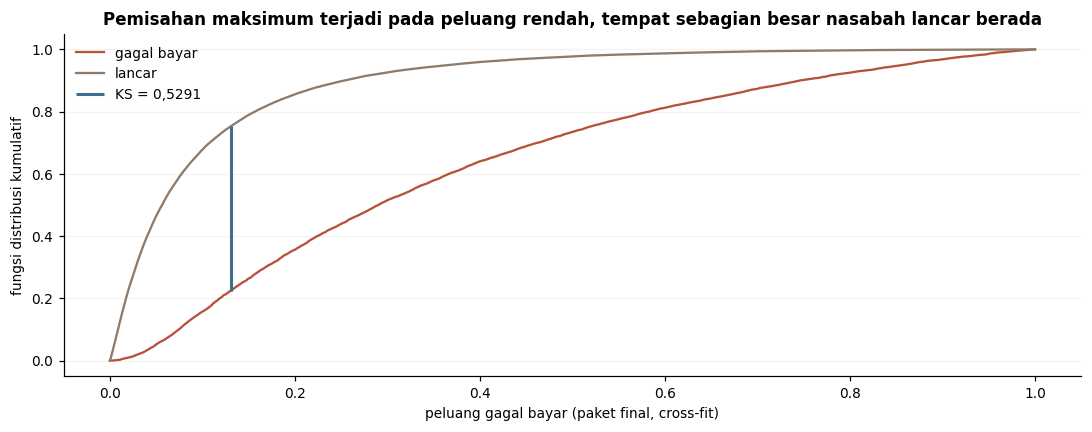

**Paket final per segmen: desil dan konsistensi KS–AUC**

,segmen,AUC,KS,Gini,batas atas KS(2 − KS),default desil 1,default desil 10,rasio desil 10/1
0,semua,"0,8487","0,5291","0,6973","0,7782","0,0039","0,5534","143,4815"
1,berhistori,"0,8542","0,5423","0,7085","0,7905","0,0033","0,5849","179,1250"
2,thin-file,"0,8317","0,5010","0,6635","0,7510","0,0038","0,4624","121,3750"


Bab 15 selesai: 0,0 menit
total run: 119,3 menit


In [44]:
FINAL_CF = G_CF if LOLOS else S7_CF
grid = np.linspace(0, 1, 1001)
F1 = np.searchsorted(np.sort(FINAL_CF[y == 1]), grid, side='right') / (y == 1).sum()
F0 = np.searchsorted(np.sort(FINAL_CF[y == 0]), grid, side='right') / (y == 0).sum()
k_max = int(np.argmax(F0 - F1))
fig, ax = plt.subplots()
ax.plot(grid, F1, label='gagal bayar', color=PALET['aksen1']); ax.plot(grid, F0, label='lancar', color=PALET['utama'])
ax.vlines(grid[k_max], F1[k_max], F0[k_max], color=PALET['aksen2'], lw=2, label=f'KS = {angka_id(float(F0[k_max] - F1[k_max]))}')
ax.set_xlabel('peluang gagal bayar (paket final, cross-fit)'); ax.set_ylabel('fungsi distribusi kumulatif'); ax.legend()
ax.set_title('Pemisahan maksimum terjadi pada peluang rendah, tempat sebagian besar nasabah lancar berada')
plt.tight_layout(); plt.show()
dec_rows = []
for seg, m in SEGS:
    q = pd.qcut(pd.Series(FINAL_CF[m]).rank(method='first'), 10, labels=False)
    dr = pd.Series(y[m]).groupby(q.to_numpy()).mean()
    auc_s, ks_s = roc_auc_score(y[m], FINAL_CF[m]), ks_stat(y[m], FINAL_CF[m])
    dec_rows.append((seg, auc_s, ks_s, 2 * auc_s - 1, ks_s * (2 - ks_s), dr.iloc[0], dr.iloc[-1], dr.iloc[-1] / max(dr.iloc[0], 1e-9)))
tampil_tabel(pd.DataFrame(dec_rows, columns=['segmen', 'AUC', 'KS', 'Gini', 'batas atas KS(2 − KS)', 'default desil 1', 'default desil 10', 'rasio desil 10/1']),
             'Paket final per segmen: desil dan konsistensi KS–AUC')
selesai_bab('Bab 15')
catat(f'total run: {angka_id((time.time() - RUN_T0) / 60, 1)} menit')

> ### Insights
>
> <<INS_14_1>>

## 15.2 Kelebihan <a name="bab15-2"></a>

- Fitur dibangun dari mekanisme pembentuk risiko (harga risiko, efek harga nasabah, antrian tunggakan), dan setiap keluarga diterima hanya lewat DeLong z > 2.
- Pipeline final dijalankan dari data mentah tanpa *cache* dan direproduksi terhadap berkas yang dikirim (§9.3).
- Audit kebocoran 48 uji dipra-registrasi, dengan kontrol daya untuk setiap alat (Bab 10).
- Semua keputusan diambil dari OOF; skor publik tidak dipakai untuk memilih maupun membobot.

## 15.3 Keterbatasan <a name="bab15-3"></a>

- **Plafon informasi.** Kurva belajar memberi asimtot model tunggal ±0,854; nasabah *thin-file* tertinggal ±0,02 AUC karena informasi, bukan estimasi (run terdahulu, CLAUDE.md Pencarian Informasi Pasca-S5).
- **Batas Su–Liu.** Anggota baru dengan AUC solo lebih rendah dan korelasi peringkat ≥ 0,97 hanya dapat menambah paling banyak beberapa per sepuluh ribu AUC; realisasinya 29–39% dari batas (CLAUDE.md Submission 8, publik s4nn).
- **Subagging.** Rata-rata model *fold* sudah memakai seluruh data, sehingga *refit* 100% tidak menambah apa pun (ΔAUC −0,00008, z −1,30; CLAUDE.md Bagian 27).
- **Stacker.** Biaya AIC 12 koefisien setara informasi *thin* yang tersedia, sehingga *stacker* level-2 merugikan (z −2,24; CLAUDE.md Bagian 25).
- **Skor publik.** 0,61 setara AUC ±0,871, di atas asimtot; paling mungkin derau subset 9.000 baris ditambah seleksi antartim (CLAUDE.md Bagian 26).
- Koreksi angkatan keputusan hanya sah untuk periode yang sama dengan data latih.

## 15.4 Arah <a name="bab15-4"></a>

- Penyaringan informasi baru memakai uji skor gabungan, bukan penyaring residual LightGBM, karena hanya yang pertama terbukti berdaya untuk sinyal berukuran S7 (Bab 10).
- Celah *thin-file* adalah satu-satunya celah besar yang tersisa; sumber berikutnya yang layak adalah komposisi belanja per kategori dalam jendela pendek, digeneralisasi dari temuan *groceries*.
- <<ARAH_GROC>>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 16. Daftar Pustaka <a name="bab16"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<<PUSTAKA: hanya rujukan terverifikasi di CLAUDE.md dan berkas riset yang disebut di bab notebook ini; daftar diusulkan di laporan kerangka>>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# 17. Ucapan Terima Kasih <a name="bab17"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Terima kasih kepada panitia LOGIKA UI 2026 atas data dan kompetisinya, serta kepada para juri yang telah membaca notebook ini.